# Patient Health Risk Prediction System Using Machine Learning

### 1. Business Understanding

**Business Problem:**
Hospitals need to identify patients who are at high health risk so that doctors can give them earlier attention and treatment.

### 2 .Economic Problem:

Early identification of high-risk patients can help reduce treatment costs, emergency expenses, and unnecessary hospital resources.

### 3. ML Success Criteria

- Recall ≥ 80% → Identify at least 80% of high-risk patients.
- F1-score ≥ 80% → Maintain a good balance between precision and recall.
- ROC-AUC ≥ 0.80 → Effectively distinguish between high-risk and low-risk patients.

### 4. Economic Success Criteria

- Reduce healthcare costs → Reduce unnecessary treatment and emergency-care expenses by identifying high-risk patients early.
- Reduce resource usage → Help hospitals use doctors, beds, and medical resources more efficiently.
- Reduce complications → Reduce costly health complications through early identification and intervention.

# CRISP-ML(Q) Methodology

| Step | Description |
|---|---|
| 1. Business & Data Understanding: | Understand the healthcare problem and inspect the raw patient dataset |
| 2. Data Preparation: | Handle missing values, duplicates, invalid values, inconsistent values, outliers, and categorical variables |
| 3. Feature Engineering: | Create useful features from existing patient information |
| 4. Model Engineering: | Train ML classification models such as Logistic Regression, Decision Tree, Random Forest, XGBoost, etc. |
| 5. Model Evaluation: | Compare models using Accuracy, Precision, Recall, F1-score, ROC-AUC and Confusion Matrix |
| 6. Model Deployment: | Deploy the best model using FastAPI/Streamlit |
| 7. Monitoring & Maintenance: | Monitor model performance and retrain when new patient data becomes available |

In [1]:
# import required libraries
# Data Handling
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer

# Feature Selection
from sklearn.feature_selection import SelectKBest, chi2, RFE

# ML Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Imbalanced Data
from imblearn.over_sampling import SMOTE

# Warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
# load the dataset
raw_df = pd.read_csv("Patient_Health_Records_Raw.csv")

In [3]:
# 1. Check dataset shape
raw_df.shape

(10000, 17)

In [4]:
# 2. Check first rows
raw_df.head()

,Patient_ID,Name,Age,Gender,City,BMI,Blood_Pressure,Heart_Rate,Cholesterol_Level,Diabetic,Smoker,Medications,Last_Visit_Date,Follow_Up,Diagnosis_Code,Notes,Has_Disease
0,ID-00001,"SMITH, ALICE",250,Unknown,Boston,22kg/m2,120 over 80,83,190,Unknown,yes,NaN,Apr 15 2021,30,A00,Patient feeling fine 🙂,0
1,ID-00002,"SMITH, ALICE",-5,FEMALE,newyork,25.8,NaN,500,normal,N,No,NaN,2021-07-10,NaN,unknown,"BP high, needs recheck",unknown
2,ID-00003,John Doe,-5,NaN,Nwe Yrok,22kg/m2,120 - 80,500,190,no,Former,"aspirin,metformin",Apr 06 2021,30,B20,NaN,unknown
3,ID-00004,michael brown,80,F,New York,33.4,NaN,eighty,250,y,EX-smoker,NaN,20241113,30,NaN,Follow up soon,unknown
4,ID-00005,Jane Doe,250,male,la,30.1,120 over 80,0,normal,no,No,NaN,2025-09-27,NaN,I10,Patient feeling fine 🙂,1


In [5]:
# 3. Check column names
raw_df.columns

Index(['Patient_ID', 'Name', 'Age', 'Gender', 'City', 'BMI', 'Blood_Pressure',
       'Heart_Rate', 'Cholesterol_Level', 'Diabetic', 'Smoker', 'Medications',
       'Last_Visit_Date', 'Follow_Up', 'Diagnosis_Code', 'Notes',
       'Has_Disease'],
      dtype='object')

# Drop unwanted columns which is not for analysis

In [6]:
# Drop unwanted columns
raw_df = raw_df.drop(columns=["Patient_ID", "Name", ])

In [7]:
# 4. Check data types
raw_df.dtypes

Age                  object
Gender               object
City                 object
BMI                  object
Blood_Pressure       object
Heart_Rate           object
Cholesterol_Level    object
Diabetic             object
Smoker               object
Medications          object
Last_Visit_Date      object
Follow_Up            object
Diagnosis_Code       object
Notes                object
Has_Disease          object
dtype: object

In [8]:
raw_df["Has_Disease"].value_counts(dropna=False)

Has_Disease
NaN        2520
0          2513
unknown    2506
1          2461
Name: count, dtype: int64

In [9]:
(raw_df["Has_Disease"].astype(str).str.lower() == "unknown").sum()

np.int64(2506)

In [10]:
# Check original Cholesterol_Level values

raw_df["Cholesterol_Level"].unique()

array(['190', 'normal', '250', 'high', nan], dtype=object)

In [11]:
# Count each value including missing values

raw_df["Cholesterol_Level"].value_counts(dropna=False)

Cholesterol_Level
NaN       2052
190       2048
normal    1994
250       1970
high      1936
Name: count, dtype: int64

In [12]:
# 6. Check missing values
raw_df.isnull().sum()

Age                     0
Gender               1707
City                 1003
BMI                  2418
Blood_Pressure       2030
Heart_Rate              0
Cholesterol_Level    2052
Diabetic             1641
Smoker               3234
Medications          4024
Last_Visit_Date         0
Follow_Up            2524
Diagnosis_Code       1675
Notes                4024
Has_Disease          2520
dtype: int64

In [13]:
# Remove NaN and unknown values from Has_Disease
raw_df = raw_df[
    (raw_df["Has_Disease"].astype(str).str.lower() != "unknown") &
    (raw_df["Has_Disease"].notna())
].reset_index(drop=True)

# Check the new index
print(raw_df.index)

RangeIndex(start=0, stop=4974, step=1)


In [14]:
# 1. Check dataset shape
raw_df.shape

(4974, 15)

In [15]:
# 6. Check missing values
raw_df.isnull().sum()

Age                     0
Gender                830
City                  540
BMI                  1205
Blood_Pressure       1032
Heart_Rate              0
Cholesterol_Level    1031
Diabetic              821
Smoker               1598
Medications          1986
Last_Visit_Date         0
Follow_Up            1272
Diagnosis_Code        864
Notes                2046
Has_Disease             0
dtype: int64

In [16]:
# Count each value including missing values

raw_df["Cholesterol_Level"].value_counts(dropna=False)

Cholesterol_Level
NaN       1031
190       1024
normal    1016
250        974
high       929
Name: count, dtype: int64

# Splitting cholestral level in to two columns

In [17]:
# Create numeric cholesterol column
raw_df["Cholesterol_Value"] = pd.to_numeric(
    raw_df["Cholesterol_Level"], errors="coerce"
).astype("Int64")

# Create categorical cholesterol column
raw_df["Cholesterol_Status"] = (
    raw_df["Cholesterol_Level"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Keep only valid categorical values
raw_df["Cholesterol_Status"] = raw_df["Cholesterol_Status"].where(
    raw_df["Cholesterol_Status"].isin(["normal", "high"]),
    pd.NA
)

# Type casting

In [18]:
# ============================================================
# Convert columns to their appropriate data types
# ============================================================

# Age → nullable integer
raw_df["Age"] = pd.to_numeric(
    raw_df["Age"], errors="coerce"
).astype("Int64")


# BMI → nullable float
raw_df["BMI"] = pd.to_numeric(
    raw_df["BMI"], errors="coerce"
).astype("Float64")


# Heart Rate → nullable integer
raw_df["Heart_Rate"] = pd.to_numeric(
    raw_df["Heart_Rate"], errors="coerce"
).astype("Int64")


# Cholesterol_Value → nullable integer
raw_df["Cholesterol_Value"] = pd.to_numeric(
    raw_df["Cholesterol_Value"], errors="coerce"
).astype("Int64")


# Cholesterol_Status → string
raw_df["Cholesterol_Status"] = (
    raw_df["Cholesterol_Status"].astype("string")
)


# Follow Up → nullable integer
raw_df["Follow_Up"] = pd.to_numeric(
    raw_df["Follow_Up"], errors="coerce"
).astype("Int64")


# Blood Pressure → string
raw_df["Blood_Pressure"] = (
    raw_df["Blood_Pressure"]
    .astype("string")
    .str.strip()
)


# Last Visit Date → datetime
raw_df["Last_Visit_Date"] = pd.to_datetime(
    raw_df["Last_Visit_Date"], errors="coerce"
)


# Has_Disease → nullable integer
raw_df["Has_Disease"] = pd.to_numeric(
    raw_df["Has_Disease"], errors="coerce"
).astype("Int64")


# ============================================================
# Convert categorical columns to object
# ============================================================

categorical_cols = [
    "Gender",
    "City",
    "Blood_Pressure",
    "Diabetic",
    "Smoker",
    "Medications",
    "Diagnosis_Code",
    "Notes",
    "Cholesterol_Status"
]

raw_df[categorical_cols] = raw_df[categorical_cols].astype("object")




In [19]:
# ============================================================
# Check final data types
# ============================================================

print(raw_df.dtypes)

Age                            Int64
Gender                        object
City                          object
BMI                          Float64
Blood_Pressure                object
Heart_Rate                     Int64
Cholesterol_Level             object
Diabetic                      object
Smoker                        object
Medications                   object
Last_Visit_Date       datetime64[ns]
Follow_Up                      Int64
Diagnosis_Code                object
Notes                         object
Has_Disease                    Int64
Cholesterol_Value              Int64
Cholesterol_Status            object
dtype: object


In [20]:
raw_df.head()

,Age,Gender,City,BMI,Blood_Pressure,Heart_Rate,Cholesterol_Level,Diabetic,Smoker,Medications,Last_Visit_Date,Follow_Up,Diagnosis_Code,Notes,Has_Disease,Cholesterol_Value,Cholesterol_Status
0,250,Unknown,Boston,<NA>,120 over 80,83,190,Unknown,yes,NaN,2021-04-15,30,A00,Patient feeling fine 🙂,0,190,<NA>
1,250,male,la,30.1,120 over 80,0,normal,no,No,NaN,NaT,<NA>,I10,Patient feeling fine 🙂,1,<NA>,normal
2,-5,Unknown,NaN,<NA>,120 - 80,63,normal,no,EX-smoker,NaN,NaT,30,E11.9,NaN,0,<NA>,normal
3,250,NaN,Boston,<NA>,120 over 80,500,high,N,Former,Aspirin; Metformin,NaT,30,unknown,NaN,0,<NA>,high
4,-5,Unknown,Chicago,21.5,<NA>,<NA>,NaN,no,Former,NaN,NaT,30,A00,"BP high, needs recheck",1,<NA>,<NA>


In [21]:
# 5. Check dataset information
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4974 entries, 0 to 4973
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Age                 3746 non-null   Int64         
 1   Gender              4144 non-null   object        
 2   City                4434 non-null   object        
 3   BMI                 2545 non-null   Float64       
 4   Blood_Pressure      3942 non-null   object        
 5   Heart_Rate          3751 non-null   Int64         
 6   Cholesterol_Level   3943 non-null   object        
 7   Diabetic            4153 non-null   object        
 8   Smoker              3376 non-null   object        
 9   Medications         2988 non-null   object        
 10  Last_Visit_Date     1212 non-null   datetime64[ns]
 11  Follow_Up           2425 non-null   Int64         
 12  Diagnosis_Code      4110 non-null   object        
 13  Notes               2928 non-null   object      

In [22]:
# 6. Check missing values
raw_df.isnull().sum()

Age                   1228
Gender                 830
City                   540
BMI                   2429
Blood_Pressure        1032
Heart_Rate            1223
Cholesterol_Level     1031
Diabetic               821
Smoker                1598
Medications           1986
Last_Visit_Date       3762
Follow_Up             2549
Diagnosis_Code         864
Notes                 2046
Has_Disease              0
Cholesterol_Value     2976
Cholesterol_Status    3029
dtype: int64

In [23]:
raw_df["Has_Disease"].value_counts()

Has_Disease
0    2513
1    2461
Name: count, dtype: Int64

In [24]:
raw_df["Has_Disease"].value_counts(normalize=True) * 100

Has_Disease
0    50.522718
1    49.477282
Name: proportion, dtype: Float64

In [25]:
raw_df["Has_Disease"].value_counts(dropna=False)

Has_Disease
0    2513
1    2461
Name: count, dtype: Int64

In [26]:
(raw_df["Has_Disease"].astype(str).str.lower() == "unknown").sum()

np.int64(0)

In [27]:
# 6. Check missing values
raw_df.isnull().sum()

Age                   1228
Gender                 830
City                   540
BMI                   2429
Blood_Pressure        1032
Heart_Rate            1223
Cholesterol_Level     1031
Diabetic               821
Smoker                1598
Medications           1986
Last_Visit_Date       3762
Follow_Up             2549
Diagnosis_Code         864
Notes                 2046
Has_Disease              0
Cholesterol_Value     2976
Cholesterol_Status    3029
dtype: int64

In [28]:
# Remove unwanted spaces from all string/object columns
for col in raw_df.select_dtypes(include="object").columns:
    raw_df[col] = raw_df[col].str.strip()

In [29]:
# Fix invalid Age values
# Keep only realistic ages (0–120); invalid values become NaN

raw_df["Age"] = pd.to_numeric(raw_df["Age"], errors="coerce")
raw_df.loc[(raw_df["Age"] < 0) | (raw_df["Age"] > 120), "Age"] = np.nan

In [30]:
# Standardize Gender categories

raw_df["Gender"] = raw_df["Gender"].str.strip().str.lower()

raw_df["Gender"] = raw_df["Gender"].replace({
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female": "Female",
    "unknown": np.nan
})

In [31]:
# Standardize City names

raw_df["City"] = (
    raw_df["City"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Combine different city formats
raw_df["City"] = raw_df["City"].replace({
    "la": "Los Angeles",
    "los angeles": "Los Angeles",
    
    "ny": "New York",
    "new york": "New York",
    "newyork": "New York",
    "nwe yrok": "New York"
})

# Correct capitalization of remaining city names
raw_df["City"] = raw_df["City"].str.title()

In [32]:
# Clean and convert BMI to numeric

raw_df["BMI"] = (
    raw_df["BMI"]
    .astype("string")
    .str.replace("kg/m2", "", regex=False)
    .str.strip()
)

raw_df["BMI"] = pd.to_numeric(raw_df["BMI"], errors="coerce")

In [33]:
# Standardize Blood_Pressure format

raw_df["Blood_Pressure"] = (
    raw_df["Blood_Pressure"]
    .astype("string")
    .str.strip()
    .str.replace(" over ", "/", regex=False)
    .str.replace(" - ", "/", regex=False)
)

# Convert common missing-value representations to np.nan
raw_df = raw_df.replace(
    ["N/A", "NA", "n/a", "na", ""],
    np.nan
)

# Split Blood_Pressure into two columns
raw_df[["Systolic_BP", "Diastolic_BP"]] = (
    raw_df["Blood_Pressure"]
    .str.split("/", n=1, expand=True)
)

# Convert both columns to numeric
raw_df["Systolic_BP"] = pd.to_numeric(
    raw_df["Systolic_BP"], errors="coerce"
)

raw_df["Diastolic_BP"] = pd.to_numeric(
    raw_df["Diastolic_BP"], errors="coerce"
)

In [34]:
# Clean and convert Heart_Rate to numeric

raw_df["Heart_Rate"] = pd.to_numeric(
    raw_df["Heart_Rate"], errors="coerce"
)

# Replace invalid Heart_Rate values with NaN

raw_df.loc[
    (raw_df["Heart_Rate"] <= 0) | (raw_df["Heart_Rate"] > 200),
    "Heart_Rate"
] = np.nan

In [35]:
# Standardize Diabetic categories

raw_df["Diabetic"] = (
    raw_df["Diabetic"]
    .astype("string")
    .str.strip()
    .str.lower()
)

raw_df["Diabetic"] = raw_df["Diabetic"].replace({
    "y": "Yes",
    "yes": "Yes",
    "n": "No",
    "no": "No",
    "unknown": np.nan
})

In [36]:
# Standardize Smoker categories

raw_df["Smoker"] = (
    raw_df["Smoker"]
    .astype("string")
    .str.strip()
    .str.lower()
)

raw_df["Smoker"] = raw_df["Smoker"].replace({
    "yes": "Yes",
    "no": "No",
    "former": "Former",
    "ex-smoker": "Former",
    "n/a": np.nan
})

In [37]:
# Standardize Medications

raw_df["Medications"] = (
    raw_df["Medications"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Standardize separators
raw_df["Medications"] = (
    raw_df["Medications"]
    .str.replace(",", ";", regex=False)
    .str.replace("/", ";", regex=False)
)

# Standardize spaces around ;
raw_df["Medications"] = (
    raw_df["Medications"]
    .str.replace(r"\s*;\s*", "; ", regex=True)
)

# Convert None / N/A to NaN
raw_df["Medications"] = raw_df["Medications"].replace(
    ["none", "n/a", "na", ""], np.nan
)

# Standardize medication names
raw_df["Medications"] = raw_df["Medications"].str.title()

In [38]:
# Clean and convert Last_Visit_Date to datetime

raw_df["Last_Visit_Date"] = (
    raw_df["Last_Visit_Date"]
    .astype("string")
    .str.strip()
)

# Convert different date formats
raw_df["Last_Visit_Date"] = pd.to_datetime(
    raw_df["Last_Visit_Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

In [39]:
# Clean Follow_Up

raw_df["Follow_Up"] = (
    raw_df["Follow_Up"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convert text value to number of days
raw_df["Follow_Up"] = raw_df["Follow_Up"].replace({
    "two weeks": "14"
})

# Convert to numeric
raw_df["Follow_Up"] = pd.to_numeric(
    raw_df["Follow_Up"], errors="coerce"
)

In [40]:
# Standardize Diagnosis_Code

raw_df["Diagnosis_Code"] = (
    raw_df["Diagnosis_Code"]
    .astype("string")
    .str.strip()
)

raw_df["Diagnosis_Code"] = raw_df["Diagnosis_Code"].replace({
    "unknown": np.nan,
    "Unknown": np.nan,
    "N/A": np.nan,
    "n/a": np.nan,
    "": np.nan
})

In [41]:
# Clean Notes

raw_df["Notes"] = (
    raw_df["Notes"]
    .astype("string")
    .str.strip()
)

# Convert missing-value indicators to NaN
raw_df["Notes"] = raw_df["Notes"].replace({
    "n/a": np.nan,
    "N/A": np.nan,
    "na": np.nan,
    "NA": np.nan,
    "": np.nan
})

In [42]:
# Clean Has_Disease target

raw_df["Has_Disease"] = (
    raw_df["Has_Disease"]
    .astype("string")
    .str.strip()
)

# Convert unknown and missing values to NaN
raw_df["Has_Disease"] = raw_df["Has_Disease"].replace({
    "unknown": np.nan,
    "Unknown": np.nan,
    "": np.nan,
    "N/A": np.nan,
    "n/a": np.nan
})

# Convert valid 0 and 1 to numeric
raw_df["Has_Disease"] = pd.to_numeric(
    raw_df["Has_Disease"], errors="coerce"
)

# Remove rows where the target is missing
raw_df = raw_df.dropna(subset=["Has_Disease"])

# Convert target to integer
raw_df["Has_Disease"] = raw_df["Has_Disease"].astype(int)

In [43]:
# Keep original Blood_Pressure column

# Convert Systolic BP to numeric
raw_df["Systolic_BP"] = pd.to_numeric(
    raw_df["Systolic_BP"], errors="coerce"
).astype("Int64")

# Convert Diastolic BP to numeric
raw_df["Diastolic_BP"] = pd.to_numeric(
    raw_df["Diastolic_BP"], errors="coerce"
).astype("Int64")

In [44]:
# Validate and convert Blood Pressure columns to numeric

raw_df["Systolic_BP"] = pd.to_numeric(
raw_df["Systolic_BP"], errors="coerce"
)

raw_df["Diastolic_BP"] = pd.to_numeric(
    raw_df["Diastolic_BP"], errors="coerce"
)

In [45]:
# Check data types

raw_df[["Systolic_BP", "Diastolic_BP"]].dtypes

Systolic_BP     Int64
Diastolic_BP    Int64
dtype: object

In [46]:
raw_df.head()

,Age,Gender,City,BMI,Blood_Pressure,Heart_Rate,Cholesterol_Level,Diabetic,Smoker,Medications,Last_Visit_Date,Follow_Up,Diagnosis_Code,Notes,Has_Disease,Cholesterol_Value,Cholesterol_Status,Systolic_BP,Diastolic_BP
0,<NA>,NaN,Boston,<NA>,120/80,83,190,<NA>,Yes,<NA>,2021-04-15,30,A00,Patient feeling fine 🙂,0,190,<NA>,120,80
1,<NA>,Male,Los Angeles,30.1,120/80,<NA>,normal,No,No,<NA>,NaT,<NA>,I10,Patient feeling fine 🙂,1,<NA>,normal,120,80
2,<NA>,NaN,<NA>,<NA>,120/80,63,normal,No,Former,<NA>,NaT,30,E11.9,<NA>,0,<NA>,normal,120,80
3,<NA>,NaN,Boston,<NA>,120/80,<NA>,high,No,Former,Aspirin; Metformin,NaT,30,<NA>,<NA>,0,<NA>,high,120,80
4,<NA>,NaN,Chicago,21.5,<NA>,<NA>,NaN,No,Former,<NA>,NaT,30,A00,"BP high, needs recheck",1,<NA>,<NA>,<NA>,<NA>


In [47]:
# Check value counts of Cholesterol_Status

raw_df["Cholesterol_Status"].value_counts(dropna=False)

Cholesterol_Status
<NA>      3029
normal    1016
high       929
Name: count, dtype: int64

In [48]:
raw_df["Cholesterol_Status"].unique()

array([<NA>, 'normal', 'high'], dtype=object)

In [49]:
# Check value counts of Cholesterol_Status

raw_df["Cholesterol_Value"].value_counts(dropna=False)

Cholesterol_Value
<NA>    2976
190     1024
250      974
Name: count, dtype: Int64

In [50]:
raw_df["Cholesterol_Value"].unique()

<IntegerArray>
[190, <NA>, 250]
Length: 3, dtype: Int64

In [51]:
raw_df.shape

(4974, 19)

In [52]:
# Check column names

raw_df.columns.tolist()

['Age',
 'Gender',
 'City',
 'BMI',
 'Blood_Pressure',
 'Heart_Rate',
 'Cholesterol_Level',
 'Diabetic',
 'Smoker',
 'Medications',
 'Last_Visit_Date',
 'Follow_Up',
 'Diagnosis_Code',
 'Notes',
 'Has_Disease',
 'Cholesterol_Value',
 'Cholesterol_Status',
 'Systolic_BP',
 'Diastolic_BP']

In [53]:
# Check data types

raw_df.dtypes

Age                            Int64
Gender                        object
City                  string[python]
BMI                          Float64
Blood_Pressure        string[python]
Heart_Rate                     Int64
Cholesterol_Level             object
Diabetic              string[python]
Smoker                string[python]
Medications           string[python]
Last_Visit_Date       datetime64[ns]
Follow_Up                      Int64
Diagnosis_Code        string[python]
Notes                 string[python]
Has_Disease                    int64
Cholesterol_Value              Int64
Cholesterol_Status            object
Systolic_BP                    Int64
Diastolic_BP                   Int64
dtype: object

In [54]:
# Convert all categorical columns to object

categorical_cols = [
    "Gender",
    "City",
    "Diabetic",
    "Smoker",
    "Medications",
    "Diagnosis_Code",
    "Notes",
    "Cholesterol_Status"
]

raw_df[categorical_cols] = raw_df[categorical_cols].astype("object")

In [55]:
# Check data types

raw_df.dtypes

Age                            Int64
Gender                        object
City                          object
BMI                          Float64
Blood_Pressure        string[python]
Heart_Rate                     Int64
Cholesterol_Level             object
Diabetic                      object
Smoker                        object
Medications                   object
Last_Visit_Date       datetime64[ns]
Follow_Up                      Int64
Diagnosis_Code                object
Notes                         object
Has_Disease                    int64
Cholesterol_Value              Int64
Cholesterol_Status            object
Systolic_BP                    Int64
Diastolic_BP                   Int64
dtype: object

In [56]:
# 7. Check duplicate rows
raw_df.duplicated().sum()

np.int64(3)

In [57]:
# Remove duplicate rows
raw_df = raw_df.drop_duplicates()

In [58]:
raw_df.duplicated().sum()

np.int64(0)

In [59]:
raw_df["Has_Disease"].value_counts()

Has_Disease
0    2512
1    2459
Name: count, dtype: int64

In [60]:
# Create a working copy of the cleaned dataset
df = raw_df.copy()

In [61]:
df.head()

,Age,Gender,City,BMI,Blood_Pressure,Heart_Rate,Cholesterol_Level,Diabetic,Smoker,Medications,Last_Visit_Date,Follow_Up,Diagnosis_Code,Notes,Has_Disease,Cholesterol_Value,Cholesterol_Status,Systolic_BP,Diastolic_BP
0,<NA>,NaN,Boston,<NA>,120/80,83,190,<NA>,Yes,<NA>,2021-04-15,30,A00,Patient feeling fine 🙂,0,190,<NA>,120,80
1,<NA>,Male,Los Angeles,30.1,120/80,<NA>,normal,No,No,<NA>,NaT,<NA>,I10,Patient feeling fine 🙂,1,<NA>,normal,120,80
2,<NA>,NaN,<NA>,<NA>,120/80,63,normal,No,Former,<NA>,NaT,30,E11.9,<NA>,0,<NA>,normal,120,80
3,<NA>,NaN,Boston,<NA>,120/80,<NA>,high,No,Former,Aspirin; Metformin,NaT,30,<NA>,<NA>,0,<NA>,high,120,80
4,<NA>,NaN,Chicago,21.5,<NA>,<NA>,NaN,No,Former,<NA>,NaT,30,A00,"BP high, needs recheck",1,<NA>,<NA>,<NA>,<NA>


# Segregate Quan, Qual, Date columns

In [62]:
def quanQual(df):
    quan = []
    qual = []
    date = []

    for columnName in df.columns:

        if columnName == "Last_Visit_Date":
            date.append(columnName)

        elif df[columnName].dtype == 'O':
            qual.append(columnName)

        else:
            quan.append(columnName)

    return quan, qual, date


# Call the function
quan, qual, date = quanQual(df)

print("Quantitative:", quan)
print("Qualitative:", qual)
print("Date:", date)

Quantitative: ['Age', 'BMI', 'Blood_Pressure', 'Heart_Rate', 'Follow_Up', 'Has_Disease', 'Cholesterol_Value', 'Systolic_BP', 'Diastolic_BP']
Qualitative: ['Gender', 'City', 'Cholesterol_Level', 'Diabetic', 'Smoker', 'Medications', 'Diagnosis_Code', 'Notes', 'Cholesterol_Status']
Date: ['Last_Visit_Date']


In [63]:
# remove the column Blood_Pressure as it splitted and the data type is as string
quan.remove("Blood_Pressure")

In [64]:
quan

['Age',
 'BMI',
 'Heart_Rate',
 'Follow_Up',
 'Has_Disease',
 'Cholesterol_Value',
 'Systolic_BP',
 'Diastolic_BP']

In [65]:
qual

['Gender',
 'City',
 'Cholesterol_Level',
 'Diabetic',
 'Smoker',
 'Medications',
 'Diagnosis_Code',
 'Notes',
 'Cholesterol_Status']

# Univariate analysis on Numerical data

In [66]:
# creating function for descriptive statistics
def univariate(df,quan):
    descriptive = pd.DataFrame(index = ["mean", "median", "mode", "Q1:25%", "Q2:50%", "Q3:75%", "Q4:100%", 
                                        "99%", "IQR", "1.5rule", "Lesser", "Greater", "Min", "Max", "skewness", "Kurtosis", "var", "std" ], columns = quan)
    for ColumnName in quan:
        descriptive[ColumnName]["mean"] = df[ColumnName].mean() 
        descriptive[ColumnName]["median"] = df[ColumnName].median()
        descriptive[ColumnName]["mode"] = df[ColumnName].mode()[0]
        descriptive[ColumnName]["Q1:25%"] = df.describe()[ColumnName]["25%"]
        descriptive[ColumnName]["Q2:50%"] = df.describe()[ColumnName]["50%"]
        descriptive[ColumnName]["Q3:75%"] = df.describe()[ColumnName]["75%"]
        descriptive[ColumnName]["Q4:100%"] = df.describe()[ColumnName]["max"]
        descriptive[ColumnName]["99%"] = np.percentile(df[ColumnName].dropna(), 99)
        descriptive[ColumnName]["IQR"] = descriptive[ColumnName]["Q3:75%"] - descriptive[ColumnName]["Q1:25%"]
        descriptive[ColumnName]["1.5rule"] = 1.5 * descriptive[ColumnName]["IQR"]
        descriptive[ColumnName]["Lesser"] = descriptive[ColumnName]["Q1:25%"] - descriptive[ColumnName]["1.5rule"]
        descriptive[ColumnName]["Greater"] = descriptive[ColumnName]["Q3:75%"] + descriptive[ColumnName]["1.5rule"]
        descriptive[ColumnName]["Min"] = df[ColumnName].min()
        descriptive[ColumnName]["Max"] = df[ColumnName].max()
        descriptive[ColumnName]["skewness"] = df[ColumnName].skew()
        descriptive[ColumnName]["Kurtosis"] = df[ColumnName].kurtosis()
        descriptive[ColumnName]["var"] = df[ColumnName].var()
        descriptive[ColumnName]["std"] = df[ColumnName].std()
    
    
    return descriptive
         

# 1. Overall numerical summary

In [67]:
univariate(df,quan)

,Age,BMI,Heart_Rate,Follow_Up,Has_Disease,Cholesterol_Value,Systolic_BP,Diastolic_BP
mean,49.137579,23.59336,85.039782,21.960396,0.494669,219.233851,121.228484,80.029195
median,50.0,22.5,85.0,14.0,0.0,190.0,120.0,80.0
mode,6,22.5,63,14,0,190,120,80
Q1:25%,23.0,22.5,67.0,14.0,0.0,190.0,120.0,80.0
Q2:50%,50.0,22.5,85.0,14.0,0.0,190.0,120.0,80.0
Q3:75%,75.0,24.5,103.0,30.0,1.0,250.0,120.0,80.0
Q4:100%,100.0,35.0,120.0,30.0,1.0,250.0,160.0,100.0
99%,99.0,34.6,120.0,30.0,1.0,250.0,157.0,99.0
IQR,52.0,2.0,36.0,16.0,1.0,60.0,0.0,0.0
1.5rule,78.0,3.0,54.0,24.0,1.5,90.0,0.0,0.0


In [68]:
df["Gender"].value_counts()

Gender
Female    1658
Male      1628
Name: count, dtype: int64

In [69]:
df["City"].value_counts()

City
New York       1990
Chicago        1020
Los Angeles     929
Boston          492
Name: count, dtype: int64

In [70]:
df["Diabetic"].value_counts()

Diabetic
No     1710
Yes    1612
Name: count, dtype: int64

In [71]:
df["Smoker"].value_counts()

Smoker
Former    1710
No         837
Yes        827
Name: count, dtype: int64

In [72]:
df["Medications"].value_counts()

Medications
Aspirin; Metformin       1970
Lisinopril; Metformin    1015
Name: count, dtype: int64

In [73]:
df["Diagnosis_Code"].value_counts()

Diagnosis_Code
B20      880
E11.9    813
I10      811
A00      777
Name: count, dtype: int64

In [74]:
df["Notes"].value_counts()

Notes
BP high, needs recheck    1018
Follow up soon             992
Patient feeling fine 🙂     917
Name: count, dtype: int64

In [75]:
df["Cholesterol_Status"].value_counts()

Cholesterol_Status
normal    1015
high       928
Name: count, dtype: int64

# Exploratory Dat Analysis

# 1st Moment Business Decision — Mean

## Mean tells you the average value of a numerical variable.
### 1.Mean
### 2.Median
### 3.Mode

In [76]:
# 1st Moment - Mean

print(df.mean(numeric_only=True))
print('\n')
print(df.median(numeric_only=True))
print('\n')
print(df.mode(numeric_only=True))
print('\n')

Age                   49.137579
BMI                    23.59336
Heart_Rate            85.039782
Follow_Up             21.960396
Has_Disease            0.494669
Cholesterol_Value    219.233851
Systolic_BP          121.228484
Diastolic_BP          80.029195
dtype: Float64


Age                   50.0
BMI                   22.5
Heart_Rate            85.0
Follow_Up             14.0
Has_Disease            0.0
Cholesterol_Value    190.0
Systolic_BP          120.0
Diastolic_BP          80.0
dtype: Float64


   Age   BMI  Heart_Rate  Follow_Up  Has_Disease  Cholesterol_Value  \
0    6  22.5          63         14            0                190   

   Systolic_BP  Diastolic_BP  
0          120            80  




# 2nd Moment Business Decision — Variance

## Variance tells you how much the values vary from the mean.
### 1.Variance
### 2.Standard deviation
### 3.Range

In [77]:
# 2nd Moment - Variance

print(df.var(numeric_only=True))
print('\n')

# standard deviation
print(df.std(numeric_only=True))
print('\n')

# Range = Maximum - Minimum
print(df.max(numeric_only=True) - df.min(numeric_only=True))

Age                  865.003087
BMI                   17.253623
Heart_Rate           420.058525
Follow_Up             64.024844
Has_Disease            0.250022
Cholesterol_Value    899.863623
Systolic_BP          111.099127
Diastolic_BP          36.926776
dtype: Float64


Age                  29.410935
BMI                   4.153748
Heart_Rate           20.495329
Follow_Up             8.001553
Has_Disease           0.500022
Cholesterol_Value    29.997727
Systolic_BP          10.540357
Diastolic_BP          6.076741
dtype: Float64


Age                  100.0
BMI                   20.0
Heart_Rate            70.0
Follow_Up             16.0
Has_Disease            1.0
Cholesterol_Value     60.0
Systolic_BP           70.0
Diastolic_BP          40.0
dtype: Float64


# 3rd Moment — Skewness

## Skewness tells you whether the data is symmetrically distributed or pulled toward one side.
### Measures of asymmetry in the data distribution

In [78]:
# 3rd Moment - Skewness

df.skew(numeric_only=True)

Age                  0.026033
BMI                   0.87853
Heart_Rate          -0.012391
Follow_Up            0.009907
Has_Disease          0.021331
Cholesterol_Value    0.051132
Systolic_BP          1.038878
Diastolic_BP        -0.057795
dtype: Float64

# 4th Moment — Kurtosis

## Kurtosis tells you whether the data contains more or fewer extreme values/outliers than a normal distribution.

### Measures of peakedness - represent the overall spread in the data

In [79]:
# 4th Moment - Kurtosis

df.kurtosis(numeric_only=True)

Age                  -1.24831
BMI                  0.733732
Heart_Rate          -1.186605
Follow_Up           -2.001554
Has_Disease          -2.00035
Cholesterol_Value   -1.999389
Systolic_BP          4.255029
Diastolic_BP         3.954965
dtype: Float64

# frequency/count and percentage analysis for categorical variables

In [80]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    print("\n", col)
    print("Frequency:")
    print(df[col].value_counts())
    
    print("Percentage:")
    print(df[col].value_counts(normalize=True) * 100)
    
    print("Mode:", df[col].mode()[0])
    print("Unique values:", df[col].nunique())


 Gender
Frequency:
Gender
Female    1658
Male      1628
Name: count, dtype: int64
Percentage:
Gender
Female    50.456482
Male      49.543518
Name: proportion, dtype: float64
Mode: Female
Unique values: 2

 City
Frequency:
City
New York       1990
Chicago        1020
Los Angeles     929
Boston          492
Name: count, dtype: int64
Percentage:
City
New York       44.910855
Chicago        23.019634
Los Angeles    20.965922
Boston         11.103588
Name: proportion, dtype: float64
Mode: New York
Unique values: 4

 Cholesterol_Level
Frequency:
Cholesterol_Level
190       1024
normal    1015
250        973
high       928
Name: count, dtype: int64
Percentage:
Cholesterol_Level
190       25.989848
normal    25.761421
250       24.695431
high      23.553299
Name: proportion, dtype: float64
Mode: 190
Unique values: 4

 Diabetic
Frequency:
Diabetic
No     1710
Yes    1612
Name: count, dtype: int64
Percentage:
Diabetic
No     51.475015
Yes    48.524985
Name: proportion, dtype: float64
Mode: No
U

In [81]:
# Check number of rows and columns

df.shape

(4971, 19)

In [82]:
# Date range

df["Last_Visit_Date"].agg(["min", "max"])

min   2020-01-01
max   2025-10-01
Name: Last_Visit_Date, dtype: datetime64[ns]

# 2. Check missing values

In [83]:
# Missing values in each column

df.isnull().sum()

Age                   3699
Gender                1685
City                   540
BMI                   2426
Blood_Pressure        1032
Heart_Rate            3689
Cholesterol_Level     1031
Diabetic              1649
Smoker                1597
Medications           1986
Last_Visit_Date       3759
Follow_Up             2547
Diagnosis_Code        1690
Notes                 2044
Has_Disease              0
Cholesterol_Value     2974
Cholesterol_Status    3028
Systolic_BP           1032
Diastolic_BP          1032
dtype: int64

In [84]:
# Missing-value percentage

(df.isnull().mean() * 100).sort_values(ascending=False)

Last_Visit_Date       75.618588
Age                   74.411587
Heart_Rate            74.210420
Cholesterol_Status    60.913297
Cholesterol_Value     59.826997
Follow_Up             51.237176
BMI                   48.803058
Notes                 41.118487
Medications           39.951720
Diagnosis_Code        33.997184
Gender                33.896600
Diabetic              33.172400
Smoker                32.126333
Diastolic_BP          20.760410
Blood_Pressure        20.760410
Systolic_BP           20.760410
Cholesterol_Level     20.740294
City                  10.863005
Has_Disease            0.000000
dtype: float64

# 3. Numerical columns — Value Counts
## For categorical variables

In [85]:
# Gender

df["Gender"].value_counts(dropna=False)

Gender
NaN       1685
Female    1658
Male      1628
Name: count, dtype: int64

In [86]:
# City

df["City"].value_counts(dropna=False)

City
New York       1990
Chicago        1020
Los Angeles     929
<NA>            540
Boston          492
Name: count, dtype: int64

In [87]:
# Diabetic

df["Diabetic"].value_counts(dropna=False)

Diabetic
No      1710
<NA>    1649
Yes     1612
Name: count, dtype: int64

In [88]:
# Smoker

df["Smoker"].value_counts(dropna=False)

Smoker
Former    1710
<NA>      1597
No         837
Yes        827
Name: count, dtype: int64

In [89]:
# Medications

df["Medications"].value_counts(dropna=False)

Medications
<NA>                     1986
Aspirin; Metformin       1970
Lisinopril; Metformin    1015
Name: count, dtype: int64

In [90]:
# Diagnosis Code

df["Diagnosis_Code"].value_counts(dropna=False)

Diagnosis_Code
<NA>     1690
B20       880
E11.9     813
I10       811
A00       777
Name: count, dtype: int64

In [91]:
# Cholesterol Status

df["Cholesterol_Status"].value_counts(dropna=False)

Cholesterol_Status
<NA>      3028
normal    1015
high       928
Name: count, dtype: int64

In [92]:
# Target variable

df["Has_Disease"].value_counts(dropna=False)

Has_Disease
0    2512
1    2459
Name: count, dtype: int64

# Visual represantation

# 4. Histograms for numerical variables

## Histograms show the distribution of one numerical variable.

In [93]:
sns.set_theme(style="whitegrid")

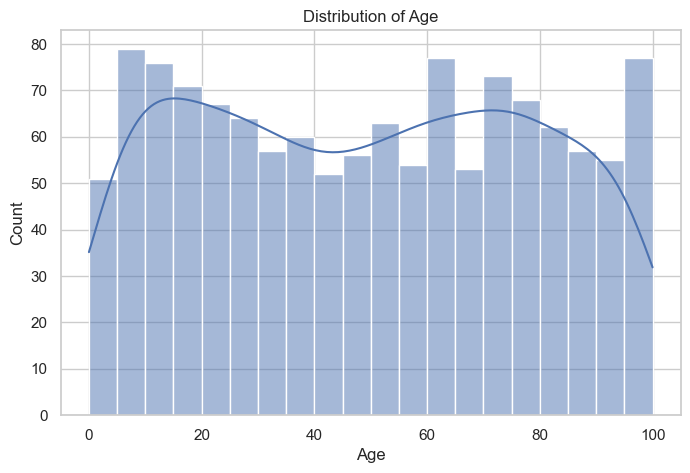

In [94]:
# Age
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", bins=20, kde=True)
plt.title("Distribution of Age")
plt.show()

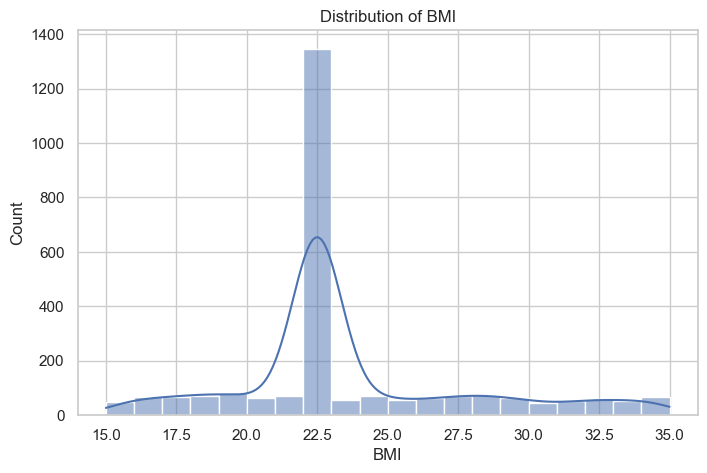

In [95]:
# BMI
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="BMI", bins=20, kde=True)
plt.title("Distribution of BMI")
plt.show()

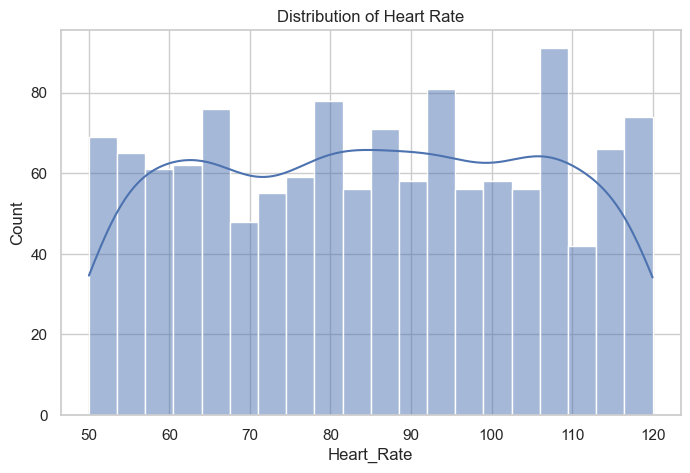

In [96]:
# Heart Rate
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Heart_Rate", bins=20, kde=True)
plt.title("Distribution of Heart Rate")
plt.show()

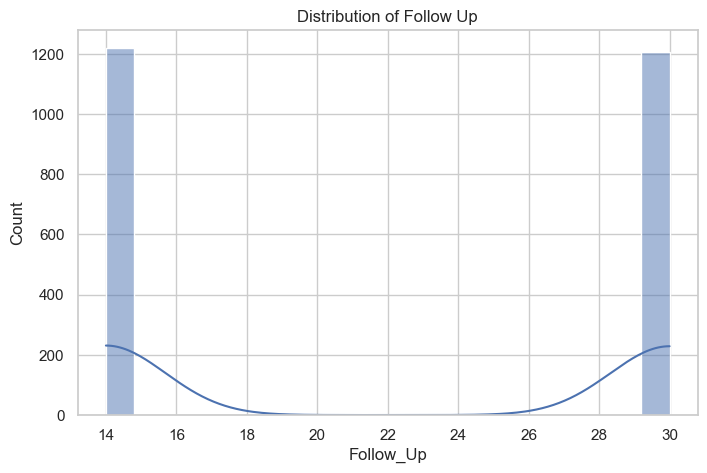

In [97]:
# Follow Up
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Follow_Up", bins=20, kde=True)
plt.title("Distribution of Follow Up")
plt.show()

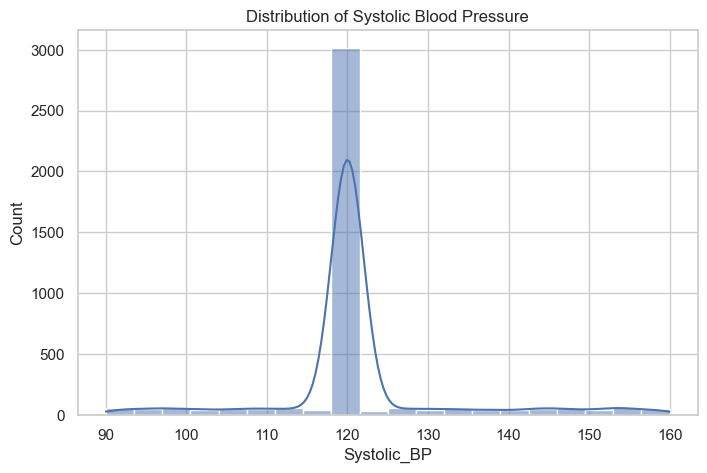

In [98]:
# Systolic BP
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Systolic_BP", bins=20, kde=True)
plt.title("Distribution of Systolic Blood Pressure")
plt.show()

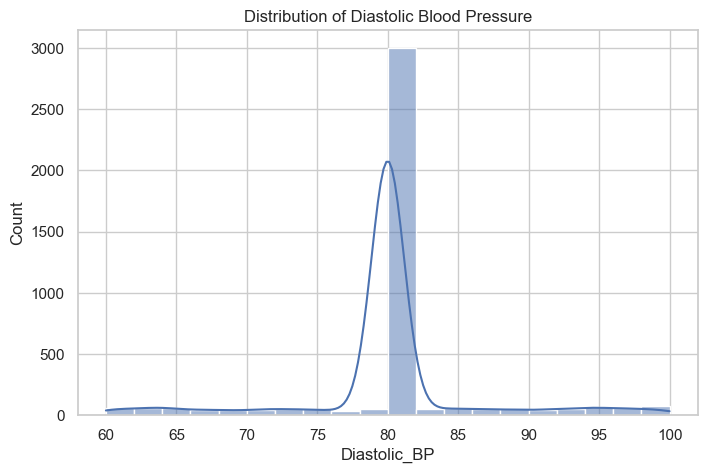

In [99]:
# Diastolic BP
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Diastolic_BP", bins=20, kde=True)
plt.title("Distribution of Diastolic Blood Pressure")
plt.show()

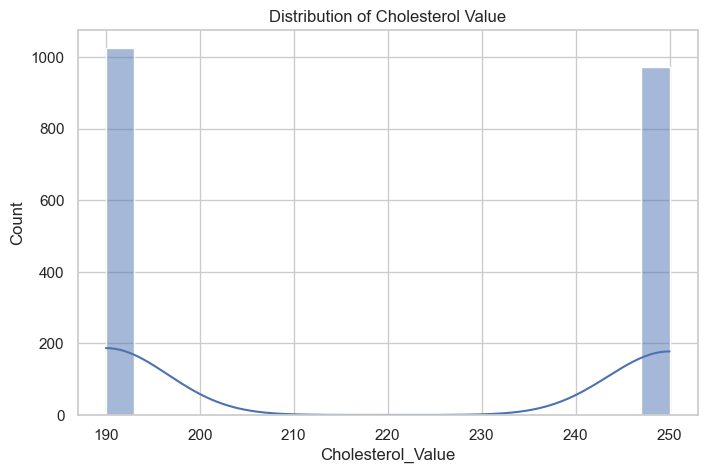

In [100]:
# Cholesterol Value
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Cholesterol_Value", bins=20, kde=True)
plt.title("Distribution of Cholesterol Value")
plt.show()

# 5. Box plots for numerical variables

# Box plots help you identify potential outliers.

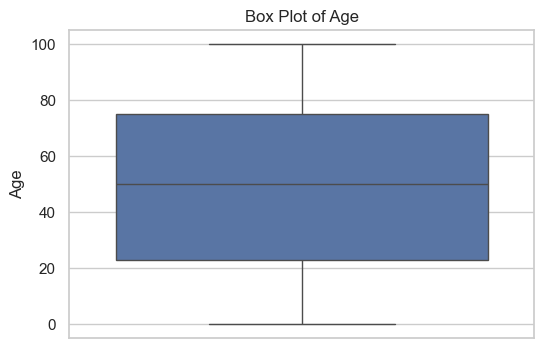

In [101]:
# Age
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, y="Age")
plt.title("Box Plot of Age")
plt.show()

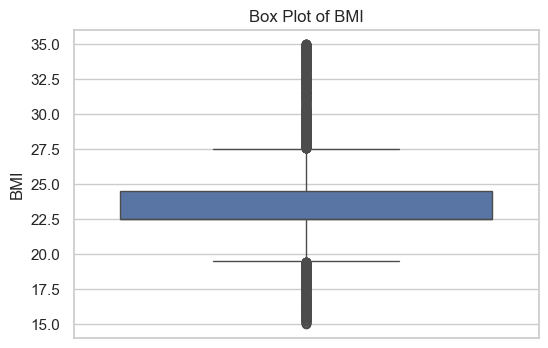

In [102]:
# BMI
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, y="BMI")
plt.title("Box Plot of BMI")
plt.show()

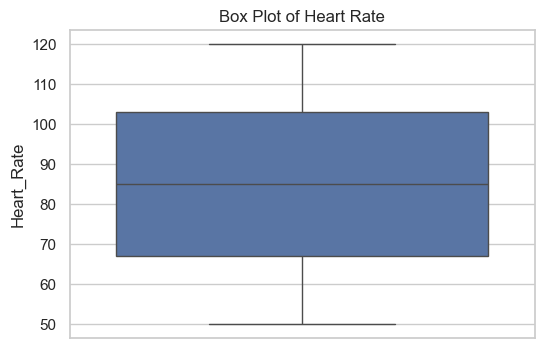

In [103]:
# Heart Rate
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, y="Heart_Rate")
plt.title("Box Plot of Heart Rate")
plt.show()

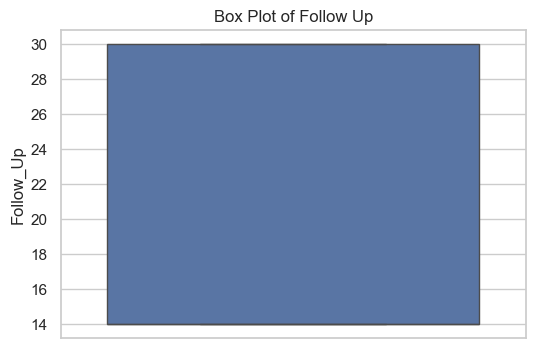

In [104]:
# Follow Up
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, y="Follow_Up")
plt.title("Box Plot of Follow Up")
plt.show()

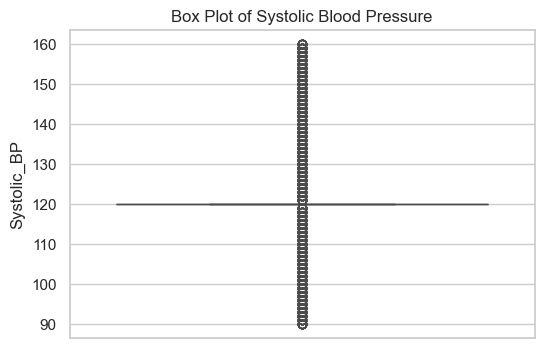

In [105]:
# Systolic BP
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, y="Systolic_BP")
plt.title("Box Plot of Systolic Blood Pressure")
plt.show()

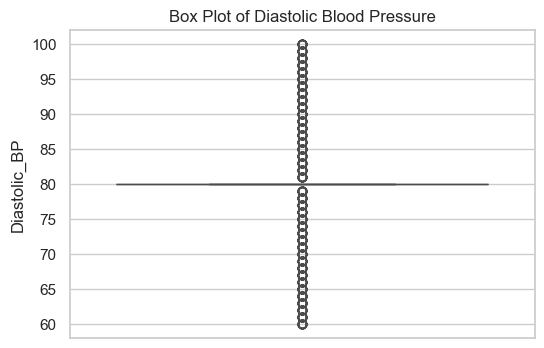

In [106]:
# Diastolic BP
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, y="Diastolic_BP")
plt.title("Box Plot of Diastolic Blood Pressure")
plt.show()

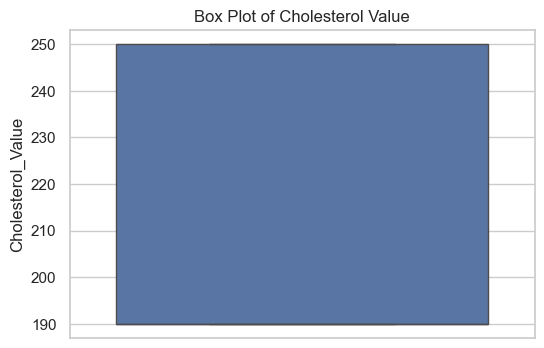

In [107]:
# Cholesterol Value
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, y="Cholesterol_Value")
plt.title("Box Plot of Cholesterol Value")
plt.show()

# 6. Count Plots for categorical variables

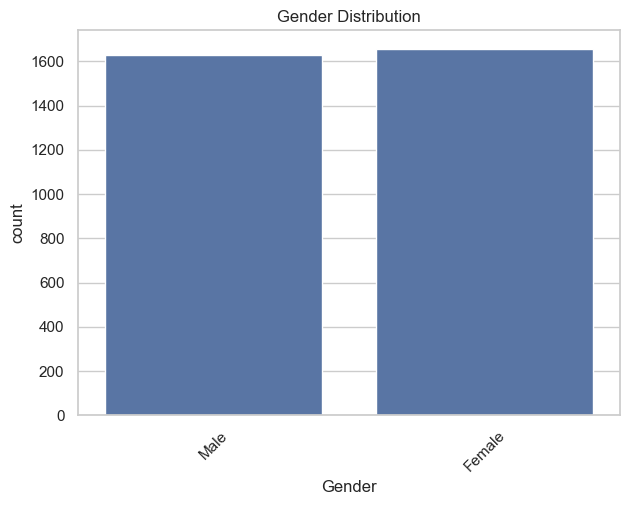

In [108]:
# Gender
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Gender")
plt.title("Gender Distribution")
plt.xticks(rotation=45)
plt.show()

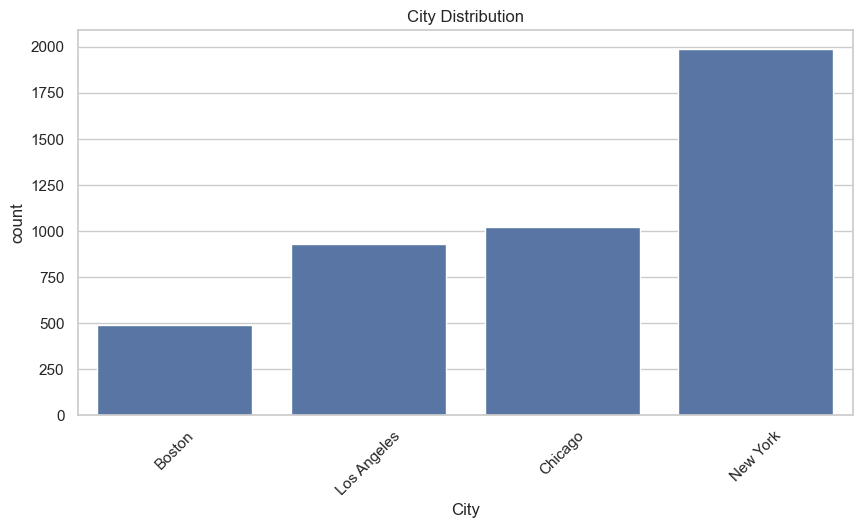

In [109]:
# City
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="City")
plt.title("City Distribution")
plt.xticks(rotation=45)
plt.show()

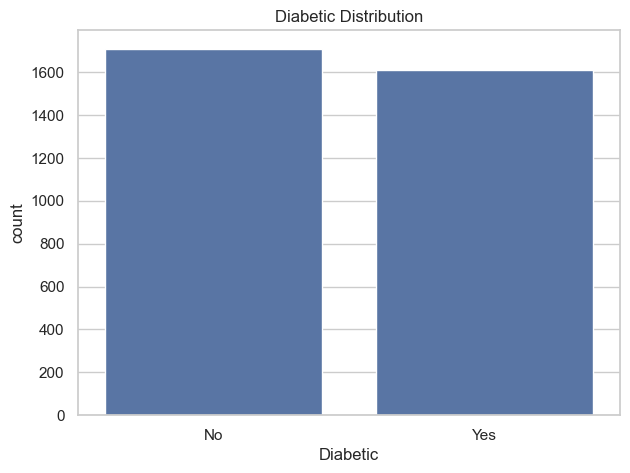

In [110]:
# Diabetic
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Diabetic")
plt.title("Diabetic Distribution")
plt.show()

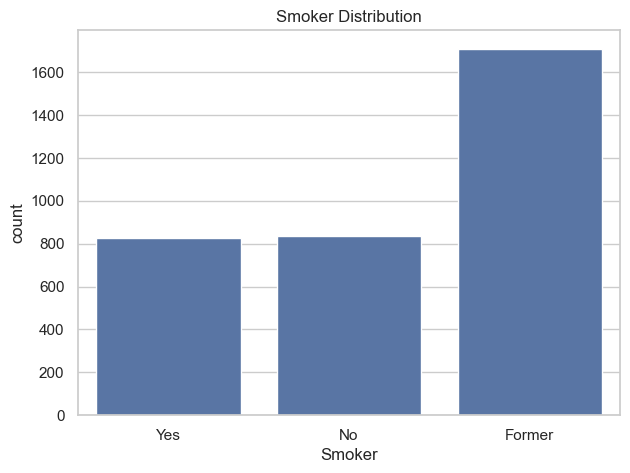

In [111]:
# Smoker
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Smoker")
plt.title("Smoker Distribution")
plt.show()

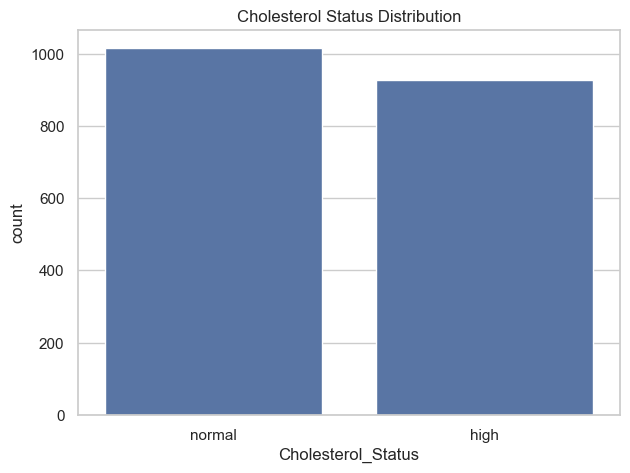

In [112]:
# Cholesterol Status
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Cholesterol_Status")
plt.title("Cholesterol Status Distribution")
plt.show()

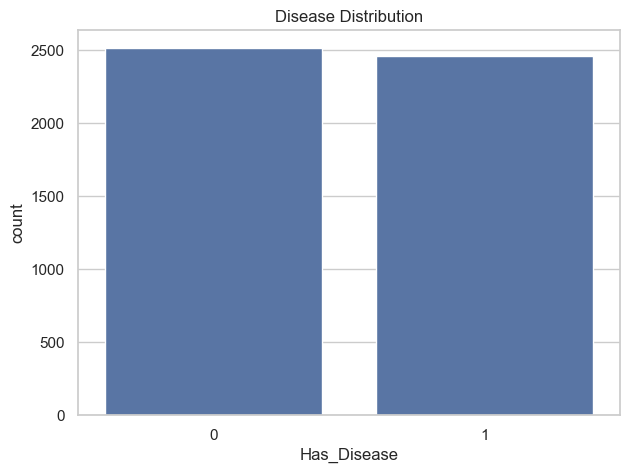

In [113]:
# Has Disease
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Has_Disease")
plt.title("Disease Distribution")
plt.show()

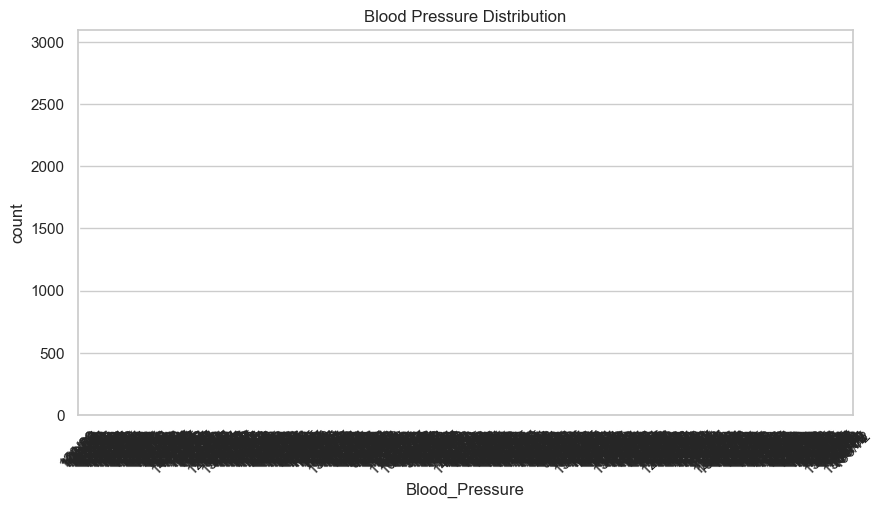

In [114]:
# Blood Pressure
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Blood_Pressure")
plt.title("Blood Pressure Distribution")
plt.xticks(rotation=45)
plt.show()

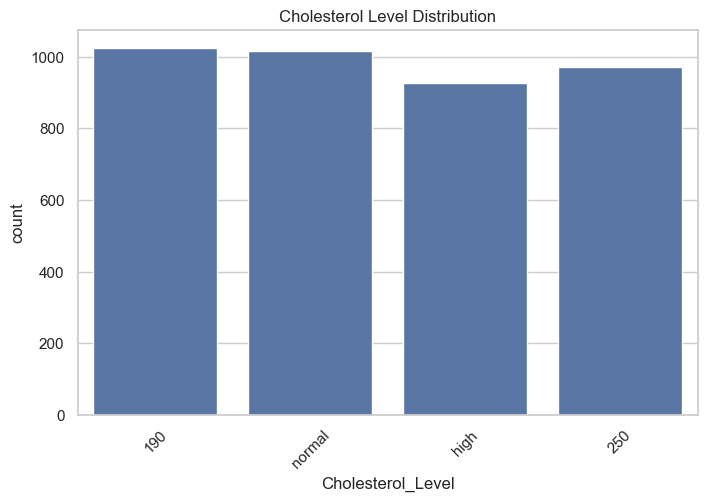

In [115]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Cholesterol_Level")
plt.title("Cholesterol Level Distribution")
plt.xticks(rotation=45)
plt.show()

# 7. Date variable — basic univariate analysis

## Last_Visit_Date, first check the range:

In [116]:
# Minimum and maximum visit dates

df["Last_Visit_Date"].agg(["min", "max"])

min   2020-01-01
max   2025-10-01
Name: Last_Visit_Date, dtype: datetime64[ns]

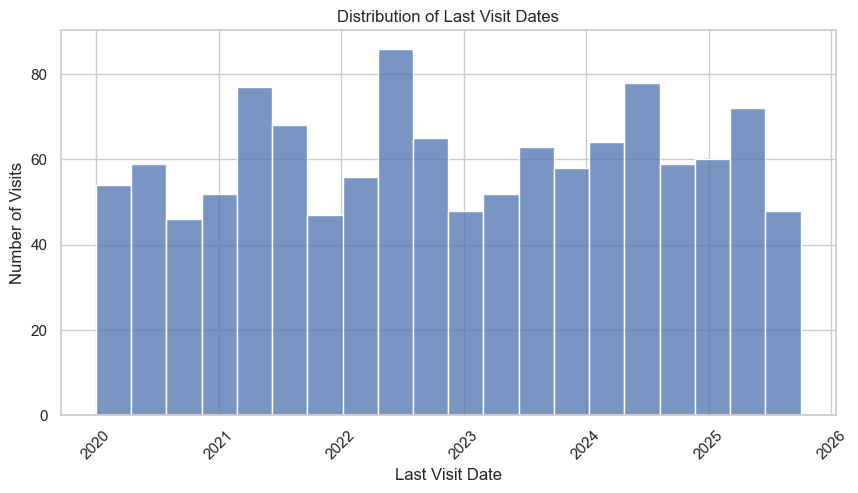

In [117]:
# Last Visit Dates
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Last_Visit_Date", bins=20)

plt.title("Distribution of Last Visit Dates")
plt.xlabel("Last Visit Date")
plt.ylabel("Number of Visits")
plt.xticks(rotation=45)
plt.show()

# checking Normal distrbution with the help of QQ plot

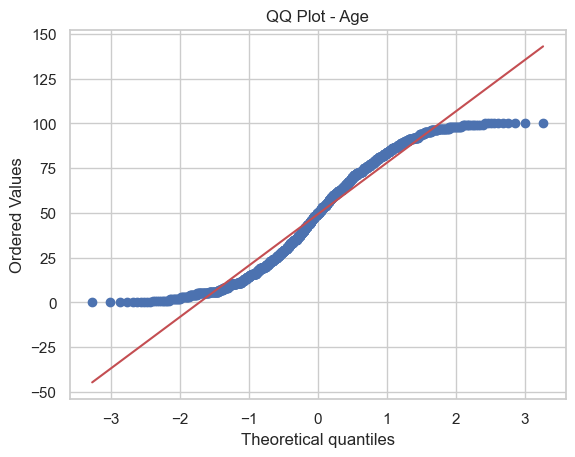

In [118]:
# Age
from scipy import stats
stats.probplot(df["Age"].dropna().astype(float), dist="norm", plot=plt)
plt.title("QQ Plot - Age")
plt.show()

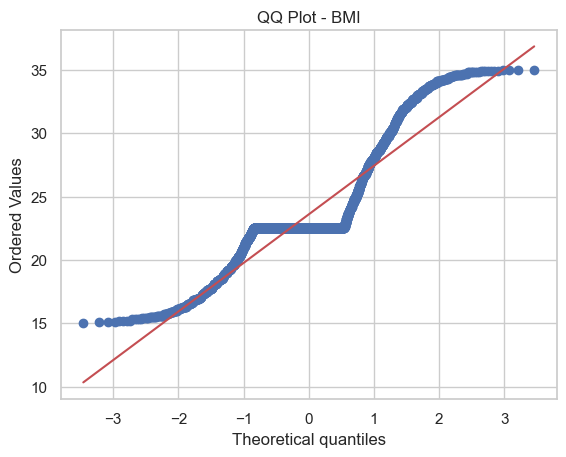

In [119]:
# BMI
stats.probplot(df["BMI"].dropna().astype(float), dist="norm", plot=plt)
plt.title("QQ Plot - BMI")
plt.show()

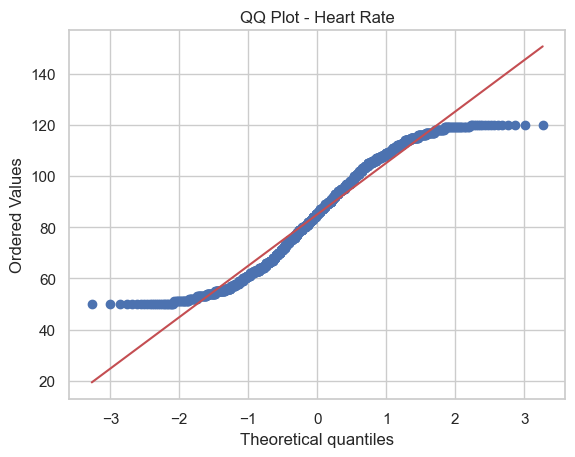

In [120]:
# Heart_Rate
stats.probplot(df["Heart_Rate"].dropna().astype(float), dist="norm", plot=plt)
plt.title("QQ Plot - Heart Rate")
plt.show()

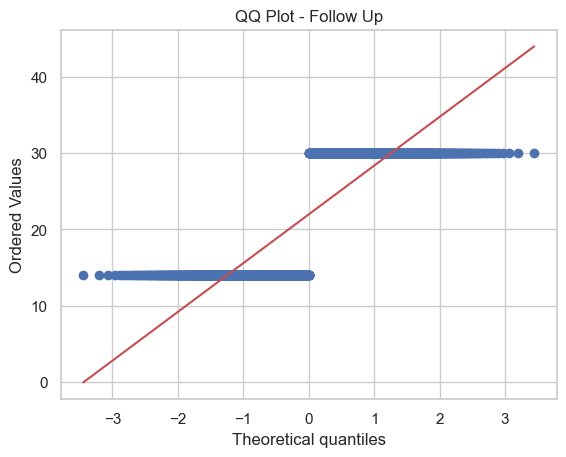

In [121]:
#Follow_Up
stats.probplot(df["Follow_Up"].dropna().astype(float), dist="norm", plot=plt)
plt.title("QQ Plot - Follow Up")
plt.show()

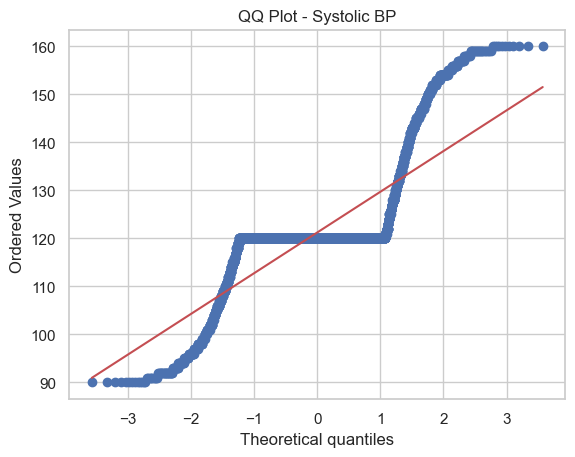

In [122]:
# Systolic_BP
stats.probplot(df["Systolic_BP"].dropna().astype(float), dist="norm", plot=plt)
plt.title("QQ Plot - Systolic BP")
plt.show()

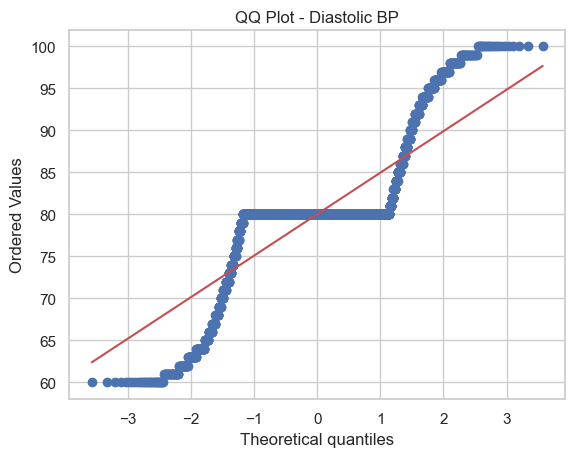

In [123]:
# Diastolic_BP
stats.probplot(df["Diastolic_BP"].dropna().astype(float), dist="norm", plot=plt)
plt.title("QQ Plot - Diastolic BP")
plt.show()

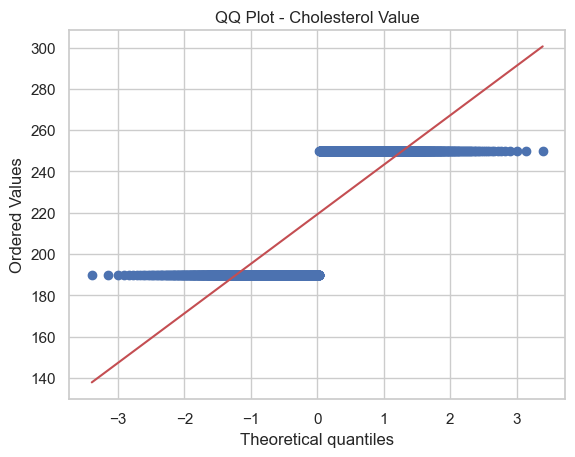

In [124]:
# Cholesterol_Value
stats.probplot(df["Cholesterol_Value"].dropna().astype(float), dist="norm", plot=plt)
plt.title("QQ Plot - Cholesterol Value")
plt.show()

# Bivariate analysis
# 1. Numerical vs Target

## For numerical variables, use box plots.

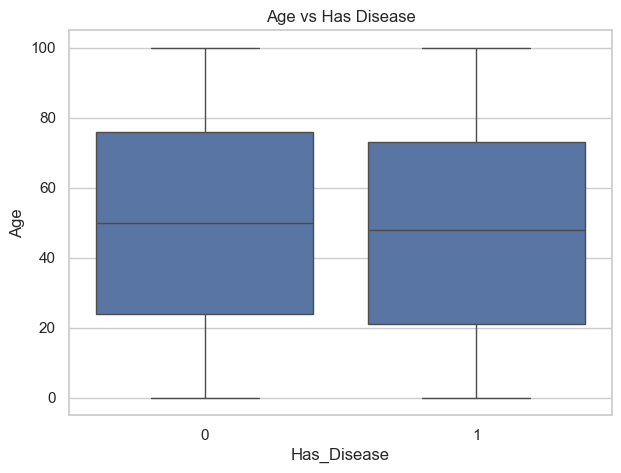

In [125]:
# Age vs Disease
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Has_Disease", y="Age")
plt.title("Age vs Has Disease")
plt.show()

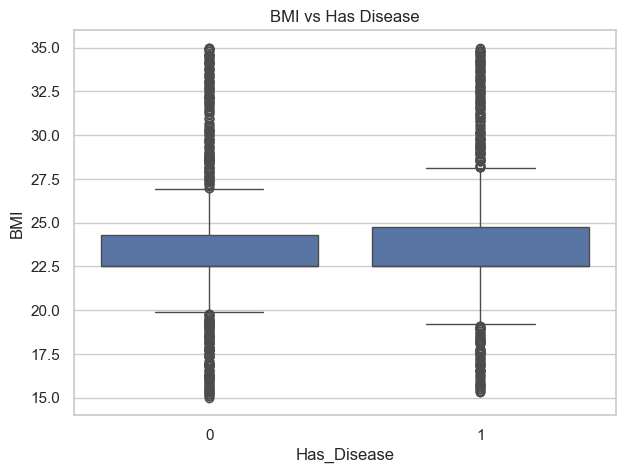

In [126]:
# BMI vs Disease
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Has_Disease", y="BMI")
plt.title("BMI vs Has Disease")
plt.show()

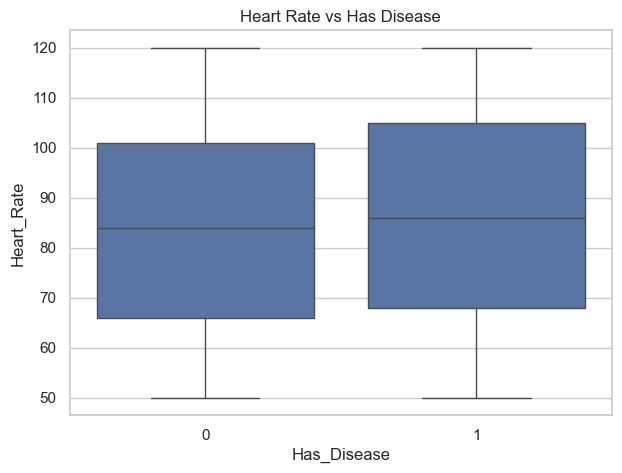

In [127]:
# Heart Rate vs Disease
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Has_Disease", y="Heart_Rate")
plt.title("Heart Rate vs Has Disease")
plt.show()

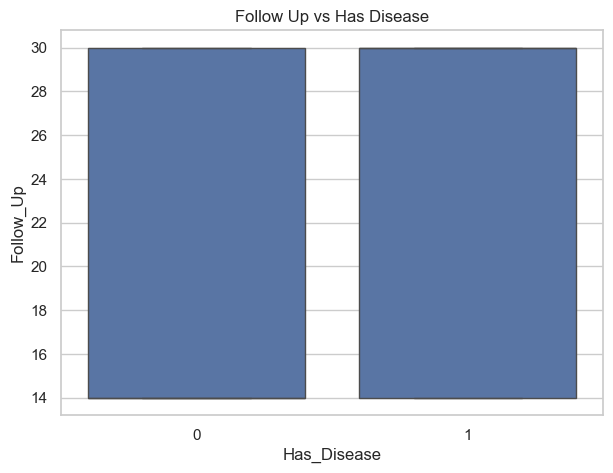

In [128]:
# Follow Up vs Disease
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Has_Disease", y="Follow_Up")
plt.title("Follow Up vs Has Disease")
plt.show()

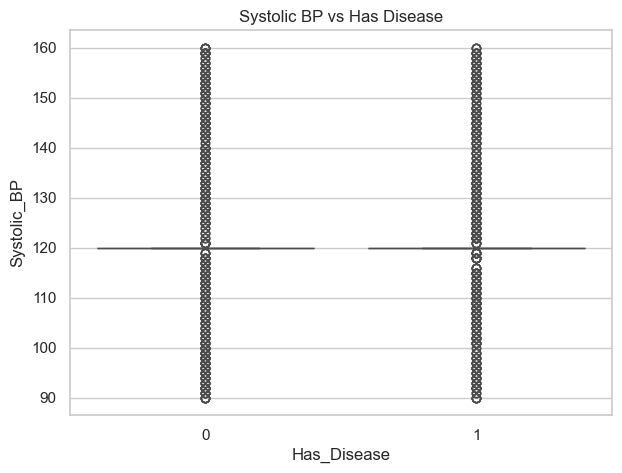

In [129]:
# Systolic BP vs Disease
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Has_Disease", y="Systolic_BP")
plt.title("Systolic BP vs Has Disease")
plt.show()

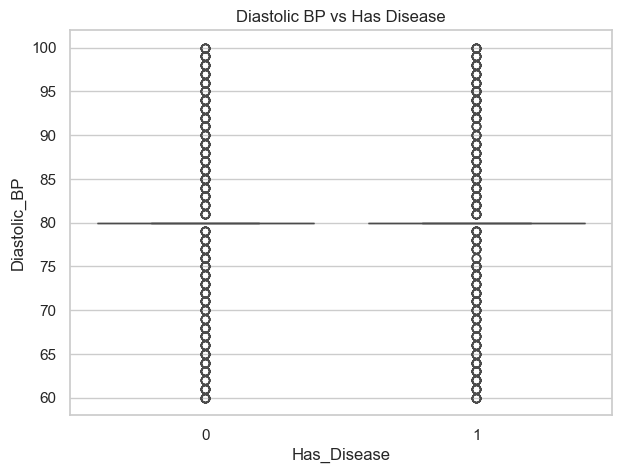

In [130]:
# Diastolic BP vs Disease
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Has_Disease", y="Diastolic_BP")
plt.title("Diastolic BP vs Has Disease")
plt.show()

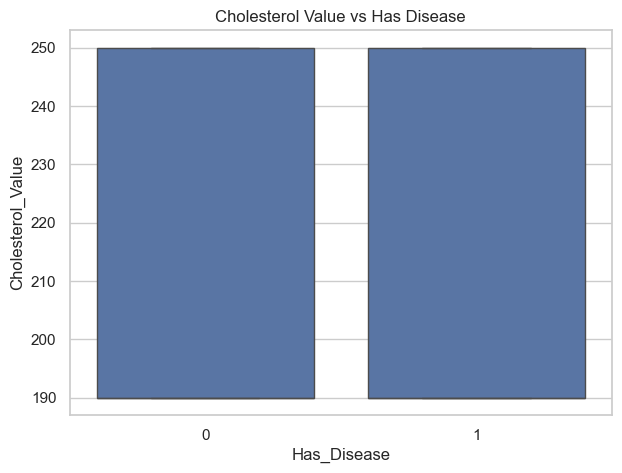

In [131]:
# Cholesterol Value vs Disease
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Has_Disease", y="Cholesterol_Value")
plt.title("Cholesterol Value vs Has Disease")
plt.show()

# 2. Categorical vs Target

## For categorical variables, use count plots/bar charts.

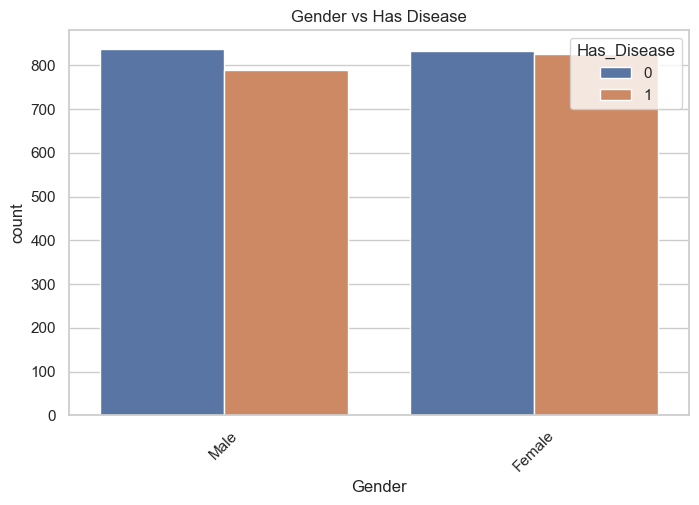

In [132]:
# Gender vs Disease
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Gender", hue="Has_Disease")
plt.title("Gender vs Has Disease")
plt.xticks(rotation=45)
plt.show()

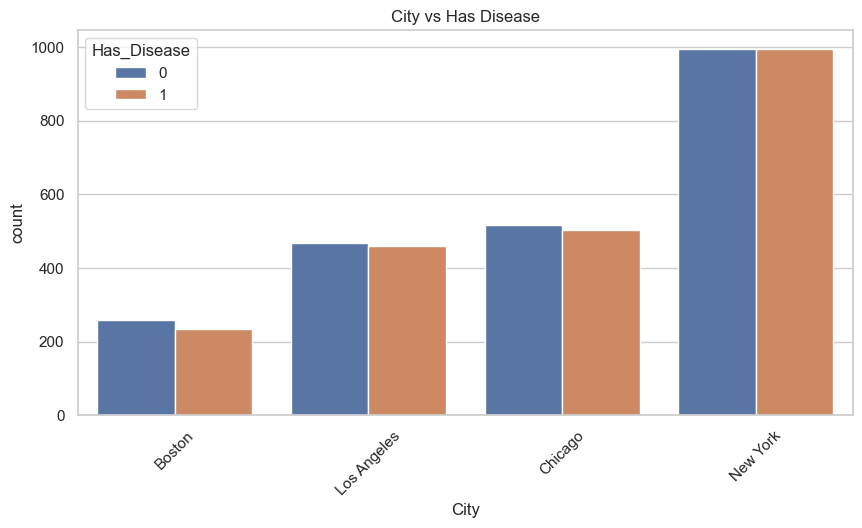

In [133]:
# City vs Disease
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="City", hue="Has_Disease")
plt.title("City vs Has Disease")
plt.xticks(rotation=45)
plt.show()

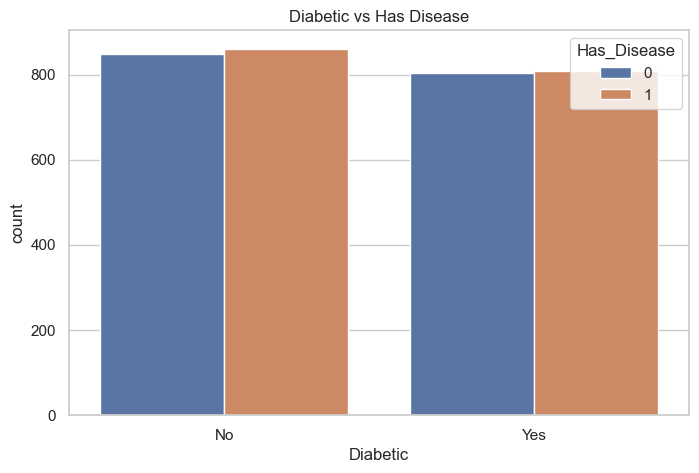

In [134]:
# Diabetic vs Disease
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Diabetic", hue="Has_Disease")
plt.title("Diabetic vs Has Disease")
plt.show()

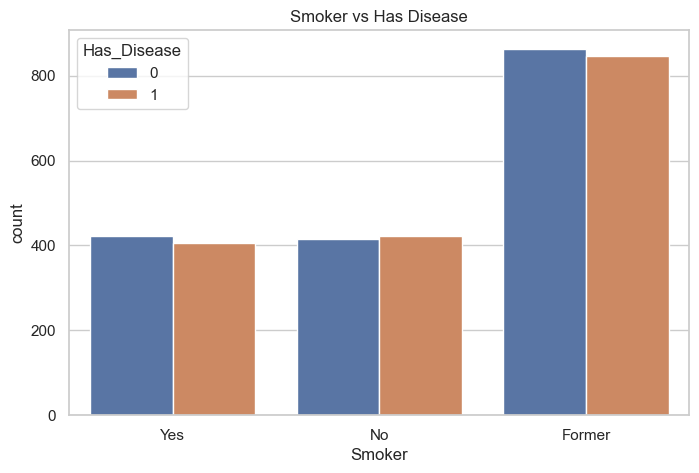

In [135]:
# Smoker vs Disease
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Smoker", hue="Has_Disease")
plt.title("Smoker vs Has Disease")
plt.show()

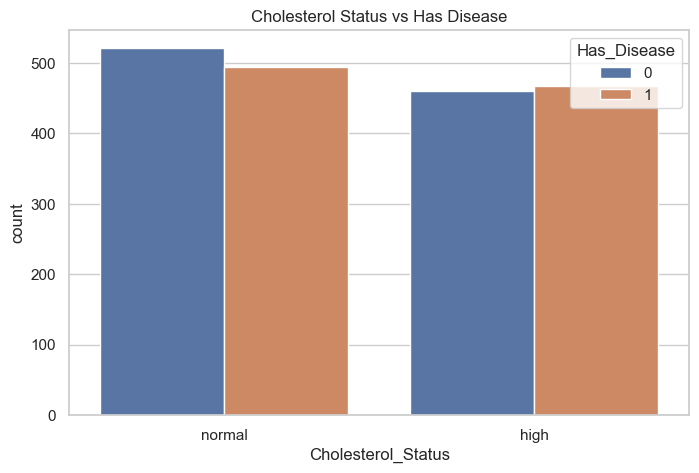

In [136]:
# Cholesterol Status vs Disease
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Cholesterol_Status", hue="Has_Disease")
plt.title("Cholesterol Status vs Has Disease")
plt.show()

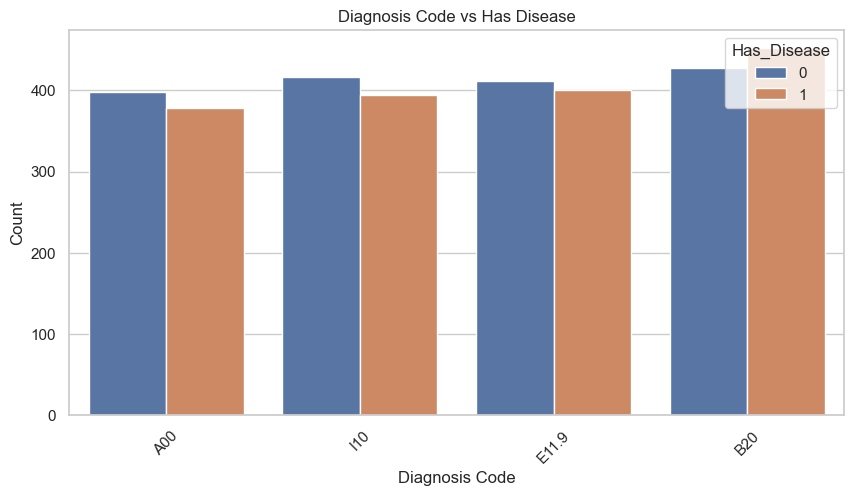

In [137]:
# Diagnosis Code Status vs Disease
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="Diagnosis_Code", hue="Has_Disease")

plt.title("Diagnosis Code vs Has Disease")
plt.xlabel("Diagnosis Code")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

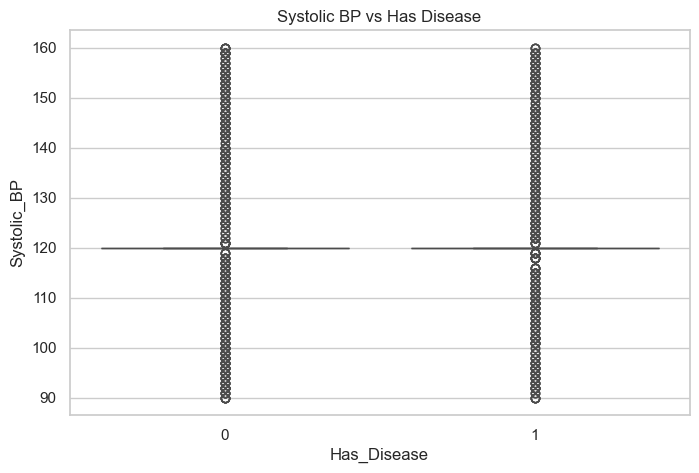

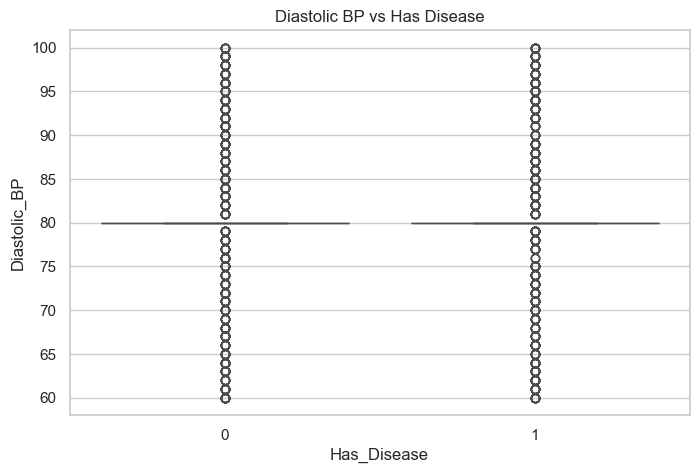

In [138]:
# Systolic BP vs Has Disease
# Diastolic BP vs Has Disease

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Has_Disease", y="Systolic_BP")
plt.title("Systolic BP vs Has Disease")
plt.show()


plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Has_Disease", y="Diastolic_BP")
plt.title("Diastolic BP vs Has Disease")
plt.show()

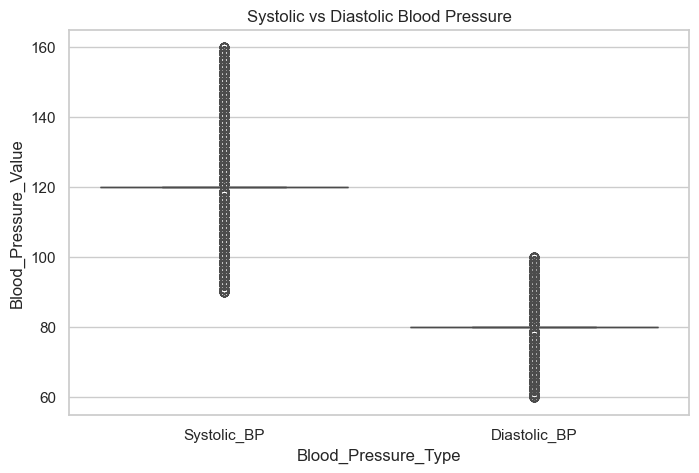

In [139]:
# Systolic vs Diastolic Blood Pressure
bp_df = df[["Systolic_BP", "Diastolic_BP"]].melt(
    var_name="Blood_Pressure_Type",
    value_name="Blood_Pressure_Value"
)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=bp_df,
    x="Blood_Pressure_Type",
    y="Blood_Pressure_Value"
)
plt.title("Systolic vs Diastolic Blood Pressure")
plt.show()

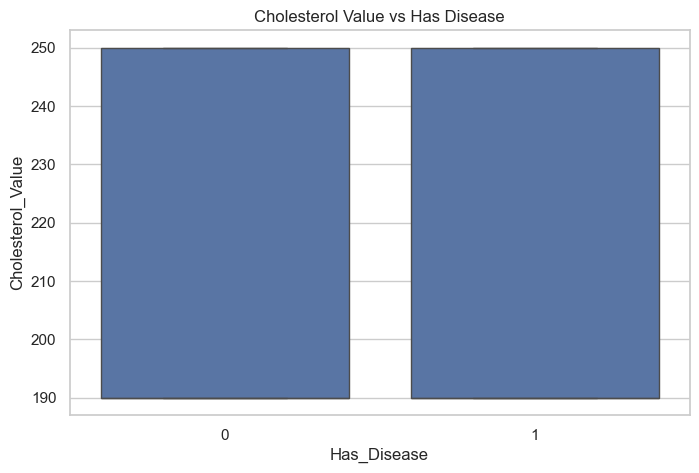

In [140]:
# Cholesterol Value vs Has Disease
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Has_Disease",
    y="Cholesterol_Value"
)
plt.title("Cholesterol Value vs Has Disease")
plt.show()

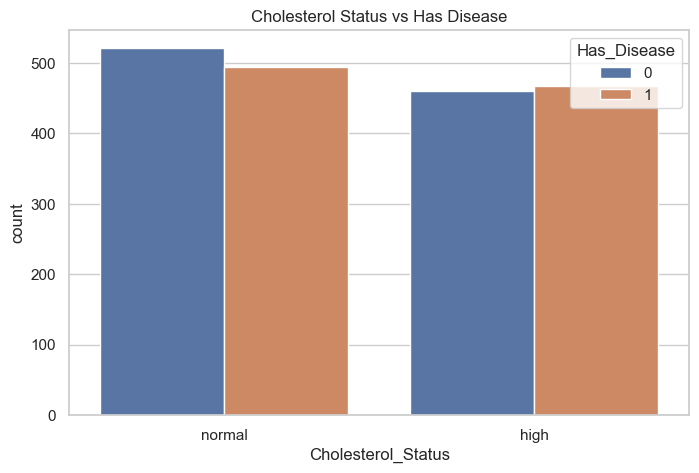

In [141]:
# Patient Visits by Year
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Cholesterol_Status",
    hue="Has_Disease"
)
plt.title("Cholesterol Status vs Has Disease")
plt.show()

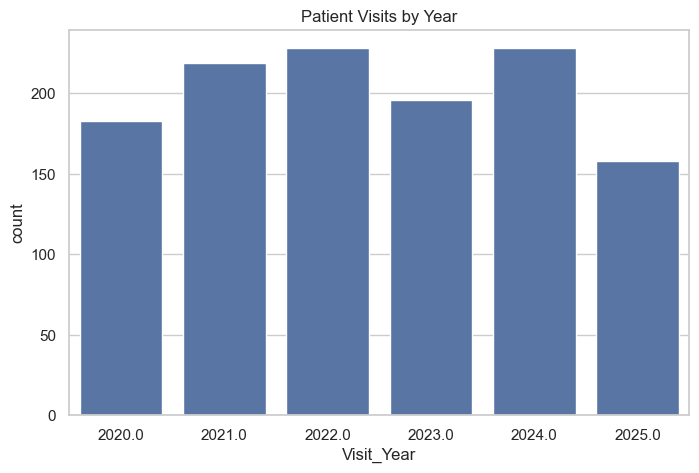

In [142]:
# Last_Visit_Date
df["Visit_Year"] = df["Last_Visit_Date"].dt.year

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Visit_Year")
plt.title("Patient Visits by Year")
plt.show()

# 3. Numerical vs Numerical

## For relationships between two numerical variables, use a scatter plot.

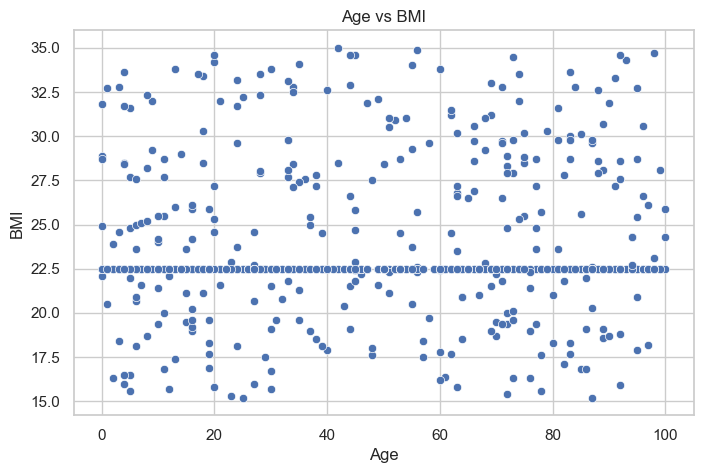

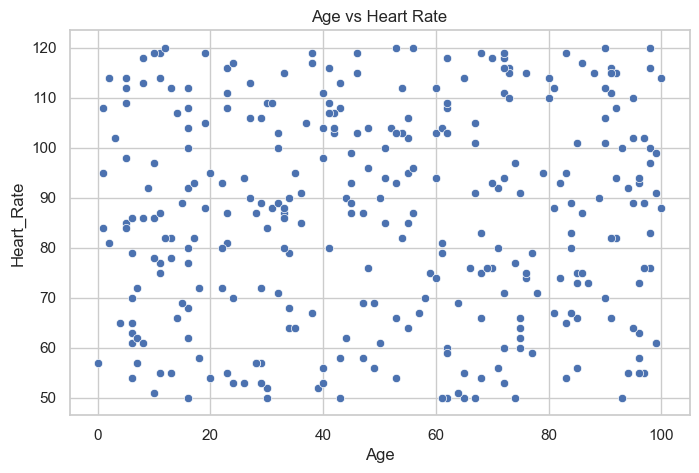

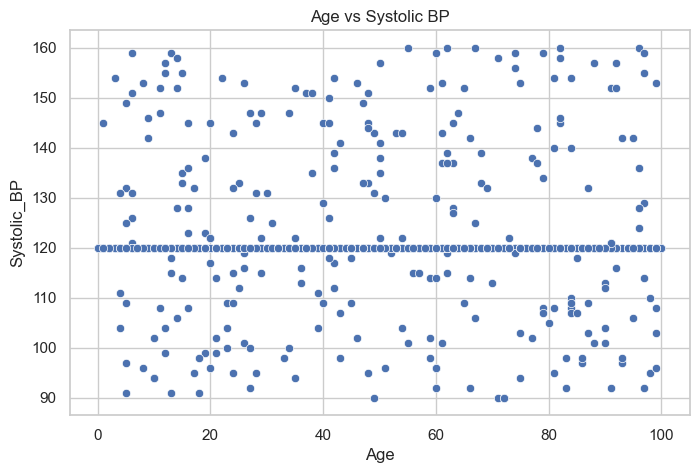

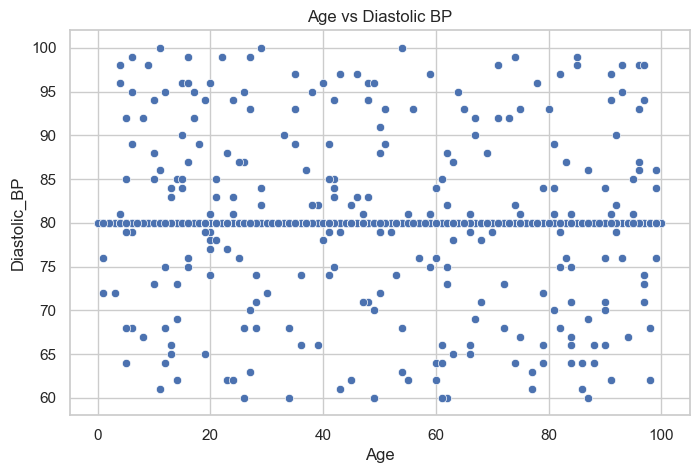

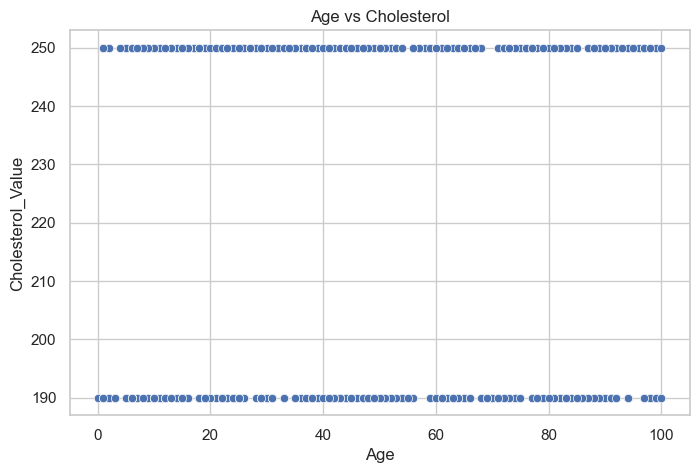

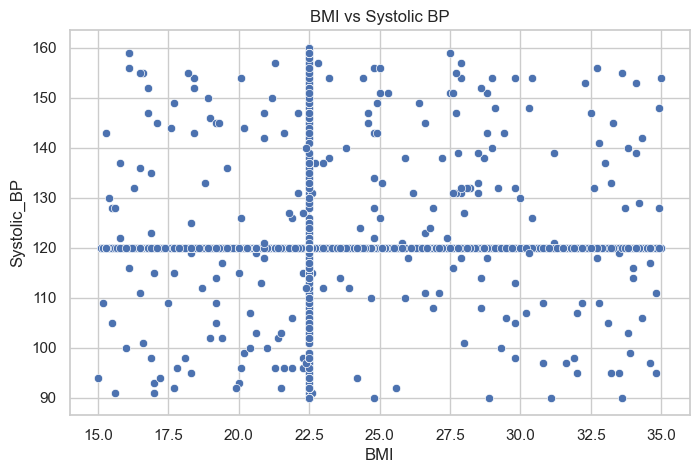

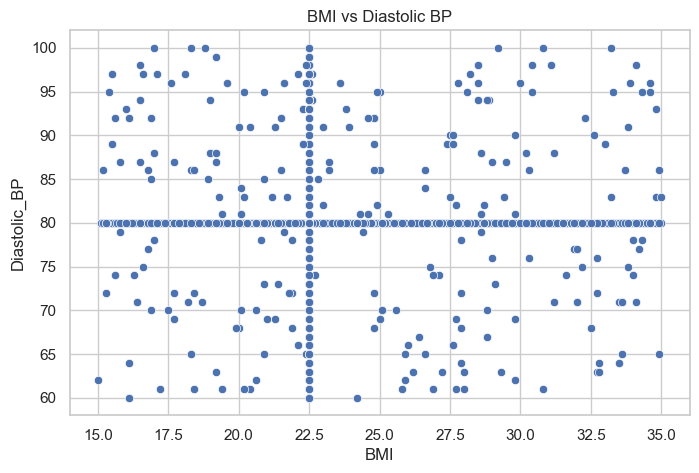

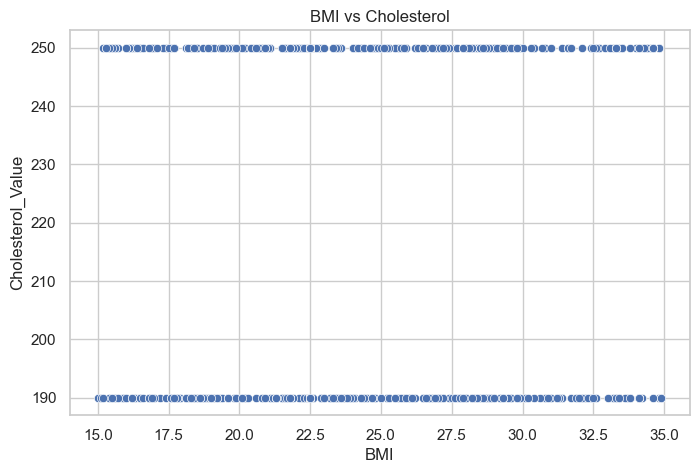

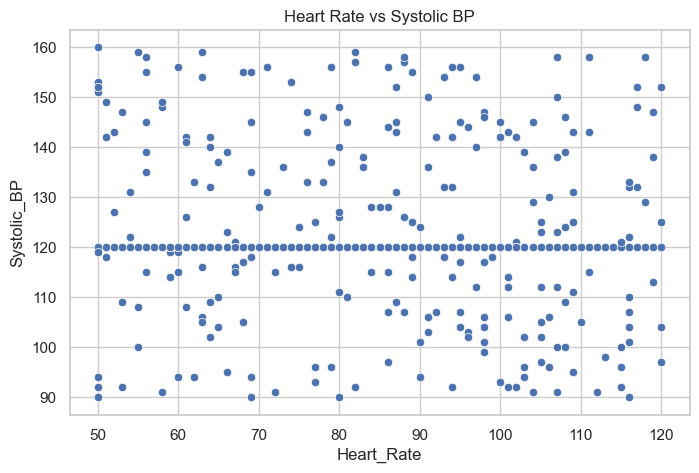

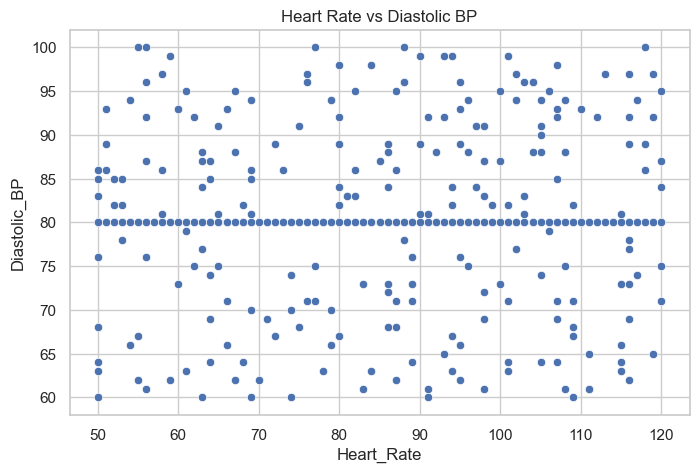

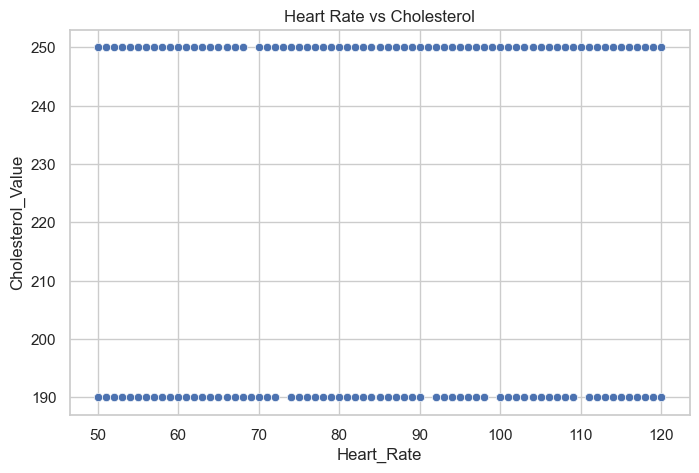

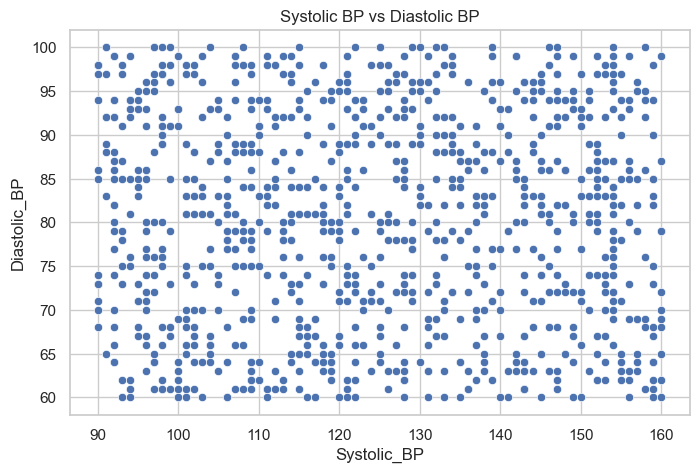

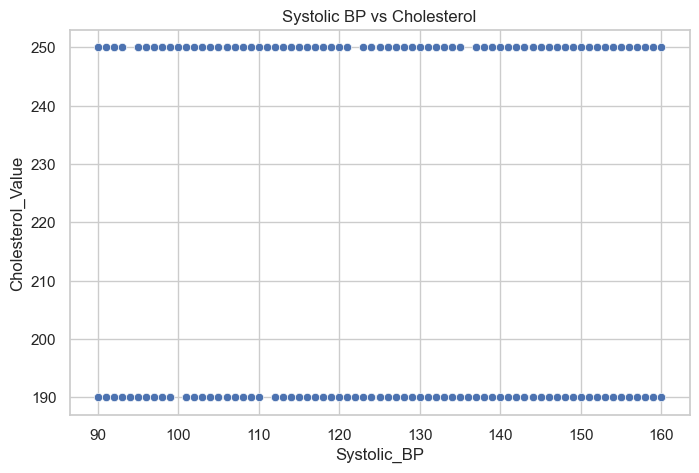

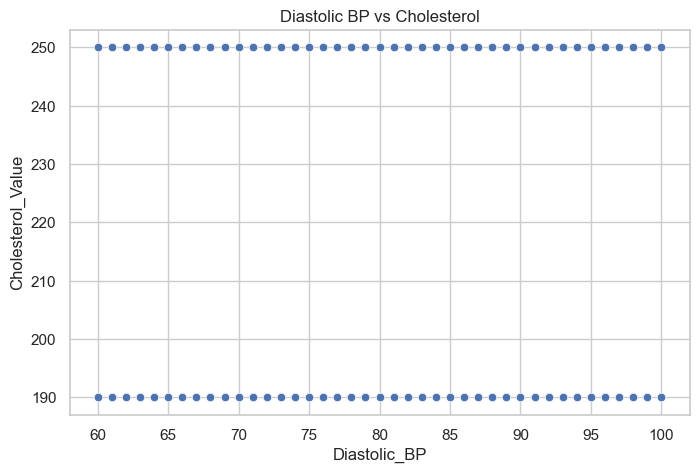

In [143]:
import matplotlib.pyplot as plt
import seaborn as sns

# Age vs BMI
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Age", y="BMI")
plt.title("Age vs BMI")
plt.show()


# Age vs Heart Rate
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Age", y="Heart_Rate")
plt.title("Age vs Heart Rate")
plt.show()


# Age vs Systolic BP
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Age", y="Systolic_BP")
plt.title("Age vs Systolic BP")
plt.show()


# Age vs Diastolic BP
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Age", y="Diastolic_BP")
plt.title("Age vs Diastolic BP")
plt.show()


# Age vs Cholesterol
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Age", y="Cholesterol_Value")
plt.title("Age vs Cholesterol")
plt.show()


# BMI vs Systolic BP
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="BMI", y="Systolic_BP")
plt.title("BMI vs Systolic BP")
plt.show()


# BMI vs Diastolic BP
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="BMI", y="Diastolic_BP")
plt.title("BMI vs Diastolic BP")
plt.show()


# BMI vs Cholesterol
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="BMI", y="Cholesterol_Value")
plt.title("BMI vs Cholesterol")
plt.show()


# Heart Rate vs Systolic BP
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Heart_Rate", y="Systolic_BP")
plt.title("Heart Rate vs Systolic BP")
plt.show()


# Heart Rate vs Diastolic BP
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Heart_Rate", y="Diastolic_BP")
plt.title("Heart Rate vs Diastolic BP")
plt.show()


# Heart Rate vs Cholesterol
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Heart_Rate", y="Cholesterol_Value")
plt.title("Heart Rate vs Cholesterol")
plt.show()


# Systolic BP vs Diastolic BP
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Systolic_BP", y="Diastolic_BP")
plt.title("Systolic BP vs Diastolic BP")
plt.show()


# Systolic BP vs Cholesterol
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Systolic_BP", y="Cholesterol_Value")
plt.title("Systolic BP vs Cholesterol")
plt.show()


# Diastolic BP vs Cholesterol
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Diastolic_BP", y="Cholesterol_Value")
plt.title("Diastolic BP vs Cholesterol")
plt.show()

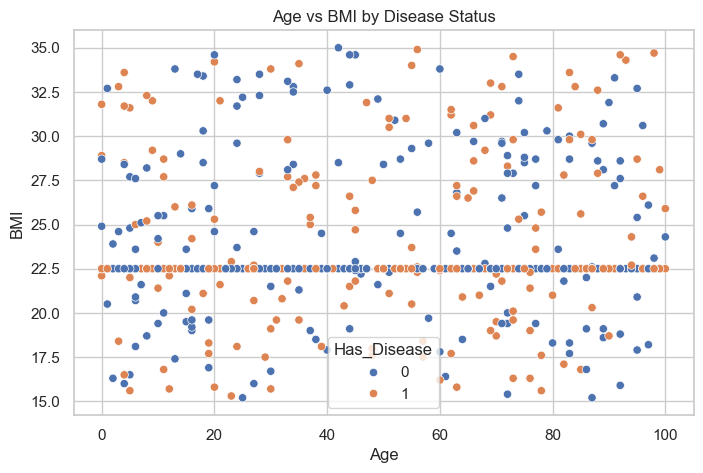

In [144]:
# Age vs BMI
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Age", y="BMI", hue="Has_Disease")
plt.title("Age vs BMI by Disease Status")
plt.show()

In [145]:
df[qual].head(20)

,Gender,City,Cholesterol_Level,Diabetic,Smoker,Medications,Diagnosis_Code,Notes,Cholesterol_Status
0,NaN,Boston,190,<NA>,Yes,<NA>,A00,Patient feeling fine 🙂,<NA>
1,Male,Los Angeles,normal,No,No,<NA>,I10,Patient feeling fine 🙂,normal
2,NaN,<NA>,normal,No,Former,<NA>,E11.9,<NA>,normal
3,NaN,Boston,high,No,Former,Aspirin; Metformin,<NA>,<NA>,high
4,NaN,Chicago,NaN,No,Former,<NA>,A00,"BP high, needs recheck",<NA>
5,Male,Boston,NaN,Yes,Former,<NA>,E11.9,Follow up soon,<NA>
6,Male,Los Angeles,NaN,No,Former,Lisinopril; Metformin,<NA>,<NA>,<NA>
7,NaN,Los Angeles,250,No,<NA>,Aspirin; Metformin,I10,"BP high, needs recheck",<NA>
8,Female,New York,190,Yes,Former,Aspirin; Metformin,E11.9,"BP high, needs recheck",<NA>
9,Female,Chicago,normal,Yes,Yes,<NA>,E11.9,Patient feeling fine 🙂,normal


In [146]:
from scipy.stats import chi2_contingency

# Categorical variables
qual = [
    'Gender',
    'City',
    'Cholesterol_Level',
    'Diabetic',
    'Smoker',
    'Medications',
    'Diagnosis_Code',
    'Notes',
    'Cholesterol_Status'
]

# Chi-square test for each categorical variable
for col in qual:

    # Create contingency table
    table = pd.crosstab(df[col], df["Has_Disease"])

    # Chi-square test
    chi2, p_value, dof, expected = chi2_contingency(table)

    print(f"\n--- {col} vs Has_Disease ---")
    print("Chi-square statistic:", chi2)
    print("p-value:", p_value)


--- Gender vs Has_Disease ---
Chi-square statistic: 0.45151298515035243
p-value: 0.5016173362071079

--- City vs Has_Disease ---
Chi-square statistic: 1.0004504301622539
p-value: 0.8011429659903372

--- Cholesterol_Level vs Has_Disease ---
Chi-square statistic: 0.8579744181388075
p-value: 0.8355558371339254

--- Diabetic vs Has_Disease ---
Chi-square statistic: 0.003625755234902743
p-value: 0.951985000868927

--- Smoker vs Has_Disease ---
Chi-square statistic: 0.36513196333063913
p-value: 0.8331296708316336

--- Medications vs Has_Disease ---
Chi-square statistic: 0.6274595571505255
p-value: 0.42828869904750744

--- Diagnosis_Code vs Has_Disease ---
Chi-square statistic: 1.66407125411757
p-value: 0.6449508929679622

--- Notes vs Has_Disease ---
Chi-square statistic: 1.0821243411812271
p-value: 0.5821296029323715

--- Cholesterol_Status vs Has_Disease ---
Chi-square statistic: 0.5330673876473794
p-value: 0.46532011323748346


In [147]:
for col in qual:

    print(f"\n===== {col} vs Has_Disease =====")

    # Contingency table
    table = pd.crosstab(df[col], df["Has_Disease"])
    print(table)

    # Chi-square test
    chi2, p_value, dof, expected = chi2_contingency(table)

    print("Chi-square:", chi2)
    print("p-value:", p_value)


===== Gender vs Has_Disease =====
Has_Disease    0    1
Gender               
Female       833  825
Male         838  790
Chi-square: 0.45151298515035243
p-value: 0.5016173362071079

===== City vs Has_Disease =====
Has_Disease    0    1
City                 
Boston       258  234
Chicago      517  503
Los Angeles  468  461
New York     994  996
Chi-square: 1.0004504301622539
p-value: 0.8011429659903372

===== Cholesterol_Level vs Has_Disease =====
Has_Disease          0    1
Cholesterol_Level          
190                527  497
250                494  479
high               460  468
normal             521  494
Chi-square: 0.8579744181388075
p-value: 0.8355558371339254

===== Diabetic vs Has_Disease =====
Has_Disease    0    1
Diabetic             
No           849  861
Yes          803  809
Chi-square: 0.003625755234902743
p-value: 0.951985000868927

===== Smoker vs Has_Disease =====
Has_Disease    0    1
Smoker               
Former       864  846
No           415  422
Yes         

# Multivariate analysis
# 1. Correlation heatmap — numerical variables

## This is one of the most important multivariate analyses.

In [148]:
numeric_cols = [
    "Age",
    "BMI",
    "Heart_Rate",
    "Follow_Up",
    "Systolic_BP",
    "Diastolic_BP",
    "Cholesterol_Value"
]

df[numeric_cols].corr()

,Age,BMI,Heart_Rate,Follow_Up,Systolic_BP,Diastolic_BP,Cholesterol_Value
Age,1.000000,0.023653,0.031604,-0.000715,-0.007085,-0.046266,0.053648
BMI,0.023653,1.000000,0.026966,-0.019303,0.007193,-0.009168,0.005682
Heart_Rate,0.031604,0.026966,1.000000,-0.005906,-0.060594,0.020208,-0.004413
Follow_Up,-0.000715,-0.019303,-0.005906,1.000000,-0.023877,-0.025230,-0.032067
Systolic_BP,-0.007085,0.007193,-0.060594,-0.023877,1.000000,-0.016736,-0.001513
Diastolic_BP,-0.046266,-0.009168,0.020208,-0.025230,-0.016736,1.000000,0.007722
Cholesterol_Value,0.053648,0.005682,-0.004413,-0.032067,-0.001513,0.007722,1.000000


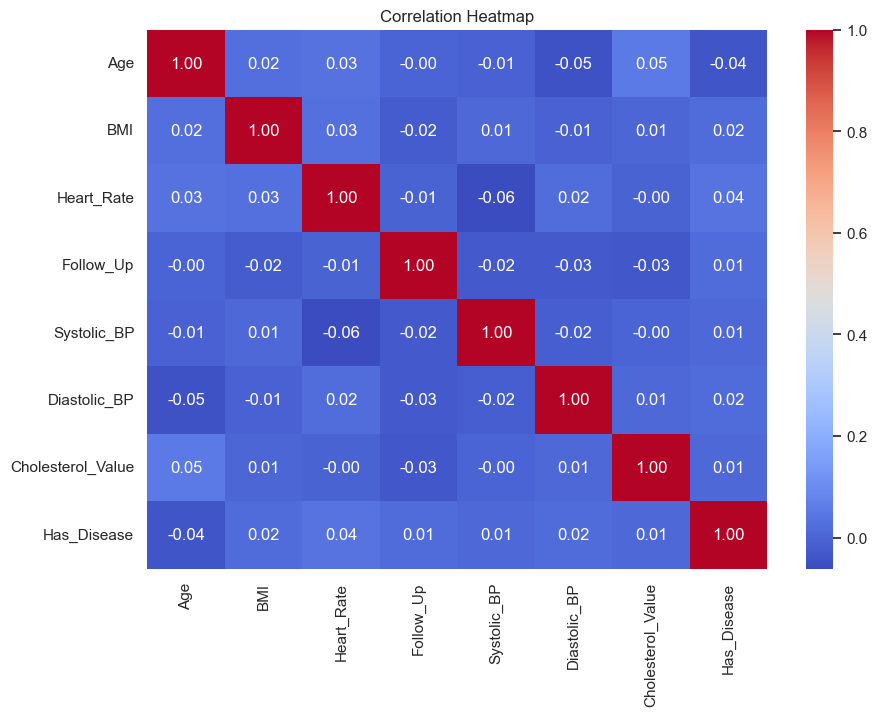

In [149]:
# Correlation Heatmap
numeric_cols = [
    "Age",
    "BMI",
    "Heart_Rate",
    "Follow_Up",
    "Systolic_BP",
    "Diastolic_BP",
    "Cholesterol_Value",
    "Has_Disease"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [150]:
covariance = df[numeric_cols].cov()
covariance

,Age,BMI,Heart_Rate,Follow_Up,Systolic_BP,Diastolic_BP,Cholesterol_Value,Has_Disease
Age,865.003087,2.822510,19.780192,-0.168534,-2.281627,-7.930824,46.795367,-0.557464
BMI,2.822510,17.253623,2.397056,-0.647465,0.323166,-0.228441,0.683139,0.035087
Heart_Rate,19.780192,2.397056,420.058525,-0.979759,-13.036238,2.461673,-2.728462,0.396175
Follow_Up,-0.168534,-0.647465,-0.979759,64.024844,-2.046634,-1.267015,-7.689770,0.059332
Systolic_BP,-2.281627,0.323166,-13.036238,-2.046634,111.099127,-1.071934,-0.475127,0.050155
Diastolic_BP,-7.930824,-0.228441,2.461673,-1.267015,-1.071934,36.926776,1.406765,0.045793
Cholesterol_Value,46.795367,0.683139,-2.728462,-7.689770,-0.475127,1.406765,899.863623,0.104089
Has_Disease,-0.557464,0.035087,0.396175,0.059332,0.050155,0.045793,0.104089,0.250022


# Business / Health Decisions

In [151]:
# 1. Age → Disease risk
print("1. Age vs Disease")
print(df.groupby("Has_Disease")["Age"].median())


1. Age vs Disease
Has_Disease
0    50.0
1    48.0
Name: Age, dtype: Float64


In [152]:
# 2. BMI → Disease risk
print("\n2. BMI vs Disease")
print(df.groupby("Has_Disease")["BMI"].median())



2. BMI vs Disease
Has_Disease
0    22.5
1    22.5
Name: BMI, dtype: Float64


In [153]:
# 3. Heart Rate → Disease risk
print("\n3. Heart Rate vs Disease")
print(df.groupby("Has_Disease")["Heart_Rate"].median())


3. Heart Rate vs Disease
Has_Disease
0    84.0
1    86.0
Name: Heart_Rate, dtype: Float64


In [154]:
# 4. Systolic BP → Disease risk
print("\n4. Systolic BP vs Disease")
print(df.groupby("Has_Disease")["Systolic_BP"].median())



4. Systolic BP vs Disease
Has_Disease
0    120.0
1    120.0
Name: Systolic_BP, dtype: Float64


In [155]:
# 5. Diastolic BP → Disease risk
print("\n5. Diastolic BP vs Disease")
print(df.groupby("Has_Disease")["Diastolic_BP"].median())



5. Diastolic BP vs Disease
Has_Disease
0    80.0
1    80.0
Name: Diastolic_BP, dtype: Float64


In [156]:
# 6. Cholesterol → Disease risk
print("\n6. Cholesterol vs Disease")
print(df.groupby("Has_Disease")["Cholesterol_Value"].median())


6. Cholesterol vs Disease
Has_Disease
0    190.0
1    190.0
Name: Cholesterol_Value, dtype: Float64


In [157]:
# 7. Diabetic → Disease risk
print("\n7. Diabetic vs Disease")
print(pd.crosstab(df["Diabetic"], df["Has_Disease"], normalize="index") * 100)



7. Diabetic vs Disease
Has_Disease          0          1
Diabetic                         
No           49.649123  50.350877
Yes          49.813896  50.186104


In [158]:
# 8. Smoker → Disease risk
print("\n8. Smoker vs Disease")
print(pd.crosstab(df["Smoker"], df["Has_Disease"], normalize="index") * 100)


8. Smoker vs Disease
Has_Disease          0          1
Smoker                           
Former       50.526316  49.473684
No           49.581840  50.418160
Yes          51.027811  48.972189


In [159]:
# 9. Follow Up → Disease risk
print("\n9. Follow Up vs Disease")
print(df.groupby("Has_Disease")["Follow_Up"].median())


9. Follow Up vs Disease
Has_Disease
0    14.0
1    30.0
Name: Follow_Up, dtype: Float64


In [160]:
# 10. Gender → Disease risk
print("\n10. Gender vs Disease")
print(pd.crosstab(df["Gender"], df["Has_Disease"], normalize="index") * 100)


10. Gender vs Disease
Has_Disease          0          1
Gender                           
Female       50.241255  49.758745
Male         51.474201  48.525799


In [161]:
# 11. City → Disease risk
print("\n11. City vs Disease")
print(pd.crosstab(df["City"], df["Has_Disease"], normalize="index") * 100)


11. City vs Disease
Has_Disease          0          1
City                             
Boston       52.439024  47.560976
Chicago      50.686275  49.313725
Los Angeles  50.376749  49.623251
New York     49.949749  50.050251


In [162]:
# 12. Medications → Disease risk
print("\n12. Medications vs Disease")
print(pd.crosstab(df["Medications"], df["Has_Disease"], normalize="index") * 100)


12. Medications vs Disease
Has_Disease                    0          1
Medications                                
Aspirin; Metformin     50.964467  49.035533
Lisinopril; Metformin  49.359606  50.640394


In [163]:
# 13. Diagnosis Code → Disease risk
print("\n13. Diagnosis Code vs Disease")
print(pd.crosstab(df["Diagnosis_Code"], df["Has_Disease"], normalize="index") * 100)


13. Diagnosis Code vs Disease
Has_Disease             0          1
Diagnosis_Code                      
A00             51.222651  48.777349
B20             48.636364  51.363636
E11.9           50.676507  49.323493
I10             51.418002  48.581998


In [164]:
df.head()

,Age,Gender,City,BMI,Blood_Pressure,Heart_Rate,Cholesterol_Level,Diabetic,Smoker,Medications,Last_Visit_Date,Follow_Up,Diagnosis_Code,Notes,Has_Disease,Cholesterol_Value,Cholesterol_Status,Systolic_BP,Diastolic_BP,Visit_Year
0,<NA>,NaN,Boston,<NA>,120/80,83,190,<NA>,Yes,<NA>,2021-04-15,30,A00,Patient feeling fine 🙂,0,190,<NA>,120,80,2021.0
1,<NA>,Male,Los Angeles,30.1,120/80,<NA>,normal,No,No,<NA>,NaT,<NA>,I10,Patient feeling fine 🙂,1,<NA>,normal,120,80,NaN
2,<NA>,NaN,<NA>,<NA>,120/80,63,normal,No,Former,<NA>,NaT,30,E11.9,<NA>,0,<NA>,normal,120,80,NaN
3,<NA>,NaN,Boston,<NA>,120/80,<NA>,high,No,Former,Aspirin; Metformin,NaT,30,<NA>,<NA>,0,<NA>,high,120,80,NaN
4,<NA>,NaN,Chicago,21.5,<NA>,<NA>,NaN,No,Former,<NA>,NaT,30,A00,"BP high, needs recheck",1,<NA>,<NA>,<NA>,<NA>,NaN


In [165]:
# drop columns which is modified as atribute constuction
df.drop(
    columns=["Blood_Pressure", "Cholesterol_Level", "Last_Visit_Date", "Diagnosis_Code", "Notes", "City"],
    inplace=True
)


In [166]:
print(df.columns.tolist())

['Age', 'Gender', 'BMI', 'Heart_Rate', 'Diabetic', 'Smoker', 'Medications', 'Follow_Up', 'Has_Disease', 'Cholesterol_Value', 'Cholesterol_Status', 'Systolic_BP', 'Diastolic_BP', 'Visit_Year']


# Independent and Dependent features split

In [167]:
# independent data split
independent = df[['Age', 'Gender', 'BMI', 'Heart_Rate', 'Diabetic', 'Smoker', 'Medications',
                  'Follow_Up', 'Cholesterol_Value', 'Cholesterol_Status',
                  'Systolic_BP', 'Diastolic_BP', 'Visit_Year']]
independent

,Age,Gender,BMI,Heart_Rate,Diabetic,Smoker,Medications,Follow_Up,Cholesterol_Value,Cholesterol_Status,Systolic_BP,Diastolic_BP,Visit_Year
0,<NA>,NaN,<NA>,83,<NA>,Yes,<NA>,30,190,<NA>,120,80,2021.0
1,<NA>,Male,30.1,<NA>,No,No,<NA>,<NA>,<NA>,normal,120,80,NaN
2,<NA>,NaN,<NA>,63,No,Former,<NA>,30,<NA>,normal,120,80,NaN
3,<NA>,NaN,<NA>,<NA>,No,Former,Aspirin; Metformin,30,<NA>,high,120,80,NaN
4,<NA>,NaN,21.5,<NA>,No,Former,<NA>,30,<NA>,<NA>,<NA>,<NA>,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4969,<NA>,Male,<NA>,97,No,Yes,<NA>,30,190,<NA>,<NA>,<NA>,2022.0
4970,<NA>,Male,23.6,104,No,<NA>,Aspirin; Metformin,<NA>,190,<NA>,120,80,2020.0
4971,<NA>,Female,<NA>,<NA>,No,Former,Aspirin; Metformin,14,<NA>,<NA>,120,80,NaN
4972,<NA>,NaN,<NA>,71,<NA>,Former,Lisinopril; Metformin,<NA>,190,<NA>,120,80,NaN


In [168]:
# dpenndent data split
dependent = df[['Has_Disease']]
dependent

,Has_Disease
0,0
1,1
2,0
3,0
4,1
...,...
4969,0
4970,0
4971,0
4972,0


# Train and Test data split

In [169]:
# Train and test data split
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(independent, dependent, test_size = 0.20, random_state = 0)
X_train

,Age,Gender,BMI,Heart_Rate,Diabetic,Smoker,Medications,Follow_Up,Cholesterol_Value,Cholesterol_Status,Systolic_BP,Diastolic_BP,Visit_Year
2244,<NA>,NaN,24.0,<NA>,Yes,Former,<NA>,14,<NA>,normal,<NA>,<NA>,NaN
326,<NA>,Male,18.5,<NA>,Yes,Yes,Lisinopril; Metformin,14,<NA>,high,<NA>,<NA>,NaN
252,<NA>,Male,22.5,<NA>,Yes,<NA>,<NA>,30,250,<NA>,<NA>,<NA>,NaN
1249,<NA>,NaN,<NA>,<NA>,<NA>,Yes,Aspirin; Metformin,<NA>,190,<NA>,120,80,NaN
3513,<NA>,Male,34.6,<NA>,<NA>,Former,<NA>,<NA>,<NA>,high,<NA>,<NA>,2023.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4934,<NA>,Female,22.5,<NA>,<NA>,Former,Aspirin; Metformin,<NA>,<NA>,high,120,80,2025.0
3265,<NA>,Female,21.4,<NA>,No,Yes,<NA>,<NA>,<NA>,normal,120,80,NaN
1654,<NA>,Male,<NA>,<NA>,No,Former,<NA>,14,<NA>,<NA>,120,80,NaN
2608,<NA>,Male,22.5,<NA>,No,Former,Aspirin; Metformin,<NA>,250,<NA>,120,80,2022.0


In [170]:
df["Systolic_BP"].value_counts()

Systolic_BP
120    2960
154      27
143      22
128      22
92       21
       ... 
91        9
136       9
123       9
158       9
141       8
Name: count, Length: 71, dtype: Int64

In [171]:
df["Diastolic_BP"].value_counts()

Diastolic_BP
80     2974
64       37
94       33
95       30
60       29
85       29
63       29
96       28
72       28
79       28
92       28
98       26
97       26
61       26
83       25
89       25
81       25
84       24
74       24
86       24
62       24
99       23
75       23
82       23
93       23
71       23
68       22
88       22
100      22
87       22
65       22
67       21
78       21
73       21
66       21
91       21
70       19
77       18
90       17
69       17
76       16
Name: count, dtype: Int64

# Missing-value flags (run BEFORE imputation)
A `<column>_was_missing` column (1 = value was blank, 0 = real reading) is added after the train/test split and **before** imputation, so the model can tell real readings from filled-in medians. If this ran after imputation every flag would be 0.

In [172]:
numeric_cols     = ['Age', 'BMI', 'Heart_Rate', 'Follow_Up',
                    'Cholesterol_Value', 'Systolic_BP', 'Diastolic_BP']
categorical_cols = ['Gender', 'Diabetic', 'Smoker', 'Medications', 'Cholesterol_Status']
date_cols        = ['Visit_Year']          # derived from Last_Visit_Date

missing_flag_cols = numeric_cols + categorical_cols + date_cols

In [173]:
def add_missing_flags(df, cols):
    df = df.copy()
    for col in cols:
        df[f"{col}_was_missing"] = df[col].isna().astype(int)
    return df

# Apply separately: train first, then test
X_train = add_missing_flags(X_train, missing_flag_cols)
X_test  = add_missing_flags(X_test,  missing_flag_cols)

flag_cols = [f"{c}_was_missing" for c in missing_flag_cols]

In [174]:
# % of values that were missing in each column (training data)
print((X_train[flag_cols].mean() * 100).round(1))

Age_was_missing                   74.3
BMI_was_missing                   48.6
Heart_Rate_was_missing            74.2
Follow_Up_was_missing             51.7
Cholesterol_Value_was_missing     60.0
Systolic_BP_was_missing           20.7
Diastolic_BP_was_missing          20.7
Gender_was_missing                33.7
Diabetic_was_missing              33.1
Smoker_was_missing                32.2
Medications_was_missing           40.7
Cholesterol_Status_was_missing    60.8
Visit_Year_was_missing            75.5
dtype: float64


In [175]:
# Keep only useful flags: drop flags that never fire, and duplicate flags
# (Diastolic_BP comes from the same Blood_Pressure value as Systolic_BP, Cholesterol_Status from the same value as Cholesterol_Value)
flag_cols = [c for c in flag_cols if X_train[c].sum() > 0 and
             c not in ("Diastolic_BP_was_missing", "Cholesterol_Status_was_missing")]
print("Flags kept:", flag_cols)

Flags kept: ['Age_was_missing', 'BMI_was_missing', 'Heart_Rate_was_missing', 'Follow_Up_was_missing', 'Cholesterol_Value_was_missing', 'Systolic_BP_was_missing', 'Gender_was_missing', 'Diabetic_was_missing', 'Smoker_was_missing', 'Medications_was_missing', 'Visit_Year_was_missing']


## Save the flag columns

In [176]:
import pickle

with open("flag_cols.pkl", "wb") as file:
    pickle.dump(flag_cols, file)

# Filling the missing values strategy using median and mode

In [177]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer


# ---------------------------------------------
# 1. Numeric columns → Median Imputation
# ---------------------------------------------
numeric_cols = ['Age', 'BMI', 'Heart_Rate', 'Follow_Up', 
                 'Cholesterol_Value', 'Systolic_BP', 'Diastolic_BP']

num_imputer = SimpleImputer(strategy='median')

# Fit ONLY on train, transform both
X_train[numeric_cols] = num_imputer.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = num_imputer.transform(X_test[numeric_cols])

print("Medians used:", dict(zip(numeric_cols, num_imputer.statistics_)))

# ---------------------------------------------
# 2. Categorical columns → Mode Imputation
# ---------------------------------------------
categorical_cols = ['Gender', 'Diabetic', 'Smoker', 'Medications', 'Cholesterol_Status']

# Convert nullable NA to standard NaN for categorical columns
X_train[categorical_cols] = X_train[categorical_cols].astype(object).where(X_train[categorical_cols].notna(), np.nan)
X_test[categorical_cols] = X_test[categorical_cols].astype(object).where(X_test[categorical_cols].notna(), np.nan)

cat_imputer = SimpleImputer(strategy='most_frequent')
X_train[categorical_cols] = cat_imputer.fit_transform(X_train[categorical_cols])
X_test[categorical_cols] = cat_imputer.transform(X_test[categorical_cols])



# ---------------------------------------------
# 3. Visit_Year → Treat separately (date-like variable)
# ---------------------------------------------
# Option A: If Visit_Year is just a year number (e.g., 2020, 2021) → treat as numeric, use median
year_imputer = SimpleImputer(strategy='median')

X_train[['Visit_Year']] = year_imputer.fit_transform(X_train[['Visit_Year']])
X_test[['Visit_Year']] = year_imputer.transform(X_test[['Visit_Year']])

print("Visit_Year median used:", year_imputer.statistics_)

Medians used: {'Age': np.float64(50.0), 'BMI': np.float64(22.5), 'Heart_Rate': np.float64(86.0), 'Follow_Up': np.float64(14.0), 'Cholesterol_Value': np.float64(190.0), 'Systolic_BP': np.float64(120.0), 'Diastolic_BP': np.float64(80.0)}
Visit_Year median used: [2022.]


In [178]:
# Check missing values in training data
print("Missing values in X_train:")
print(X_train.isnull().sum())

print("\nTotal missing values in X_train:", X_train.isnull().sum().sum())

# Check missing values in testing data
print("\nMissing values in X_test:")
print(X_test.isnull().sum())

print("\nTotal missing values in X_test:", X_test.isnull().sum().sum())

Missing values in X_train:
Age                               0
Gender                            0
BMI                               0
Heart_Rate                        0
Diabetic                          0
Smoker                            0
Medications                       0
Follow_Up                         0
Cholesterol_Value                 0
Cholesterol_Status                0
Systolic_BP                       0
Diastolic_BP                      0
Visit_Year                        0
Age_was_missing                   0
BMI_was_missing                   0
Heart_Rate_was_missing            0
Follow_Up_was_missing             0
Cholesterol_Value_was_missing     0
Systolic_BP_was_missing           0
Diastolic_BP_was_missing          0
Gender_was_missing                0
Diabetic_was_missing              0
Smoker_was_missing                0
Medications_was_missing           0
Cholesterol_Status_was_missing    0
Visit_Year_was_missing            0
dtype: int64

Total missing values in

In [179]:
import pickle

# Save numeric imputer
pickle.dump(num_imputer, open("num_imputer.pkl", "wb"))

# Save categorical imputer
pickle.dump(cat_imputer, open("cat_imputer.pkl", "wb"))

# Save Visit_Year imputer
pickle.dump(year_imputer, open("year_imputer.pkl", "wb"))

# Numerical summary and analysis AFTER imputation
The same `univariate()` function and the four-moment checks used in the EDA, now on the **training data after imputation**, so the numbers can be compared with the EDA (before preprocessing). Missing values were filled with the training median, so expect the median to stay the same, the spread to shrink and a tall spike at the median.

In [180]:
quan_train = ["Age", "BMI", "Heart_Rate", "Follow_Up", "Cholesterol_Value", "Systolic_BP", "Diastolic_BP"]

univariate(X_train[quan_train].astype(float), quan_train)

,Age,BMI,Heart_Rate,Follow_Up,Cholesterol_Value,Systolic_BP,Diastolic_BP
mean,49.821429,23.042228,85.80508,17.83501,201.649899,121.090543,80.008551
median,50.0,22.5,86.0,14.0,190.0,120.0,80.0
mode,50.0,22.5,86.0,14.0,190.0,120.0,80.0
Q1:25%,50.0,22.5,86.0,14.0,190.0,120.0,80.0
Q2:50%,50.0,22.5,86.0,14.0,190.0,120.0,80.0
Q3:75%,50.0,22.5,86.0,14.0,190.0,120.0,80.0
Q4:100%,100.0,35.0,120.0,30.0,250.0,160.0,100.0
99%,97.0,34.2,118.0,30.0,250.0,157.0,98.0
IQR,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1.5rule,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [181]:
# 1st Moment - Mean, median, mode (after imputation)

print(X_train[quan_train].astype(float).mean())
print('\n')
print(X_train[quan_train].astype(float).median())
print('\n')
print(X_train[quan_train].astype(float).mode().iloc[0])

Age                   49.821429
BMI                   23.042228
Heart_Rate            85.805080
Follow_Up             17.835010
Cholesterol_Value    201.649899
Systolic_BP          121.090543
Diastolic_BP          80.008551
dtype: float64


Age                   50.0
BMI                   22.5
Heart_Rate            86.0
Follow_Up             14.0
Cholesterol_Value    190.0
Systolic_BP          120.0
Diastolic_BP          80.0
dtype: float64


Age                   50.0
BMI                   22.5
Heart_Rate            86.0
Follow_Up             14.0
Cholesterol_Value    190.0
Systolic_BP          120.0
Diastolic_BP          80.0
Name: 0, dtype: float64


In [182]:
# 2nd Moment - Variance, standard deviation, range (after imputation)

print(X_train[quan_train].astype(float).var())
print('\n')
print(X_train[quan_train].astype(float).std())
print('\n')
print(X_train[quan_train].astype(float).max() - X_train[quan_train].astype(float).min())

Age                  222.535148
BMI                    8.965011
Heart_Rate           107.112940
Follow_Up             46.664595
Cholesterol_Value    563.415512
Systolic_BP           91.756328
Diastolic_BP          29.346342
dtype: float64


Age                  14.917612
BMI                   2.994163
Heart_Rate           10.349538
Follow_Up             6.831149
Cholesterol_Value    23.736375
Systolic_BP           9.578952
Diastolic_BP          5.417226
dtype: float64


Age                  100.0
BMI                   20.0
Heart_Rate            70.0
Follow_Up             16.0
Cholesterol_Value     60.0
Systolic_BP           70.0
Diastolic_BP          40.0
dtype: float64


In [183]:
# 3rd Moment - Skewness (after imputation)

skew_imputed = X_train[quan_train].astype(float).skew()
skew_imputed

Age                 -0.080009
BMI                  1.690744
Heart_Rate          -0.220865
Follow_Up            1.220025
Cholesterol_Value    1.546937
Systolic_BP          1.263691
Diastolic_BP        -0.097010
dtype: float64

In [184]:
# 4th Moment - Kurtosis (after imputation)

kurt_imputed = X_train[quan_train].astype(float).kurtosis()
kurt_imputed

Age                  3.877744
BMI                  4.933762
Heart_Rate           4.121230
Follow_Up           -0.511797
Cholesterol_Value    0.393211
Systolic_BP          6.020152
Diastolic_BP         5.736902
dtype: float64

In [185]:
# Frequency / percentage of categorical variables (after imputation: gaps filled with the most frequent value)

for col in categorical_cols:
    print("\n", col)
    print(X_train[col].value_counts())
    print(X_train[col].value_counts(normalize=True) * 100)


 Gender
Gender
Female    2675
Male      1301
Name: count, dtype: int64
Gender
Female    67.278672
Male      32.721328
Name: proportion, dtype: float64

 Diabetic
Diabetic
No     2683
Yes    1293
Name: count, dtype: int64
Diabetic
No     67.479879
Yes    32.520121
Name: proportion, dtype: float64

 Smoker
Smoker
Former    2641
No         675
Yes        660
Name: count, dtype: int64
Smoker
Former    66.423541
No        16.976861
Yes       16.599598
Name: proportion, dtype: float64

 Medications
Medications
Aspirin; Metformin       3167
Lisinopril; Metformin     809
Name: count, dtype: int64
Medications
Aspirin; Metformin       79.652918
Lisinopril; Metformin    20.347082
Name: proportion, dtype: float64

 Cholesterol_Status
Cholesterol_Status
normal    3237
high       739
Name: count, dtype: int64
Cholesterol_Status
normal    81.413481
high      18.586519
Name: proportion, dtype: float64


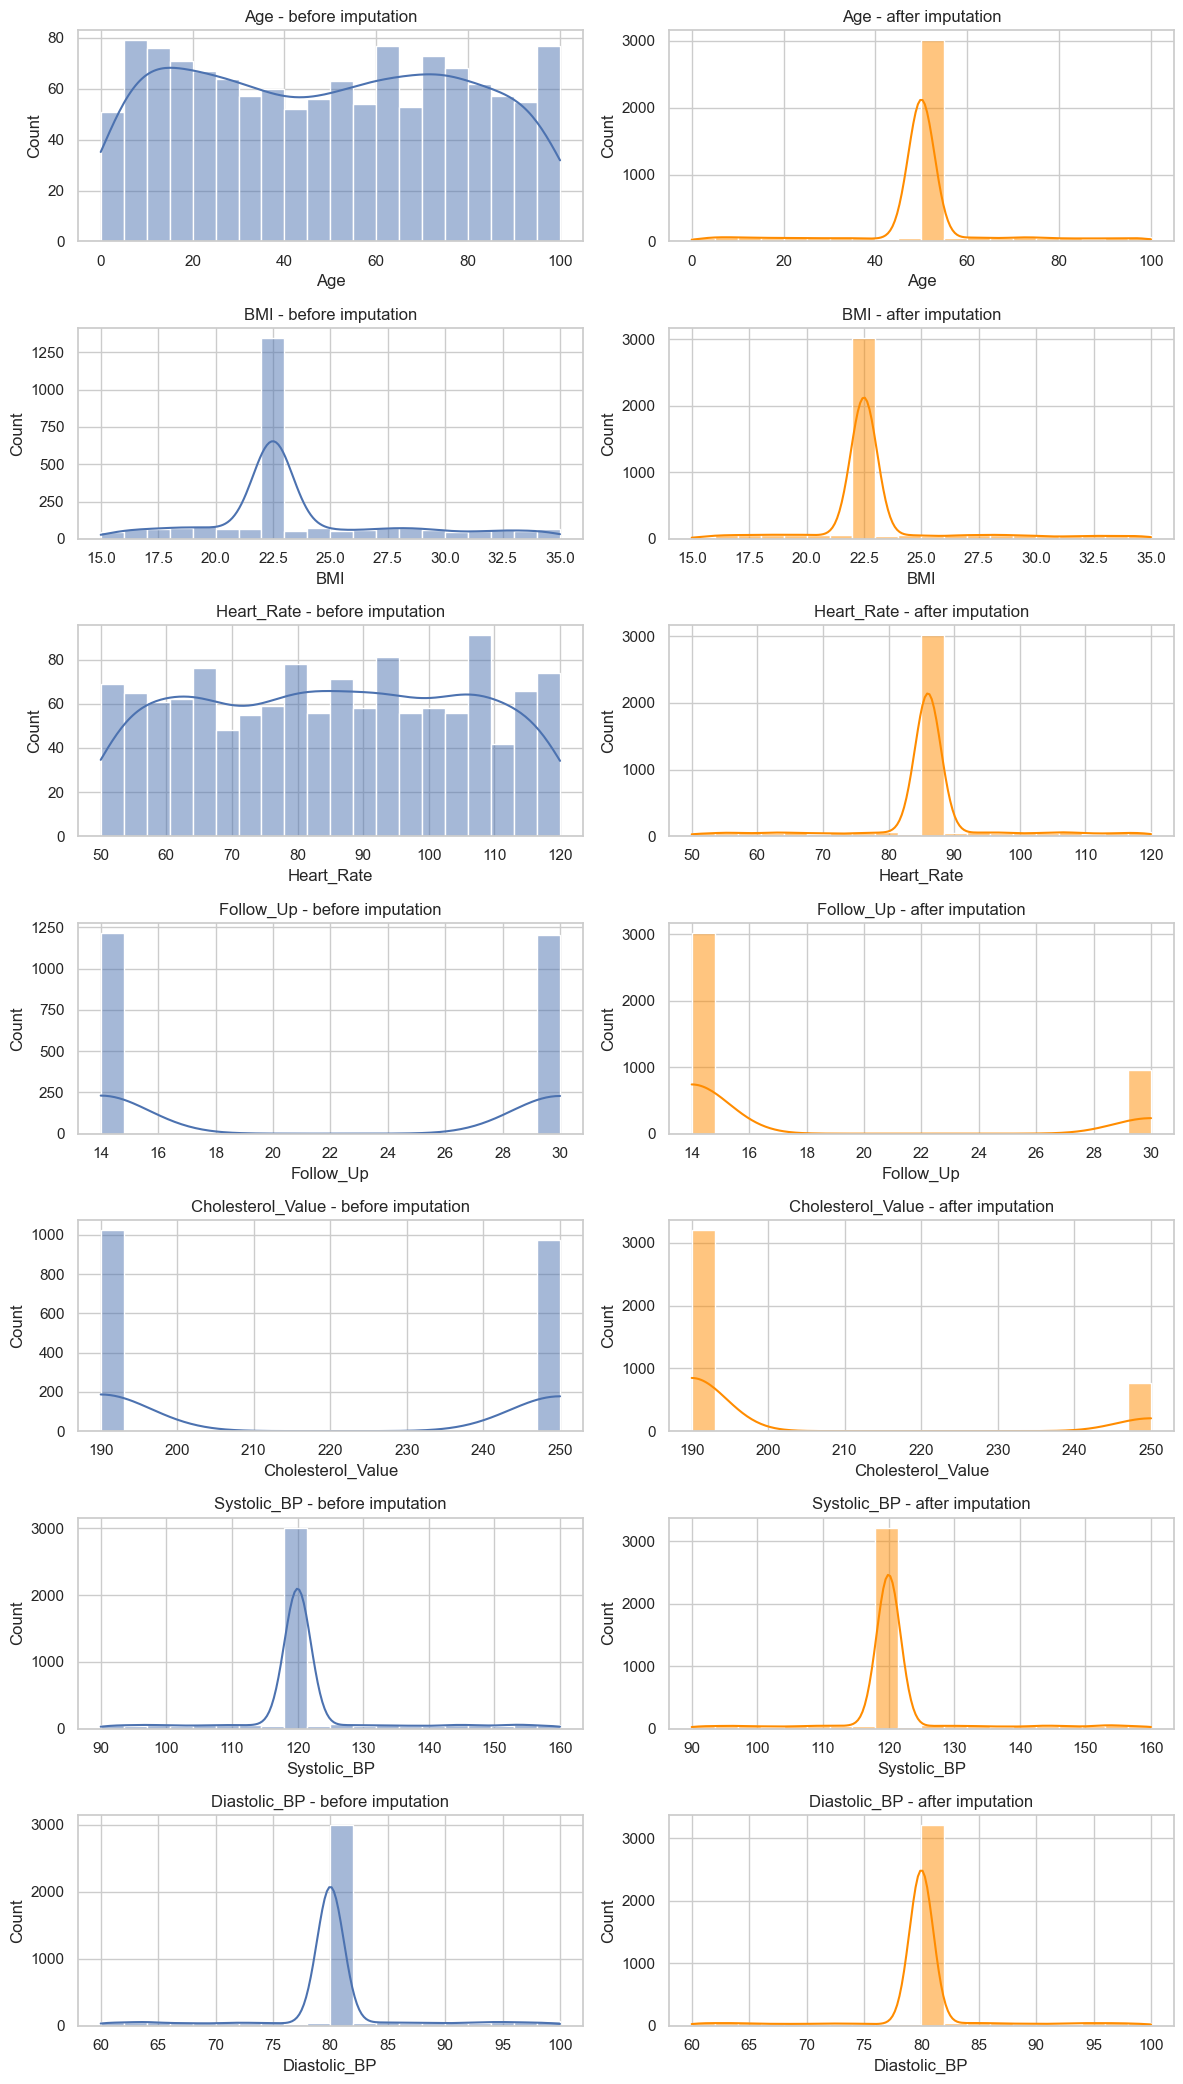

In [186]:
# Histograms: before (EDA data, blanks ignored) vs after imputation (training data)

fig, axes = plt.subplots(len(quan_train), 2, figsize=(12, 3 * len(quan_train)))
for r, col in enumerate(quan_train):
    sns.histplot(df[col].dropna().astype(float), bins=20, kde=True, ax=axes[r, 0])
    axes[r, 0].set_title(f"{col} - before imputation")
    sns.histplot(X_train[col].astype(float), bins=20, kde=True, ax=axes[r, 1], color="darkorange")
    axes[r, 1].set_title(f"{col} - after imputation")
plt.tight_layout()
plt.show()

**Business / health decision (after imputation)**

| Check | Before (EDA data) | After imputation (train) | Meaning |
|---|---|---|---|
| Median | Age 50, BMI 22.5, Heart rate 85, Follow-up 14, Cholesterol 190, Systolic 120, Diastolic 80 | unchanged (Heart rate 86) | the filled value is the median, so the typical patient does not change |
| Std. deviation | Age 29.4, Heart rate 20.5, BMI 4.15, Cholesterol 30.0 | Age 14.9, Heart rate 10.3, BMI 2.99, Cholesterol 23.7 | spread shrinks because 50-75% of the rows now hold the same value |
| IQR | 52 (Age), 36 (Heart rate), 2 (BMI) | 0 for every column | Q1 = median = Q3, so the IQR rule can no longer find outliers |
| Skewness / kurtosis | Age 0.03 / -1.25, BMI 0.88 / 0.73, Heart rate -0.01 / -1.19 | Age -0.08 / 3.88, BMI 1.69 / 4.93, Heart rate -0.22 / 4.12 | flat distributions become a sharp spike at the median |
| Categorical mode | Gender Female 50.5%, Diabetic No 51.5%, Smoker Former 50.7%, Medications Aspirin 66.0%, Cholesterol normal 52.2% | 67.3%, 67.5%, 66.4%, 79.7%, 81.4% | filling with the most frequent value inflates the biggest class |

**Decision:** use the median (not the mean) as the typical value, quote business numbers from the real values in the EDA section, and keep the `_was_missing` flags so the model can tell real readings from filled-in ones.

# Outlier capping (all numeric columns EXCEPT Systolic_BP and Diastolic_BP)
High and low blood pressure are the signal we want to keep, so BP is **not** capped. The other numeric columns are capped at the 1st and 99th percentile (winsorizing).

* Bounds are learned on **training data only**, from the **real (non-missing) values** (using the `_was_missing` flags). The IQR rule is not used because 60-75% of the values are the imputed median, so Q1 = Q3 and the IQR collapses to 0.
* The same bounds are applied to the test set.

In [187]:
cap_cols = ["Age", "BMI", "Heart_Rate", "Follow_Up", "Cholesterol_Value"]   # BP intentionally excluded
LOWER_Q, UPPER_Q = 0.01, 0.99

In [188]:
# Learn the bounds from real (non-missing) training values only
caps = {}
for c in cap_cols:
    real = pd.to_numeric(X_train.loc[X_train[f"{c}_was_missing"] == 0, c], errors="coerce").astype(float)
    caps[c] = (float(real.quantile(LOWER_Q)), float(real.quantile(UPPER_Q)))

print("Capping bounds (lower, upper):")
for c, b in caps.items():
    print(f"  {c:18s} {b[0]:.2f}  ->  {b[1]:.2f}")

Capping bounds (lower, upper):
  Age                1.00  ->  99.00
  BMI                15.60  ->  34.60
  Heart_Rate         50.00  ->  120.00
  Follow_Up          14.00  ->  30.00
  Cholesterol_Value  190.00  ->  250.00


In [189]:
def apply_caps(df, caps):
    df = df.copy()
    for c, (lo, hi) in caps.items():
        df[c] = pd.to_numeric(df[c], errors="coerce").astype(float).clip(lo, hi)
    return df

# snapshot before capping (used for the before / after plots)
X_train_precap = X_train[quan_train].astype(float).copy()

# Apply separately: train first, then test
X_train = apply_caps(X_train, caps)
X_test  = apply_caps(X_test,  caps)

## Save the outlier-capping bounds

In [190]:
with open("caps.pkl", "wb") as file:
    pickle.dump(caps, file)

# Numerical summary and analysis AFTER outlier capping

In [191]:
univariate(X_train[quan_train].astype(float), quan_train)

,Age,BMI,Heart_Rate,Follow_Up,Cholesterol_Value,Systolic_BP,Diastolic_BP
mean,49.821177,23.042254,85.80508,17.83501,201.649899,121.090543,80.008551
median,50.0,22.5,86.0,14.0,190.0,120.0,80.0
mode,50.0,22.5,86.0,14.0,190.0,120.0,80.0
Q1:25%,50.0,22.5,86.0,14.0,190.0,120.0,80.0
Q2:50%,50.0,22.5,86.0,14.0,190.0,120.0,80.0
Q3:75%,50.0,22.5,86.0,14.0,190.0,120.0,80.0
Q4:100%,99.0,34.6,120.0,30.0,250.0,160.0,100.0
99%,97.0,34.2,118.0,30.0,250.0,157.0,98.0
IQR,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1.5rule,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [192]:
# 1st Moment - Mean, median, mode (after outlier capping)

print(X_train[quan_train].astype(float).mean())
print('\n')
print(X_train[quan_train].astype(float).median())
print('\n')
print(X_train[quan_train].astype(float).mode().iloc[0])

Age                   49.821177
BMI                   23.042254
Heart_Rate            85.805080
Follow_Up             17.835010
Cholesterol_Value    201.649899
Systolic_BP          121.090543
Diastolic_BP          80.008551
dtype: float64


Age                   50.0
BMI                   22.5
Heart_Rate            86.0
Follow_Up             14.0
Cholesterol_Value    190.0
Systolic_BP          120.0
Diastolic_BP          80.0
dtype: float64


Age                   50.0
BMI                   22.5
Heart_Rate            86.0
Follow_Up             14.0
Cholesterol_Value    190.0
Systolic_BP          120.0
Diastolic_BP          80.0
Name: 0, dtype: float64


In [193]:
# 2nd Moment - Variance, standard deviation, range (after outlier capping)

print(X_train[quan_train].astype(float).var())
print('\n')
print(X_train[quan_train].astype(float).std())
print('\n')
print(X_train[quan_train].astype(float).max() - X_train[quan_train].astype(float).min())

Age                  222.211285
BMI                    8.922828
Heart_Rate           107.112940
Follow_Up             46.664595
Cholesterol_Value    563.415512
Systolic_BP           91.756328
Diastolic_BP          29.346342
dtype: float64


Age                  14.906753
BMI                   2.987110
Heart_Rate           10.349538
Follow_Up             6.831149
Cholesterol_Value    23.736375
Systolic_BP           9.578952
Diastolic_BP          5.417226
dtype: float64


Age                  98.0
BMI                  19.0
Heart_Rate           70.0
Follow_Up            16.0
Cholesterol_Value    60.0
Systolic_BP          70.0
Diastolic_BP         40.0
dtype: float64


In [194]:
# 3rd and 4th Moment - Skewness and kurtosis at every stage so far

moments_stage = pd.DataFrame({
    "skew: EDA data": df[quan_train].astype(float).skew(),
    "skew: imputed": skew_imputed,
    "skew: capped": X_train[quan_train].astype(float).skew(),
    "kurtosis: EDA data": df[quan_train].astype(float).kurtosis(),
    "kurtosis: imputed": kurt_imputed,
    "kurtosis: capped": X_train[quan_train].astype(float).kurtosis()})
moments_stage.round(3)

,skew: EDA data,skew: imputed,skew: capped,kurtosis: EDA data,kurtosis: imputed,kurtosis: capped
Age,0.026,-0.080,-0.081,-1.248,3.878,3.866
BMI,0.879,1.691,1.693,0.734,4.934,4.897
Heart_Rate,-0.012,-0.221,-0.221,-1.187,4.121,4.121
Follow_Up,0.010,1.220,1.220,-2.002,-0.512,-0.512
Cholesterol_Value,0.051,1.547,1.547,-1.999,0.393,0.393
Systolic_BP,1.039,1.264,1.264,4.255,6.020,6.020
Diastolic_BP,-0.058,-0.097,-0.097,3.955,5.737,5.737


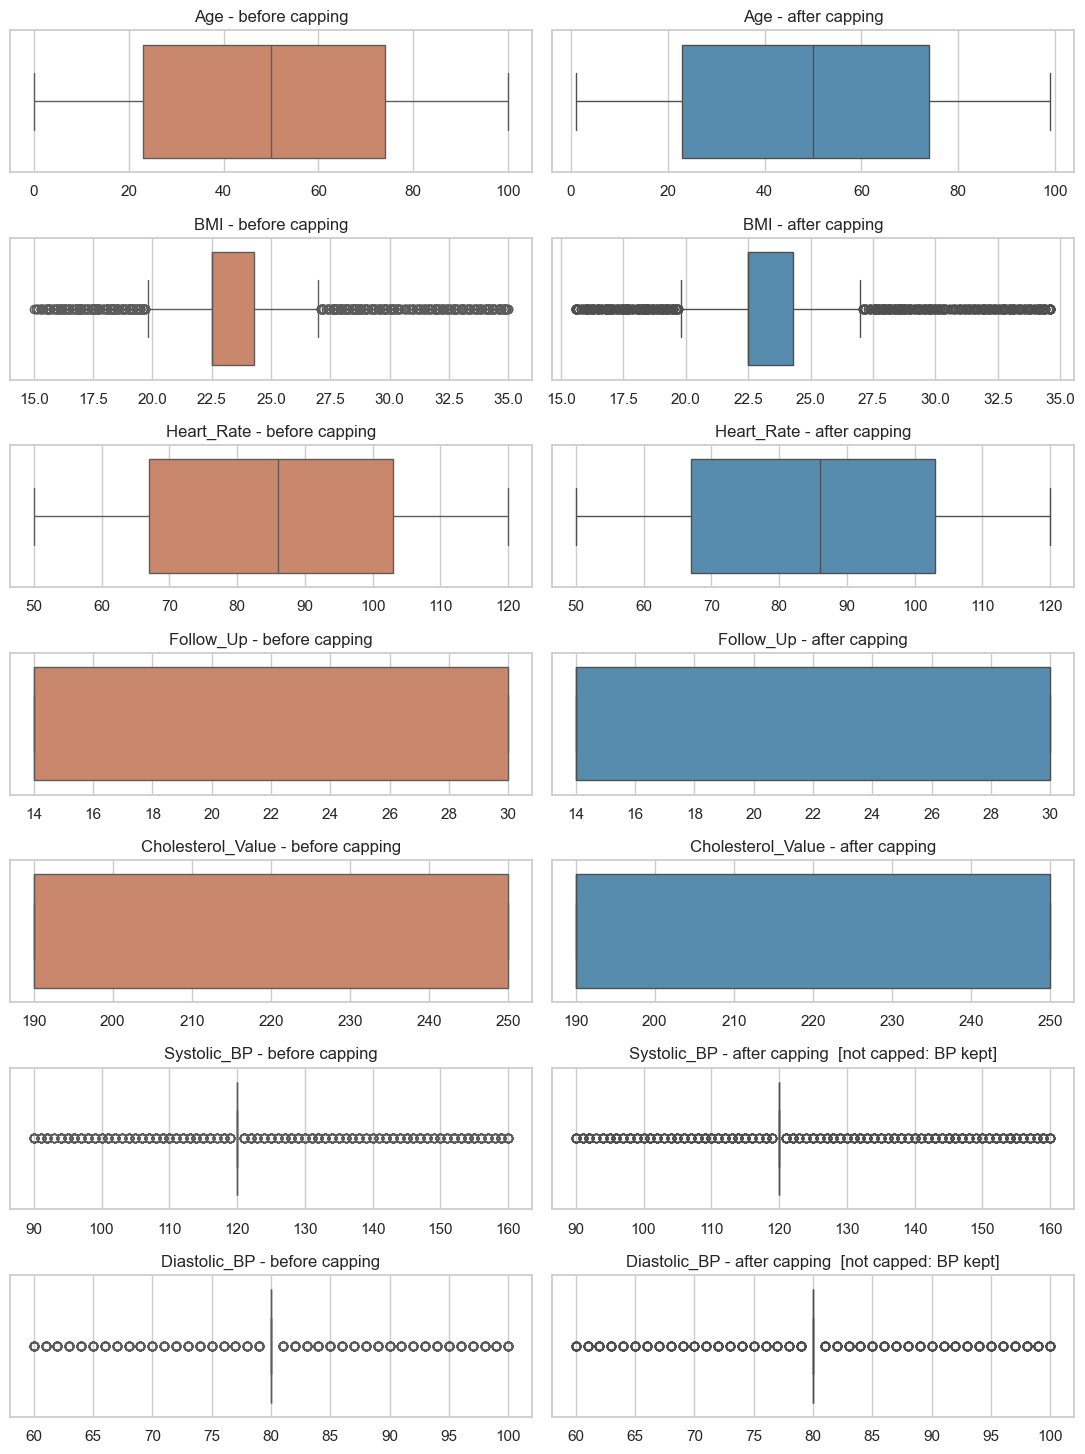

In [195]:
# Box plots: before vs after capping (training data, real non-missing values only)

def real_values(frame, c):
    return frame.loc[X_train[f"{c}_was_missing"] == 0, c].astype(float)

fig, axes = plt.subplots(len(quan_train), 2, figsize=(11, 2.1 * len(quan_train)))
for r, c in enumerate(quan_train):
    sns.boxplot(x=real_values(X_train_precap, c), ax=axes[r, 0], color="#d9825b")
    axes[r, 0].set_title(f"{c} - before capping")
    axes[r, 0].set_xlabel("")
    sns.boxplot(x=real_values(X_train, c), ax=axes[r, 1], color="#4a8fbd")
    axes[r, 1].set_title(f"{c} - after capping" + ("" if c in caps else "  [not capped: BP kept]"))
    axes[r, 1].set_xlabel("")
plt.tight_layout()
plt.show()

In [196]:
# Outlier check: values outside the capping bounds must be 0 after capping

def iqr_outliers(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

rows = []
for c in quan_train:
    before_v, after_v = real_values(X_train_precap, c), real_values(X_train, c)
    row = {"Feature": c,
           "min before": round(before_v.min(), 2), "max before": round(before_v.max(), 2),
           "min after": round(after_v.min(), 2), "max after": round(after_v.max(), 2),
           "IQR outliers before": iqr_outliers(before_v), "IQR outliers after": iqr_outliers(after_v)}
    if c in caps:
        lo, hi = caps[c]
        allv = X_train[c].astype(float)
        row["values outside bounds"] = int(((allv < lo - 1e-9) | (allv > hi + 1e-9)).sum())
    else:
        row["values outside bounds"] = "not capped"
    rows.append(row)
pd.DataFrame(rows)

,Feature,min before,max before,min after,max after,IQR outliers before,IQR outliers after,values outside bounds
0,Age,0.0,100.0,1.0,99.0,0,0,0
1,BMI,15.0,35.0,15.6,34.6,630,630,0
2,Heart_Rate,50.0,120.0,50.0,120.0,0,0,0
3,Follow_Up,14.0,30.0,14.0,30.0,0,0,0
4,Cholesterol_Value,190.0,250.0,190.0,250.0,0,0,0
5,Systolic_BP,90.0,160.0,90.0,160.0,795,795,not capped
6,Diastolic_BP,60.0,100.0,60.0,100.0,783,783,not capped


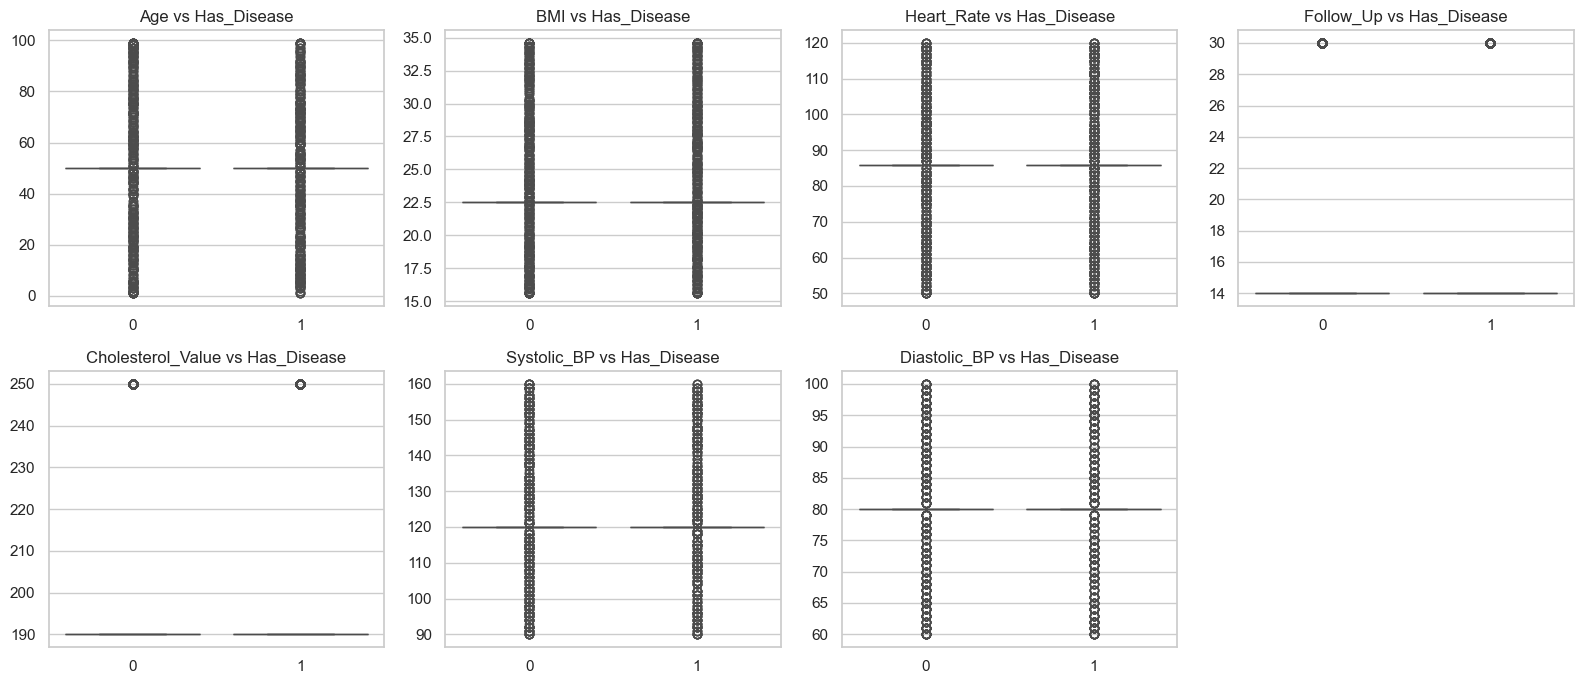

In [197]:
# Bivariate analysis after capping: numerical features vs target (training data)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), quan_train):
    sns.boxplot(x=Y_train["Has_Disease"].values, y=X_train[c].astype(float).values, ax=ax)
    ax.set_title(f"{c} vs Has_Disease")
axes.ravel()[-1].set_visible(False)
plt.tight_layout()
plt.show()

Age                 -0.025406
Cholesterol_Value   -0.001569
Systolic_BP          0.005391
BMI                  0.008067
Diastolic_BP         0.010807
Heart_Rate           0.016224
Follow_Up            0.018960
Has_Disease          1.000000
Name: Has_Disease, dtype: float64


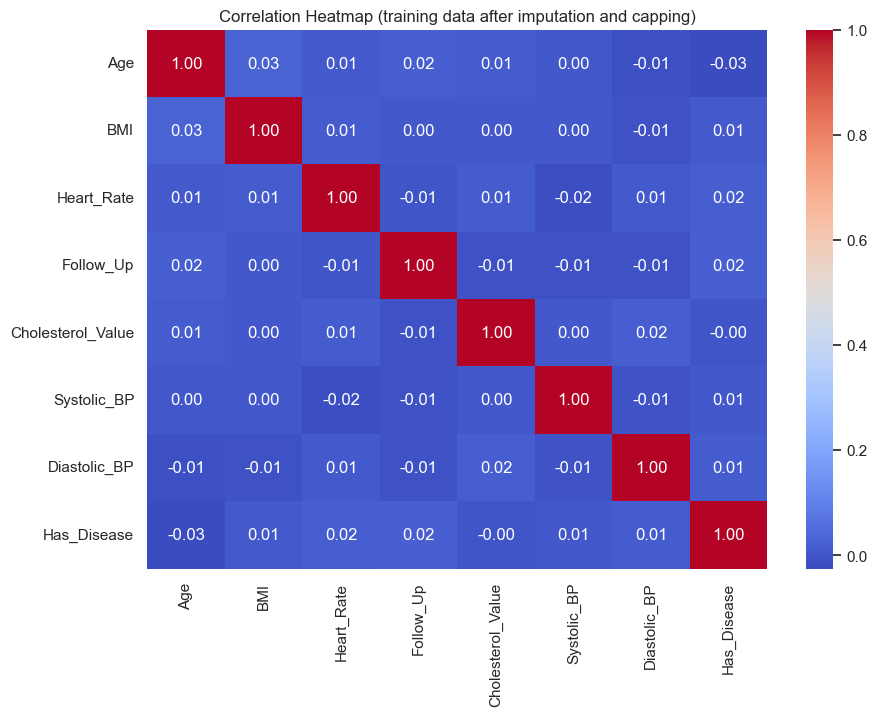

In [198]:
# Multivariate analysis after capping: correlation with the target and heatmap

train_corr = X_train[quan_train].astype(float).copy()
train_corr["Has_Disease"] = Y_train["Has_Disease"].values

print(train_corr.corr()["Has_Disease"].sort_values())

plt.figure(figsize=(10, 7))
sns.heatmap(train_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap (training data after imputation and capping)")
plt.show()

In [199]:
# Covariance after capping
train_corr.cov()

,Age,BMI,Heart_Rate,Follow_Up,Cholesterol_Value,Systolic_BP,Diastolic_BP,Has_Disease
Age,222.211285,1.267533,1.119097,1.772753,4.559265,0.109529,-1.150169,-0.189347
BMI,1.267533,8.922828,0.415509,0.088281,0.340834,0.125733,-0.153493,0.012048
Heart_Rate,1.119097,0.415509,107.112940,-0.371287,3.010987,-2.104359,0.579277,0.083950
Follow_Up,1.772753,0.088281,-0.371287,46.664595,-1.941551,-0.737762,-0.447394,0.064755
Cholesterol_Value,4.559265,0.340834,3.010987,-1.941551,563.415512,0.937368,2.255070,-0.018617
Systolic_BP,0.109529,0.125733,-2.104359,-0.737762,0.937368,91.756328,-0.429202,0.025817
Diastolic_BP,-1.150169,-0.153493,0.579277,-0.447394,2.255070,-0.429202,29.346342,0.029268
Has_Disease,-0.189347,0.012048,0.083950,0.064755,-0.018617,0.025817,0.029268,0.249962


**Business / health decision (after outlier capping)**

* Capping bounds (1% / 99% of the real training values): Age 1-99, BMI 15.6-34.6, Heart rate 50-120, Follow-up 14-30, Cholesterol 190-250.
* Only Age (0 -> 1, 100 -> 99) and BMI (15 -> 15.6, 35 -> 34.6) actually change; Heart rate, Follow-up and Cholesterol were already inside their bounds, so the cleaning rules (age 0-120, heart rate 1-200) had already removed the impossible values. Mean, variance, skewness and kurtosis are therefore almost identical before and after capping (for example Age std 14.92 -> 14.91, BMI kurtosis 4.93 -> 4.90).
* After capping **0 values are outside the bounds**. The IQR-rule outliers (BMI 630, Systolic 795, Diastolic 783) do not change: they are real readings away from the median spike, not errors. Systolic_BP and Diastolic_BP are deliberately not capped so high and low blood pressure (90-160 / 60-100) is kept.
* Bivariate and multivariate view: every numeric feature has almost the same distribution for Has_Disease = 0 and 1, and all correlations with the target are within +/-0.03 (Age -0.025 is the largest), so there is no linear relationship and the numeric features are almost independent of each other.

**Decision:** capping is safe but has little effect on this data; blood pressure is the only place where extreme values carry clinical meaning, so it stays uncapped.

# Feature engineering 
## Atribute construction

# Medication count

In [200]:
# Count the number of medications
def add_medication_count(df):
    df = df.copy()

    df["Medication_Count"] = (
        df["Medications"]
        .fillna("")
        .str.split(";")
        .apply(lambda x: len([med for med in x if med.strip() != ""]))
    )

    return df


# Apply separately
X_train = add_medication_count(X_train)
X_test = add_medication_count(X_test)

# Age_group

In [201]:
def add_age_group(df):
    df = df.copy()

    df["Age_Group"] = pd.cut(
        df["Age"],
        bins=[0, 18, 40, 60, 100],
        labels=["Young", "Adult", "Middle_Age", "Senior"]
    )

    return df


X_train = add_age_group(X_train)
X_test = add_age_group(X_test)

# BMI category

In [202]:
def add_bmi_category(df):
    df = df.copy()

    df["BMI_Category"] = pd.cut(
        df["BMI"],
        bins=[0, 18.5, 25, 30, 100],
        labels=["Underweight", "Normal", "Overweight", "Obese"]
    )

    return df


X_train = add_bmi_category(X_train)
X_test = add_bmi_category(X_test)

# BP category

In [203]:
def add_bp_category(df):
    df = df.copy()

    sys = pd.to_numeric(df["Systolic_BP"], errors="coerce").to_numpy(dtype=float)
    dia = pd.to_numeric(df["Diastolic_BP"], errors="coerce").to_numpy(dtype=float)

    df["BP_Category"] = np.select(
        [
            (sys < 120) & (dia < 80),
            (sys < 130) & (dia < 80),
            (sys >= 130) | (dia >= 80),
        ],
        ["Normal", "Elevated", "Hypertensive"],
        default="Unknown",
    )
    return df

# Risk score

In [204]:
def add_risk_score(df):
    df = df.copy()

    # Safe conversions (handles Int64 / <NA> / NaN)
    age = pd.to_numeric(df["Age"], errors="coerce").astype(float)
    bmi = pd.to_numeric(df["BMI"], errors="coerce").astype(float)
    sys = pd.to_numeric(df["Systolic_BP"], errors="coerce").astype(float)
    dia = pd.to_numeric(df["Diastolic_BP"], errors="coerce").astype(float)
    hr  = pd.to_numeric(df["Heart_Rate"], errors="coerce").astype(float)

    chol     = df["Cholesterol_Status"].astype("string").str.lower()
    smoker   = df["Smoker"].astype("string").str.lower()
    diabetic = df["Diabetic"].astype("string").str.lower()

    def pts(cond, p):
        # missing comparison -> False -> 0 points
        return cond.fillna(False).astype(int) * p

    score = (
        pts(age >= 60, 2) + pts((age >= 45) & (age < 60), 1)
        + pts(bmi >= 30, 2) + pts((bmi >= 25) & (bmi < 30), 1)
        + pts((sys >= 130) | (dia >= 85), 2)
        + pts(hr > 100, 1)
        + pts(chol == "high", 2)
        + pts(diabetic == "yes", 2)
        + pts(smoker == "yes", 2) + pts(smoker == "former", 1)
    )

    df["Risk_Points"] = score
    df["Risk_Score"] = pd.cut(
        score, bins=[-1, 2, 5, 100], labels=["Low", "Medium", "High"]
    ).astype(str)

    return df

X_train = add_risk_score(X_train)
X_test = add_risk_score(X_test)

print(X_train["Risk_Score"].value_counts())

Risk_Score
Medium    2153
Low       1319
High       504
Name: count, dtype: int64


In [205]:
# Check the column names in X_train
print(X_train.columns)

Index(['Age', 'Gender', 'BMI', 'Heart_Rate', 'Diabetic', 'Smoker',
       'Medications', 'Follow_Up', 'Cholesterol_Value', 'Cholesterol_Status',
       'Systolic_BP', 'Diastolic_BP', 'Visit_Year', 'Age_was_missing',
       'BMI_was_missing', 'Heart_Rate_was_missing', 'Follow_Up_was_missing',
       'Cholesterol_Value_was_missing', 'Systolic_BP_was_missing',
       'Diastolic_BP_was_missing', 'Gender_was_missing',
       'Diabetic_was_missing', 'Smoker_was_missing', 'Medications_was_missing',
       'Cholesterol_Status_was_missing', 'Visit_Year_was_missing',
       'Medication_Count', 'Age_Group', 'BMI_Category', 'Risk_Points',
       'Risk_Score'],
      dtype='object')


In [206]:
# Check the column names in X_train
print(X_test.columns)

Index(['Age', 'Gender', 'BMI', 'Heart_Rate', 'Diabetic', 'Smoker',
       'Medications', 'Follow_Up', 'Cholesterol_Value', 'Cholesterol_Status',
       'Systolic_BP', 'Diastolic_BP', 'Visit_Year', 'Age_was_missing',
       'BMI_was_missing', 'Heart_Rate_was_missing', 'Follow_Up_was_missing',
       'Cholesterol_Value_was_missing', 'Systolic_BP_was_missing',
       'Diastolic_BP_was_missing', 'Gender_was_missing',
       'Diabetic_was_missing', 'Smoker_was_missing', 'Medications_was_missing',
       'Cholesterol_Status_was_missing', 'Visit_Year_was_missing',
       'Medication_Count', 'Age_Group', 'BMI_Category', 'Risk_Points',
       'Risk_Score'],
      dtype='object')


In [207]:
new_cols = [
    "Medication_Count",
    "Age_Group",
    "BMI_Category",
    "Risk_Score"
]

print(X_train[new_cols].head())

      Medication_Count   Age_Group BMI_Category Risk_Score
2244                 2  Middle_Age       Normal     Medium
326                  2  Middle_Age  Underweight       High
252                  2  Middle_Age       Normal     Medium
1249                 2  Middle_Age       Normal     Medium
3513                 2  Middle_Age        Obese       High


In [208]:
print("X_train:")
print(X_train[new_cols].head())

X_train:
      Medication_Count   Age_Group BMI_Category Risk_Score
2244                 2  Middle_Age       Normal     Medium
326                  2  Middle_Age  Underweight       High
252                  2  Middle_Age       Normal     Medium
1249                 2  Middle_Age       Normal     Medium
3513                 2  Middle_Age        Obese       High


In [209]:
print("\nX_test:")
print(X_test[new_cols].head())


X_test:
      Medication_Count   Age_Group BMI_Category Risk_Score
3130                 2  Middle_Age        Obese       High
2109                 2       Young       Normal     Medium
2782                 2  Middle_Age       Normal        Low
1092                 2  Middle_Age       Normal     Medium
3977                 2  Middle_Age       Normal        Low


# Transformation to a more normal distribution (Yeo-Johnson)
Done **after feature engineering** because Age_Group, BMI_Category and Risk_Score need real units (years, kg/m², mmHg). A separate `PowerTransformer` is fitted per column on the **training** data and applied to the test data. Yeo-Johnson keeps the order of values, so high and low blood pressure stay high and low.

Because 60-75% of many columns equal the imputed median, the result becomes *less skewed* but cannot become perfectly bell-shaped (a spike at the median always remains).

In [210]:
from sklearn.preprocessing import PowerTransformer

# Follow_Up (14 / 30) and Cholesterol_Value (190 / 250) have only two distinct values: a power transform cannot make
# them normal and Yeo-Johnson pushes both values onto (almost) the same number, so they are left as they are.
transform_cols = ["Age", "BMI", "Heart_Rate", "Systolic_BP", "Diastolic_BP"]

# snapshot of all numeric columns before transformation (used for the comparison tables and QQ plots)
X_train_pretransform = X_train[quan_train].astype(float).copy()

In [211]:
power_transformers = {}

for c in transform_cols:
    pt = PowerTransformer(method="yeo-johnson", standardize=False)
    X_train[c] = pt.fit_transform(X_train[[c]].astype(float)).ravel()   # fit on train only
    X_test[c]  = pt.transform(X_test[[c]].astype(float)).ravel()        # reuse the same fit
    power_transformers[c] = pt

## Save the Yeo-Johnson transformers

In [212]:
with open("power_transformers.pkl", "wb") as file:
    pickle.dump(power_transformers, file)

# Numerical summary and analysis AFTER transformation

In [213]:
univariate(X_train[quan_train].astype(float), quan_train)

,Age,BMI,Heart_Rate,Follow_Up,Cholesterol_Value,Systolic_BP,Diastolic_BP
mean,79.94528,0.911313,372.607805,17.83501,201.649899,1.517393,272.772977
median,79.59478,0.911001,372.271088,14.0,190.0,1.517184,272.450495
mode,79.59478,0.911001,372.271088,14.0,190.0,1.517184,272.450495
Q1:25%,79.59478,0.911001,372.271088,14.0,190.0,1.517184,272.450495
Q2:50%,79.59478,0.911001,372.271088,14.0,190.0,1.517184,272.450495
Q3:75%,79.59478,0.911001,372.271088,14.0,190.0,1.517184,272.450495
Q4:100%,173.898615,0.922874,591.505795,30.0,250.0,1.530149,366.765046
99%,169.878334,0.922616,577.832254,30.0,250.0,1.529365,357.018265
IQR,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1.5rule,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [214]:
# Skewness and kurtosis before vs after the transformation

pd.DataFrame({
    "skew before": X_train_pretransform.skew(),
    "skew after": X_train[quan_train].astype(float).skew(),
    "kurtosis before": X_train_pretransform.kurtosis(),
    "kurtosis after": X_train[quan_train].astype(float).kurtosis()}).round(3)

,skew before,skew after,kurtosis before,kurtosis after
Age,-0.081,0.367,3.866,3.925
BMI,1.693,-0.160,4.897,4.274
Heart_Rate,-0.221,0.224,4.121,4.130
Follow_Up,1.220,1.220,-0.512,-0.512
Cholesterol_Value,1.547,1.547,0.393,0.393
Systolic_BP,1.264,-0.093,6.020,5.986
Diastolic_BP,-0.097,0.171,5.737,5.737


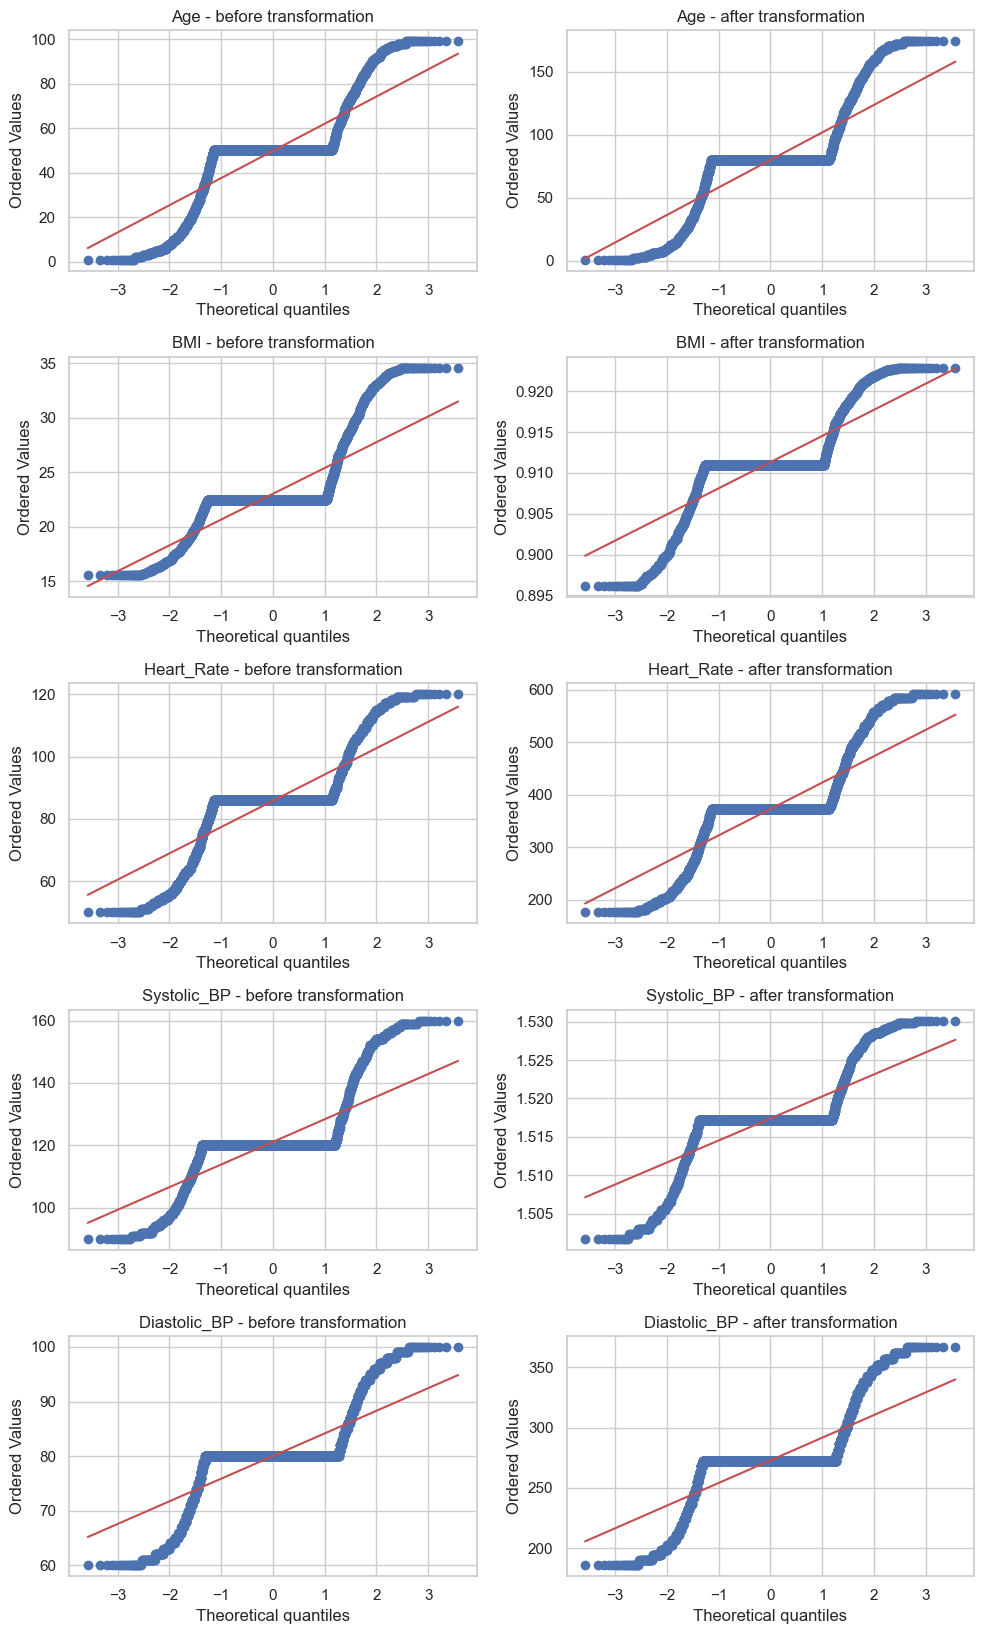

In [215]:
# QQ plots before vs after transformation (all training values = what the model sees)

fig, axes = plt.subplots(len(transform_cols), 2, figsize=(10, 3.3 * len(transform_cols)))
for r, c in enumerate(transform_cols):
    stats.probplot(X_train_pretransform[c].dropna(), dist="norm", plot=axes[r, 0])
    axes[r, 0].set_title(f"{c} - before transformation")
    stats.probplot(X_train[c].astype(float).dropna(), dist="norm", plot=axes[r, 1])
    axes[r, 1].set_title(f"{c} - after transformation")
plt.tight_layout()
plt.show()

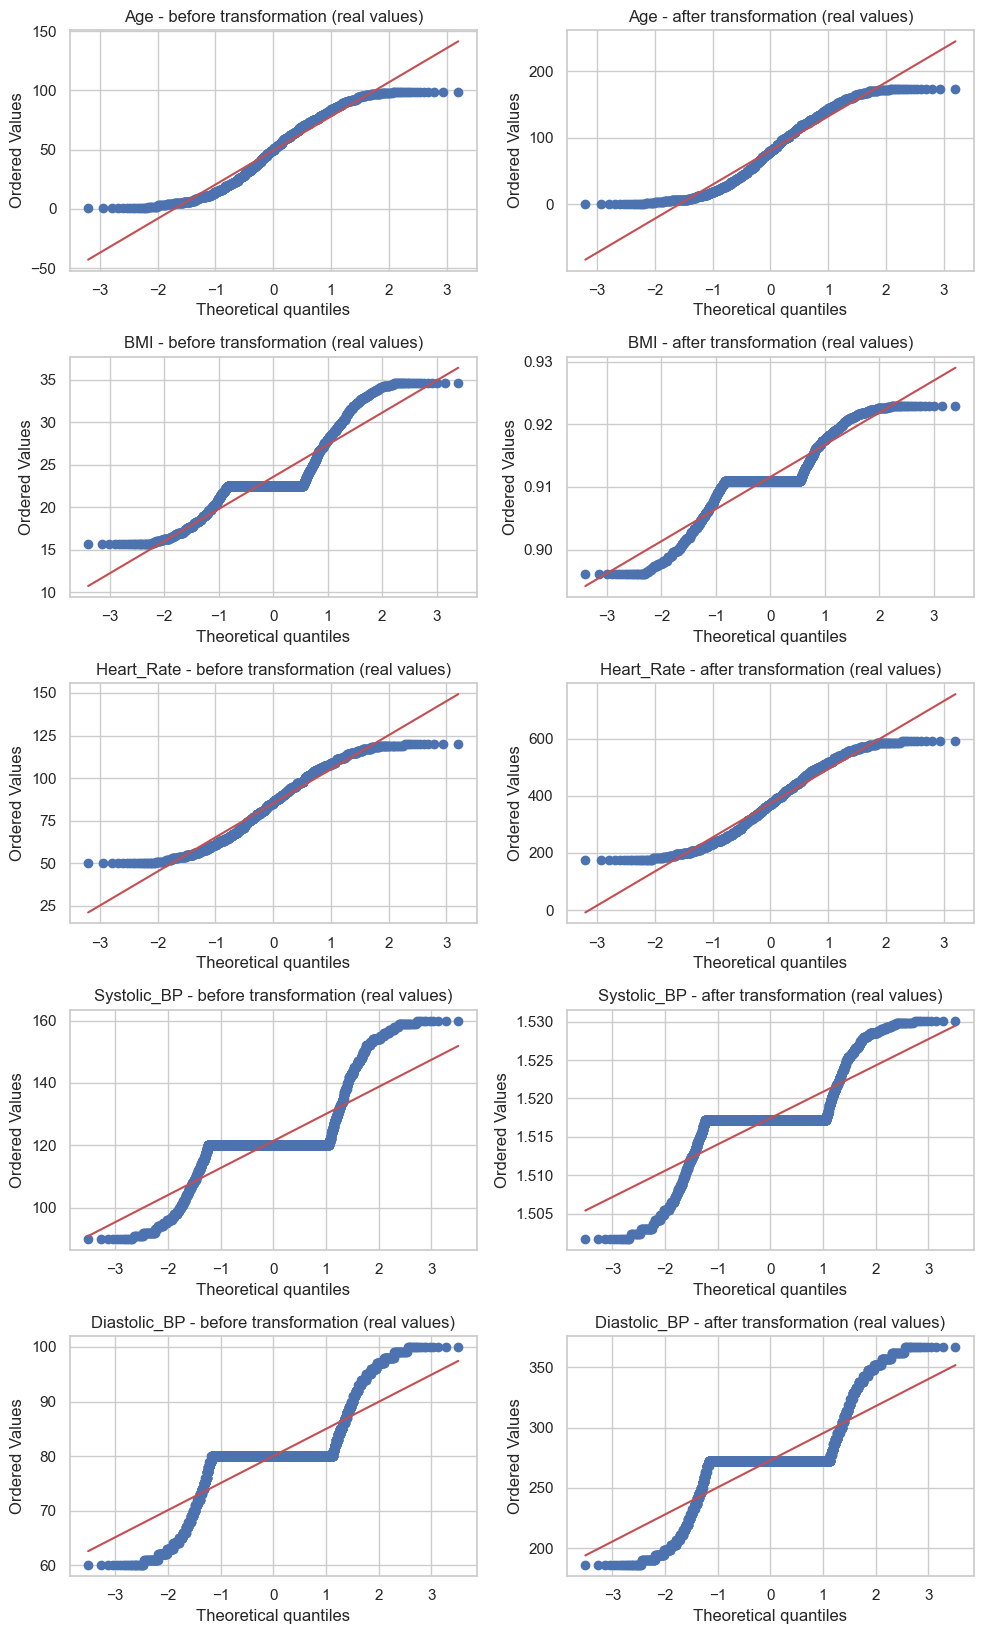

In [216]:
# QQ plots on real (non-missing) values only: the true effect of the transformation

fig, axes = plt.subplots(len(transform_cols), 2, figsize=(10, 3.3 * len(transform_cols)))
for r, c in enumerate(transform_cols):
    real = (X_train[f"{c}_was_missing"] == 0).values
    stats.probplot(X_train_pretransform[c][real].dropna(), dist="norm", plot=axes[r, 0])
    axes[r, 0].set_title(f"{c} - before transformation (real values)")
    stats.probplot(X_train[c].astype(float)[real].dropna(), dist="norm", plot=axes[r, 1])
    axes[r, 1].set_title(f"{c} - after transformation (real values)")
plt.tight_layout()
plt.show()

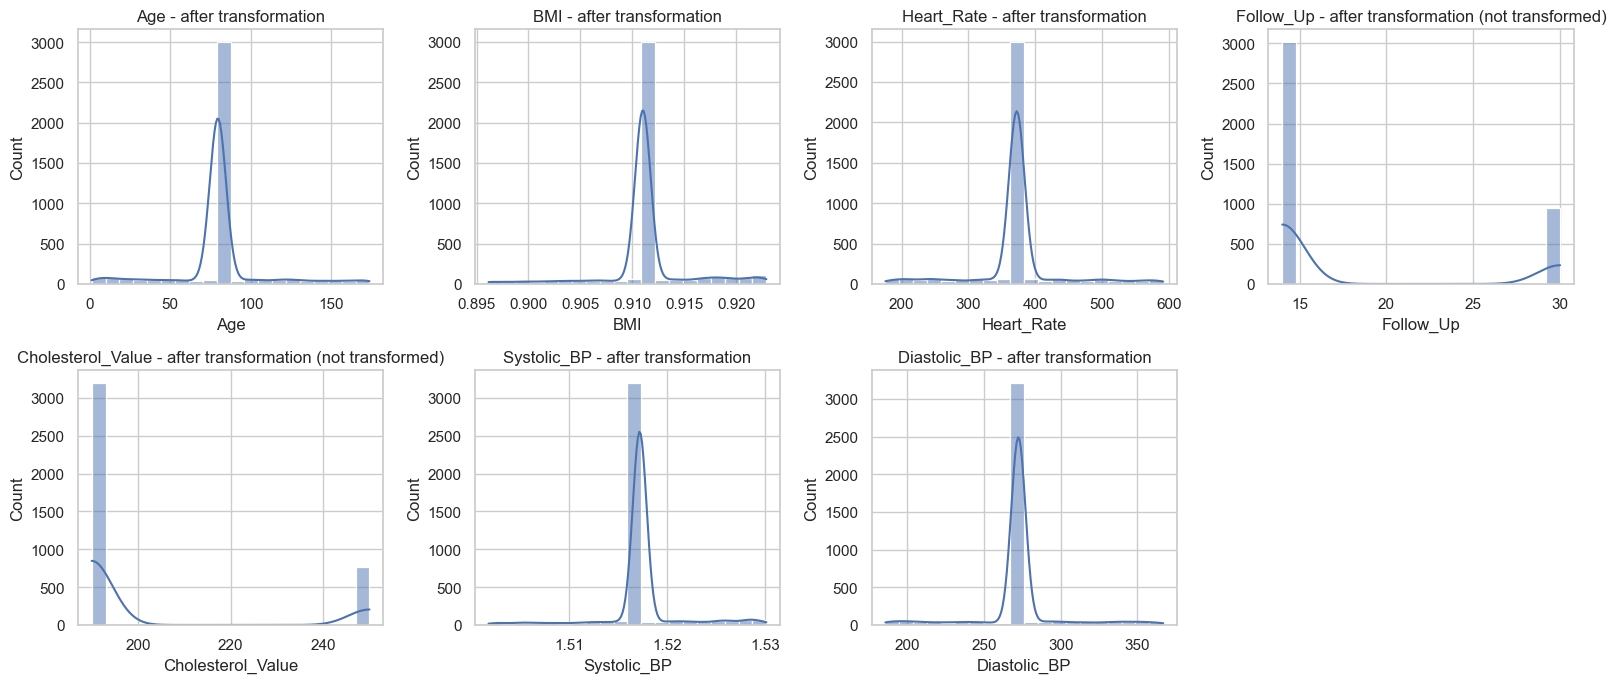

In [217]:
# Histograms after transformation

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), quan_train):
    sns.histplot(X_train[c].astype(float), bins=20, kde=True, ax=ax)
    ax.set_title(f"{c} - after transformation" + ("" if c in transform_cols else " (not transformed)"))
axes.ravel()[-1].set_visible(False)
plt.tight_layout()
plt.show()

**Business / health decision (after transformation)**

* Yeo-Johnson reduces the skew of the continuous columns: BMI 1.69 -> -0.16, Systolic_BP 1.26 -> -0.09; Age (-0.08 -> 0.37), Heart_Rate (-0.22 -> 0.22) and Diastolic_BP (-0.10 -> 0.17) stay within about +/-0.4, so all five are fairly symmetric.
* Kurtosis is **not** fixed (about 4-6 before and after) and the QQ plots keep a flat step in the middle, because 50-75% of the values equal the imputed median. The data become *less skewed*, not perfectly normal.
* Follow_Up (14 / 30) and Cholesterol_Value (190 / 250) have only two distinct values; Yeo-Johnson picked lambda = -5.3 and -18.2 and mapped both values to (almost) the same number, which would remove the information, so these two columns are left untransformed.
* High and low blood pressure keep their order after the transformation, so they are still high and low.

**Decision:** the transformation helps distance-based and linear models (KNN, Logistic Regression); tree-based models do not need it. Keep the saved transformers for deployment.

# Identify categorical and numerical columns

In [218]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

onehot_cols = [
    "Gender",
    "Diabetic",
    "Smoker",
    "Medications",
    "Cholesterol_Status"
]

ordinal_cols = [
    "Age_Group",
    "BMI_Category",
    "Risk_Score"
]

numerical_cols = [
    "Age",
    "BMI",
    "Heart_Rate",
    "Follow_Up",
    "Cholesterol_Value",
    "Systolic_BP",
    "Diastolic_BP",
    "Visit_Year",
    "Medication_Count"
]

# add the missing-value flags created before imputation
numerical_cols = numerical_cols + flag_cols

# Create and fit the encoder

In [219]:
# 2. One-Hot Encoding (drop first category)

encoder = OneHotEncoder(
    handle_unknown="ignore",
    drop="first",
    sparse_output=False
)

X_train_cat = encoder.fit_transform(X_train[onehot_cols])
X_test_cat = encoder.transform(X_test[onehot_cols])

# Get One-Hot feature names
onehot_feature_names = encoder.get_feature_names_out(onehot_cols)

X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=onehot_feature_names,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=onehot_feature_names,
    index=X_test.index
)


In [220]:
# 3. Ordinal Encoding

ordinal_encoder = OrdinalEncoder(
    categories=[
        ["Young", "Adult", "Middle_Age", "Senior"],
        ["Underweight", "Normal", "Overweight", "Obese"],
        ["Low", "Medium", "High"]
    ],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train_ord = ordinal_encoder.fit_transform(X_train[ordinal_cols])
X_test_ord = ordinal_encoder.transform(X_test[ordinal_cols])

X_train_ord = pd.DataFrame(
    X_train_ord,
    columns=ordinal_cols,
    index=X_train.index
)

X_test_ord = pd.DataFrame(
    X_test_ord,
    columns=ordinal_cols,
    index=X_test.index
)



# Keep numerical columns

In [221]:
# 4. Keep numerical columns and combine all encoded columns

X_train_num = X_train[numerical_cols].copy()
X_test_num = X_test[numerical_cols].copy()



# Combine numerical + encoded categorical columns

In [222]:
X_train_encoded = pd.concat(
    [X_train_num, X_train_cat, X_train_ord],
    axis=1
)

X_test_encoded = pd.concat(
    [X_test_num, X_test_cat, X_test_ord],
    axis=1
)

# Save the encoder

In [223]:
# 5. Save both encoders

with open("onehot_encoder.pkl", "wb") as file:
    pickle.dump(encoder, file)

with open("ordinal_encoder.pkl", "wb") as file:
    pickle.dump(ordinal_encoder, file)

In [224]:
with open("encoded_columns.pkl", "wb") as file:
    pickle.dump(list(X_train_encoded.columns), file)

In [225]:
# 6. Check the final encoded data

print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)

Training data shape: (3976, 29)
Testing data shape: (995, 29)


In [226]:
print("\nEncoded training columns:")
print(X_train_encoded.columns.tolist())


Encoded training columns:
['Age', 'BMI', 'Heart_Rate', 'Follow_Up', 'Cholesterol_Value', 'Systolic_BP', 'Diastolic_BP', 'Visit_Year', 'Medication_Count', 'Age_was_missing', 'BMI_was_missing', 'Heart_Rate_was_missing', 'Follow_Up_was_missing', 'Cholesterol_Value_was_missing', 'Systolic_BP_was_missing', 'Gender_was_missing', 'Diabetic_was_missing', 'Smoker_was_missing', 'Medications_was_missing', 'Visit_Year_was_missing', 'Gender_Male', 'Diabetic_Yes', 'Smoker_No', 'Smoker_Yes', 'Medications_Lisinopril; Metformin', 'Cholesterol_Status_normal', 'Age_Group', 'BMI_Category', 'Risk_Score']


In [227]:
print("\nFirst 5 rows of training data:")
print(X_train_encoded.head())


First 5 rows of training data:
           Age       BMI  Heart_Rate  Follow_Up  Cholesterol_Value  \
2244  79.59478  0.913117  372.271088       14.0              190.0   
326   79.59478  0.903713  372.271088       14.0              190.0   
252   79.59478  0.911001  372.271088       30.0              250.0   
1249  79.59478  0.911001  372.271088       14.0              190.0   
3513  79.59478  0.922874  372.271088       14.0              190.0   

      Systolic_BP  Diastolic_BP  Visit_Year  Medication_Count  \
2244     1.517184    272.450495      2022.0                 2   
326      1.517184    272.450495      2022.0                 2   
252      1.517184    272.450495      2022.0                 2   
1249     1.517184    272.450495      2022.0                 2   
3513     1.517184    272.450495      2023.0                 2   

      Age_was_missing  ...  Visit_Year_was_missing  Gender_Male  Diabetic_Yes  \
2244                1  ...                       1          0.0           1

In [228]:
print("\nFirst 5 rows of testing data:")
print(X_test_encoded.head())


First 5 rows of testing data:
           Age       BMI  Heart_Rate  Follow_Up  Cholesterol_Value  \
3130  79.59478  0.922874  591.505795       30.0              190.0   
2109   1.06093  0.911001  372.271088       30.0              190.0   
2782  79.59478  0.911001  372.271088       14.0              190.0   
1092  79.59478  0.911001  372.271088       14.0              190.0   
3977  79.59478  0.914018  433.713317       14.0              190.0   

      Systolic_BP  Diastolic_BP  Visit_Year  Medication_Count  \
3130     1.506011    342.524916      2023.0                 2   
2109     1.517184    272.450495      2022.0                 2   
2782     1.517184    272.450495      2022.0                 2   
1092     1.517184    272.450495      2022.0                 2   
3977     1.517184    272.450495      2022.0                 2   

      Age_was_missing  ...  Visit_Year_was_missing  Gender_Male  Diabetic_Yes  \
3130                1  ...                       0          0.0           0.

In [229]:
# Check missing values in training data
print("Missing values in X_train_encoded:")
print(X_train_encoded.isna().sum())

Missing values in X_train_encoded:
Age                                  0
BMI                                  0
Heart_Rate                           0
Follow_Up                            0
Cholesterol_Value                    0
Systolic_BP                          0
Diastolic_BP                         0
Visit_Year                           0
Medication_Count                     0
Age_was_missing                      0
BMI_was_missing                      0
Heart_Rate_was_missing               0
Follow_Up_was_missing                0
Cholesterol_Value_was_missing        0
Systolic_BP_was_missing              0
Gender_was_missing                   0
Diabetic_was_missing                 0
Smoker_was_missing                   0
Medications_was_missing              0
Visit_Year_was_missing               0
Gender_Male                          0
Diabetic_Yes                         0
Smoker_No                            0
Smoker_Yes                           0
Medications_Lisinopril; Metfo

In [230]:
print("\nTotal missing values in training data:")
print(X_train_encoded.isna().sum().sum())


Total missing values in training data:
0


In [231]:
# Check missing values in testing data
print("\nMissing values in X_test_encoded:")
print(X_test_encoded.isna().sum())


Missing values in X_test_encoded:
Age                                  0
BMI                                  0
Heart_Rate                           0
Follow_Up                            0
Cholesterol_Value                    0
Systolic_BP                          0
Diastolic_BP                         0
Visit_Year                           0
Medication_Count                     0
Age_was_missing                      0
BMI_was_missing                      0
Heart_Rate_was_missing               0
Follow_Up_was_missing                0
Cholesterol_Value_was_missing        0
Systolic_BP_was_missing              0
Gender_was_missing                   0
Diabetic_was_missing                 0
Smoker_was_missing                   0
Medications_was_missing              0
Visit_Year_was_missing               0
Gender_Male                          0
Diabetic_Yes                         0
Smoker_No                            0
Smoker_Yes                           0
Medications_Lisinopril; Metfo

In [232]:
print("\nTotal missing values in testing data:")
print(X_test_encoded.isna().sum().sum())


Total missing values in testing data:
0


In [233]:
# Display rows containing NaN values in training data
print(X_train_encoded[X_train_encoded.isna().any(axis=1)])

# Display rows containing NaN values in testing data
print(X_test_encoded[X_test_encoded.isna().any(axis=1)])

Empty DataFrame
Columns: [Age, BMI, Heart_Rate, Follow_Up, Cholesterol_Value, Systolic_BP, Diastolic_BP, Visit_Year, Medication_Count, Age_was_missing, BMI_was_missing, Heart_Rate_was_missing, Follow_Up_was_missing, Cholesterol_Value_was_missing, Systolic_BP_was_missing, Gender_was_missing, Diabetic_was_missing, Smoker_was_missing, Medications_was_missing, Visit_Year_was_missing, Gender_Male, Diabetic_Yes, Smoker_No, Smoker_Yes, Medications_Lisinopril; Metformin, Cholesterol_Status_normal, Age_Group, BMI_Category, Risk_Score]
Index: []

[0 rows x 29 columns]
Empty DataFrame
Columns: [Age, BMI, Heart_Rate, Follow_Up, Cholesterol_Value, Systolic_BP, Diastolic_BP, Visit_Year, Medication_Count, Age_was_missing, BMI_was_missing, Heart_Rate_was_missing, Follow_Up_was_missing, Cholesterol_Value_was_missing, Systolic_BP_was_missing, Gender_was_missing, Diabetic_was_missing, Smoker_was_missing, Medications_was_missing, Visit_Year_was_missing, Gender_Male, Diabetic_Yes, Smoker_No, Smoker_Yes, Me

In [234]:
# 1. Check missing values in encoded training data
print("Training NaN values:", X_train_encoded.isna().sum().sum())

Training NaN values: 0


In [235]:
# 2. Check missing values in encoded testing data
print("Testing NaN values:", X_test_encoded.isna().sum().sum())

Testing NaN values: 0


In [236]:
# 3. Check for infinity values
print("Training infinity values:",
      np.isinf(X_train_encoded.select_dtypes(include="number")).sum().sum())

Training infinity values: 0


# Feature selection
# selectkbest

In [237]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report



In [238]:
# ============================================================
# 2. SELECTKBEST FEATURE SELECTION
# ============================================================

def selectkbest(X_train, X_test, Y_train, k):

    # Select features using the training data
    selector = SelectKBest(score_func=f_classif, k=k)

    X_train_selected = selector.fit_transform(X_train, Y_train)

    # Apply the same selected features to testing data
    X_test_selected = selector.transform(X_test)

    # Get selected feature names
    selected_features = X_train.columns[selector.get_support()]

    # Convert arrays into DataFrames
    X_train_selected = pd.DataFrame(
        X_train_selected,
        columns=selected_features,
        index=X_train.index
    )

    X_test_selected = pd.DataFrame(
        X_test_selected,
        columns=selected_features,
        index=X_test.index
    )

    print("Selected Features:")
    print(selected_features.tolist())

    print("Training shape:", X_train_selected.shape)
    print("Testing shape:", X_test_selected.shape)

    return X_train_selected, X_test_selected, selector



In [239]:
# ============================================================
# 3. SELECT THE BEST 6 FEATURES
# ============================================================

X_train_selected, X_test_selected, selector = selectkbest(
    X_train_encoded,
    X_test_encoded,
    Y_train,
    6
)


Selected Features:
['Age', 'Follow_Up', 'Diabetic_was_missing', 'Visit_Year_was_missing', 'Cholesterol_Status_normal', 'Age_Group']
Training shape: (3976, 6)
Testing shape: (995, 6)


## Force `Risk_Score` into the selected features
Plain `SelectKBest` ranks features by F-score only, so the engineered `Risk_Score` may not be chosen. Here the features are ranked, `forced_features` are **always kept**, and the remaining places up to `k` are filled with the best-scoring features. `X_train_selected` / `X_test_selected` are replaced, so the scaling and all models below use this list.

In [240]:
k = 6                                   # total number of features to keep
forced_features = ["Risk_Score"]        # always kept; add more names if needed

# 1. Rank all features by F-score (training data only)
ranker = SelectKBest(score_func=f_classif, k="all").fit(X_train_encoded, Y_train)
scores = pd.Series(ranker.scores_, index=X_train_encoded.columns).sort_values(ascending=False)
print(scores.round(3).to_string())

Visit_Year_was_missing               3.765
Age                                  2.814
Cholesterol_Status_normal            2.644
Age_Group                            1.836
Diabetic_was_missing                 1.518
Follow_Up                            1.429
Heart_Rate                           1.170
BMI_Category                         0.882
Risk_Score                           0.809
Systolic_BP_was_missing              0.781
Gender_was_missing                   0.760
Smoker_was_missing                   0.733
BMI_was_missing                      0.636
Medications_Lisinopril; Metformin    0.577
BMI                                  0.533
Diabetic_Yes                         0.506
Gender_Male                          0.495
Cholesterol_Value_was_missing        0.462
Smoker_No                            0.424
Diastolic_BP                         0.411
Systolic_BP                          0.370
Heart_Rate_was_missing               0.321
Medications_was_missing              0.222
Follow_Up_w

In [241]:
# 2. Forced features + the best of the rest (total = k), original column order kept
forced = [f for f in forced_features if f in X_train_encoded.columns]
rest   = [c for c in scores.index if c not in forced]
chosen = forced + rest[:max(k - len(forced), 0)]

selected_features = [c for c in X_train_encoded.columns if c in chosen]

X_train_selected = X_train_encoded[selected_features].copy()
X_test_selected  = X_test_encoded[selected_features].copy()

print("Forced features :", forced)
print("Selected (k = %d):" % k, selected_features)

Forced features : ['Risk_Score']
Selected (k = 6): ['Age', 'Diabetic_was_missing', 'Visit_Year_was_missing', 'Cholesterol_Status_normal', 'Age_Group', 'Risk_Score']


## Save the selected features

In [242]:
with open("selected_features.pkl", "wb") as file:
    pickle.dump(selected_features, file)

In [243]:
# ============================================================
# 4. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

# Fit scaler on training data only
X_train_scaled = scaler.fit_transform(X_train_selected)

# Apply the same scaler to testing data
X_test_scaled = scaler.transform(X_test_selected)

In [244]:
# ============================================================
# 5. CONFUSION MATRIX, ACCURACY AND CLASSIFICATION REPORT
# ============================================================

def cm_prediction(classifier, X_test, Y_test):

    Y_pred = classifier.predict(X_test)

    cm = confusion_matrix(Y_test, Y_pred)
    Accuracy = accuracy_score(Y_test, Y_pred)
    report = classification_report(Y_test, Y_pred, zero_division=0)

    return classifier, Accuracy, report, cm


In [245]:
# ============================================================
# 6. DEFINE CLASSIFICATION MODELS
# ============================================================

def logistic(X_train, Y_train, X_test, Y_test):

    classifier = LogisticRegression(
        max_iter=1000,
        random_state=0
    )

    classifier.fit(X_train, Y_train)

    return cm_prediction(classifier, X_test, Y_test)


def svm_linear(X_train, Y_train, X_test, Y_test):

    classifier = SVC(
        kernel="linear",
        random_state=0
    )

    classifier.fit(X_train, Y_train)

    return cm_prediction(classifier, X_test, Y_test)


def svm_NL(X_train, Y_train, X_test, Y_test):

    classifier = SVC(
        kernel="rbf",
        random_state=0
    )

    classifier.fit(X_train, Y_train)

    return cm_prediction(classifier, X_test, Y_test)


def naive(X_train, Y_train, X_test, Y_test):

    classifier = GaussianNB()

    classifier.fit(X_train, Y_train)

    return cm_prediction(classifier, X_test, Y_test)


def knn(X_train, Y_train, X_test, Y_test):

    classifier = KNeighborsClassifier(
        n_neighbors=6,
        metric="minkowski",
        p=2
    )

    classifier.fit(X_train, Y_train)

    return cm_prediction(classifier, X_test, Y_test)


def Decision(X_train, Y_train, X_test, Y_test):

    classifier = DecisionTreeClassifier(
        criterion="entropy",
        random_state=0
    )

    classifier.fit(X_train, Y_train)

    return cm_prediction(classifier, X_test, Y_test)


def random(X_train, Y_train, X_test, Y_test):

    classifier = RandomForestClassifier(
        n_estimators=10,
        criterion="entropy",
        random_state=0
    )

    classifier.fit(X_train, Y_train)

    return cm_prediction(classifier, X_test, Y_test)



In [246]:
# ============================================================
# 7. TRAIN AND EVALUATE ALL MODELS - SELECTKBEST
# ============================================================

models = {
    "Logistic": logistic,
    "SVM Linear": svm_linear,
    "SVM RBF": svm_NL,
    "KNN": knn,
    "Naive Bayes": naive,
    "Decision Tree": Decision,
    "Random Forest": random
}

selectkbest_results = {}

for name, model_function in models.items():

    classifier, Accuracy, report, cm = model_function(
        X_train_scaled,
        Y_train,
        X_test_scaled,
        Y_test
    )

    selectkbest_results[name] = Accuracy

    print("\nModel:", name)
    print("Accuracy:", Accuracy)
    print("Confusion Matrix:\n", cm)
    print("Classification Report:\n", report)




Model: Logistic
Accuracy: 0.4814070351758794
Confusion Matrix:
 [[337 147]
 [369 142]]
Classification Report:
               precision    recall  f1-score   support

           0       0.48      0.70      0.57       484
           1       0.49      0.28      0.35       511

    accuracy                           0.48       995
   macro avg       0.48      0.49      0.46       995
weighted avg       0.48      0.48      0.46       995


Model: SVM Linear
Accuracy: 0.47537688442211057
Confusion Matrix:
 [[359 125]
 [397 114]]
Classification Report:
               precision    recall  f1-score   support

           0       0.47      0.74      0.58       484
           1       0.48      0.22      0.30       511

    accuracy                           0.48       995
   macro avg       0.48      0.48      0.44       995
weighted avg       0.48      0.48      0.44       995


Model: SVM RBF
Accuracy: 0.4814070351758794
Confusion Matrix:
 [[349 135]
 [381 130]]
Classification Report:
         

In [247]:
# ============================================================
# 8. COMPARE SELECTKBEST MODEL ACCURACIES
# ============================================================

result_selectkbest = pd.DataFrame(
    {"SelectKBest": selectkbest_results}
)

print("\nSelectKBest Model Accuracy Comparison:")
print(result_selectkbest)




SelectKBest Model Accuracy Comparison:
               SelectKBest
Logistic          0.481407
SVM Linear        0.475377
SVM RBF           0.481407
KNN               0.501508
Naive Bayes       0.474372
Decision Tree     0.493467
Random Forest     0.509548


## Train accuracy of the baseline models
The existing code above prints the **test** accuracy. The same model functions are run once more with the training data as the evaluation set to get the **train** accuracy, so over-fitting can be seen from the gap.

In [248]:
train_accuracy_results = {}

for name, model_function in models.items():
    classifier, Accuracy, report, cm = model_function(
        X_train_scaled,
        Y_train,
        X_train_scaled,
        Y_train
    )
    train_accuracy_results[name] = Accuracy

pd.DataFrame({"Train Accuracy": train_accuracy_results,
              "Test Accuracy": selectkbest_results})

,Train Accuracy,Test Accuracy
Logistic,0.524899,0.481407
SVM Linear,0.518360,0.475377
SVM RBF,0.540744,0.481407
KNN,0.547535,0.501508
Naive Bayes,0.526408,0.474372
Decision Tree,0.602616,0.493467
Random Forest,0.593561,0.509548


In [249]:
# ============================================================
# 9. CHECK CLASS COUNTS
# ============================================================

print("\nTraining Class Counts:")
print(Y_train.value_counts())

print("\nTraining Class Percentages:")
print(Y_train.value_counts(normalize=True) * 100)




Training Class Counts:
Has_Disease
0              2028
1              1948
Name: count, dtype: int64

Training Class Percentages:
Has_Disease
0              51.006036
1              48.993964
Name: proportion, dtype: float64


In [250]:
import pickle

# Save the fitted SelectKBest feature selector
with open("SelectKBest_selector.pkl", "wb") as file:
    pickle.dump(selector, file)

In [251]:
# Check correlation with target
print(df[numeric_cols + ["Has_Disease"]].corr()["Has_Disease"].sort_values())

Age                 -0.037896
Cholesterol_Value    0.006940
Systolic_BP          0.009517
Follow_Up            0.014827
Diastolic_BP         0.015071
BMI                  0.016892
Heart_Rate           0.038645
Has_Disease          1.000000
Name: Has_Disease, dtype: float64


In [252]:
from sklearn.feature_selection import mutual_info_classif
X_enc = X_train_cat  # your one-hot encoded categoricals
mi = mutual_info_classif(X_enc, Y_train, discrete_features=True)
print(pd.Series(mi, index=encoder.get_feature_names_out()).sort_values(ascending=False).head(10))

Cholesterol_Status_normal            0.000332
Medications_Lisinopril; Metformin    0.000073
Diabetic_Yes                         0.000064
Gender_Male                          0.000062
Smoker_No                            0.000053
Smoker_Yes                           0.000002
dtype: float64


In [253]:
print(pd.crosstab(df["Gender"], df["Has_Disease"], normalize="index"))

print(pd.crosstab(df["Diabetic"], df["Has_Disease"], normalize="index"))

print(pd.crosstab(df["Smoker"], df["Has_Disease"], normalize="index"))

Has_Disease         0         1
Gender                         
Female       0.502413  0.497587
Male         0.514742  0.485258
Has_Disease         0         1
Diabetic                       
No           0.496491  0.503509
Yes          0.498139  0.501861
Has_Disease         0         1
Smoker                         
Former       0.505263  0.494737
No           0.495818  0.504182
Yes          0.510278  0.489722


In [254]:
from sklearn.preprocessing import StandardScaler

# Create StandardScaler
scaler_kbest = StandardScaler()

# Fit scaler only on selected training features
X_train_scaled = scaler_kbest.fit_transform(X_train_selected)

# Apply the same scaler to selected test features
X_test_scaled = scaler_kbest.transform(X_test_selected)

print("Scaled X_train:")
print(X_train_scaled[:5])

print("\nScaled X_test:")
print(X_test_scaled[:5])


Scaled X_train:
[[-0.0131626  -0.7029759   0.56921817  0.4778052   0.09305163  0.317623  ]
 [-0.0131626  -0.7029759   0.56921817 -2.09290314  0.09305163  1.86715556]
 [-0.0131626  -0.7029759   0.56921817  0.4778052   0.09305163  0.317623  ]
 [-0.0131626   1.42252386  0.56921817  0.4778052   0.09305163  0.317623  ]
 [-0.0131626   1.42252386 -1.75679564 -2.09290314  0.09305163  1.86715556]]

Scaled X_test:
[[-0.0131626   1.42252386 -1.75679564  0.4778052   0.09305163  1.86715556]
 [-2.96240987  1.42252386  0.56921817 -2.09290314 -3.22509449  0.317623  ]
 [-0.0131626   1.42252386  0.56921817  0.4778052   0.09305163 -1.23190956]
 [-0.0131626  -0.7029759   0.56921817  0.4778052   0.09305163  0.317623  ]
 [-0.0131626  -0.7029759   0.56921817  0.4778052   0.09305163 -1.23190956]]


In [255]:
# Save the fitted StandardScaler
with open("SelectKBest_scaler.pkl", "wb") as file:
    pickle.dump(scaler_kbest, file)

print("SelectKBest feature selector and StandardScaler saved successfully.")


SelectKBest feature selector and StandardScaler saved successfully.


# Numerical summary AFTER scaling (selected features)
After `StandardScaler` every selected feature has mean 0 and standard deviation 1; skewness and kurtosis are unchanged because scaling only shifts and rescales.

In [256]:
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train_selected.columns, index=X_train_selected.index)

univariate(X_train_scaled_df, list(X_train_scaled_df.columns))

,Age,Diabetic_was_missing,Visit_Year_was_missing,Cholesterol_Status_normal,Age_Group,Risk_Score
mean,0.0,0.0,-0.0,0.0,0.0,0.0
median,-0.013163,-0.702976,0.569218,0.477805,0.093052,0.317623
mode,-0.013163,-0.702976,0.569218,0.477805,0.093052,0.317623
Q1:25%,-0.013163,-0.702976,0.569218,0.477805,0.093052,-1.23191
Q2:50%,-0.013163,-0.702976,0.569218,0.477805,0.093052,0.317623
Q3:75%,-0.013163,1.422524,0.569218,0.477805,0.093052,0.317623
Q4:100%,3.528308,1.422524,0.569218,0.477805,1.752125,1.867156
99%,3.377331,1.422524,0.569218,0.477805,1.752125,1.867156
IQR,0.0,2.1255,0.0,0.0,0.0,1.549533
1.5rule,0.0,3.18825,0.0,0.0,0.0,2.324299


# Model building
# KNN classification

In [257]:
# 1. Import libraries
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    f1_score,
    roc_auc_score
)

In [258]:
# 2. Hyperparameter tuning
param_grid = {
    "n_neighbors": [3, 5, 7, 9],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "minkowski"],
    "p": [1, 2]
}

grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    refit=True,
    verbose=3,
    n_jobs=-1,
    scoring="f1_weighted"
)

In [259]:
# 3. Train using SelectKBest-selected and scaled features
grid.fit(X_train_scaled, Y_train)


Fitting 5 folds for each of 48 candidates, totalling 240 fits


,estimator,KNeighborsClassifier()
,param_grid,"{'metric': ['euclidean', 'manhattan', ...], 'n_neighbors': [3, 5, ...], 'p': [1, 2], 'weights': ['uniform', 'distance']}"
,scoring,'f1_weighted'
,n_jobs,-1
,refit,True
,cv,None
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,3


In [260]:
# 4. Get GridSearchCV results
re = grid.cv_results_

# Predict using the selected and scaled test features
grid_predictions = grid.predict(X_test_scaled)


# Model evaluation

In [261]:
# 5. Confusion matrix and best parameters
cm = confusion_matrix(Y_test, grid_predictions)

print("Best Parameters:", grid.best_params_)
print("Best Cross-Validation Score:", grid.best_score_)
print("Confusion Matrix:\n", cm)


Best Parameters: {'metric': 'euclidean', 'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}
Best Cross-Validation Score: 0.5020221550183241
Confusion Matrix:
 [[200 284]
 [200 311]]


In [262]:
# 6. Classification report
clf_report = classification_report(
    Y_test,
    grid_predictions,
    zero_division=0
)

print("Classification Report:\n", clf_report)


Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.41      0.45       484
           1       0.52      0.61      0.56       511

    accuracy                           0.51       995
   macro avg       0.51      0.51      0.51       995
weighted avg       0.51      0.51      0.51       995



In [263]:
# 7. Weighted F1 score
f1_weighted = f1_score(
    Y_test,
    grid_predictions,
    average="weighted"
)

print("Weighted F1 Score:", f1_weighted)

Weighted F1 Score: 0.5089289163038401


In [264]:
# 8. ROC-AUC score
roc_auc = roc_auc_score(
    Y_test,
    grid.predict_proba(X_test_scaled)[:, 1]
)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.5124290404489656


In [265]:
# Test accuracy
test_accuracy = accuracy_score(Y_test, grid_predictions)
print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.5135678391959799


In [266]:
# Train accuracy
train_predictions = grid.predict(X_train_scaled)
train_accuracy = accuracy_score(Y_train, train_predictions)
print("Train Accuracy:", train_accuracy)

Train Accuracy: 0.5560865191146881


In [267]:
# 9. Display hyperparameter tuning results
table = pd.DataFrame(re)
print(table)

    mean_fit_time  std_fit_time  mean_score_time  std_score_time param_metric  \
0        0.014666      0.005062         0.045916        0.003681    euclidean   
1        0.012551      0.010936         0.086106        0.032897    euclidean   
2        0.015345      0.005437         0.040813        0.000226    euclidean   
3        0.012271      0.004247         0.043207        0.004214    euclidean   
4        0.012271      0.004185         0.047057        0.005168    euclidean   
5        0.014546      0.004707         0.042777        0.000824    euclidean   
6        0.012759      0.004559         0.043564        0.004383    euclidean   
7        0.012534      0.003977         0.046636        0.004968    euclidean   
8        0.010236      0.000064         0.051458        0.001066    euclidean   
9        0.012774      0.005197         0.045247        0.005743    euclidean   
10       0.014196      0.004957         0.044614        0.004974    euclidean   
11       0.010119      0.000

In [268]:
# 10. Display selected SelectKBest features
selected_features = X_train_selected.columns.tolist()

print("\nSelected SelectKBest Features:")
print(selected_features)

print("\nNumber of selected features:", len(selected_features))



Selected SelectKBest Features:
['Age', 'Diabetic_was_missing', 'Visit_Year_was_missing', 'Cholesterol_Status_normal', 'Age_Group', 'Risk_Score']

Number of selected features: 6


# Decision tree classifier

In [269]:
# 1. Model building
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_features": [None, "sqrt", "log2"],
    "splitter": ["best", "random"]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    refit=True,
    n_jobs=-1,
    verbose=3,
    scoring="f1_weighted"
)

# Fit using SelectKBest-selected and scaled training features
grid.fit(X_train_scaled, Y_train)


Fitting 5 folds for each of 12 candidates, totalling 60 fits


,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_features': [None, 'sqrt', ...], 'splitter': ['best', 'random']}"
,scoring,'f1_weighted'
,n_jobs,-1
,refit,True
,cv,None
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


# Model evaluation

In [270]:
# 2. Test on test data using evaluation metrics
re = grid.cv_results_

grid_predictions = grid.predict(X_test_scaled)

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(Y_test, grid_predictions)

from sklearn.metrics import classification_report
clf_report = classification_report(
    Y_test, grid_predictions, zero_division=0
)


In [271]:
# 3. Weighted F1 score
from sklearn.metrics import f1_score

f1_weighted = f1_score(
    Y_test, grid_predictions, average="weighted"
)

print(
    "Weighted F1 score for best parameters:",
    grid.best_params_,
    f1_weighted
)


Weighted F1 score for best parameters: {'criterion': 'gini', 'max_features': None, 'splitter': 'random'} 0.465960184901994


In [272]:
# 4. Confusion matrix
print("The Confusion Matrix:\n", cm)

The Confusion Matrix:
 [[336 148]
 [362 149]]


In [273]:
# 5. Classification report
print("The Report:\n", clf_report)

The Report:
               precision    recall  f1-score   support

           0       0.48      0.69      0.57       484
           1       0.50      0.29      0.37       511

    accuracy                           0.49       995
   macro avg       0.49      0.49      0.47       995
weighted avg       0.49      0.49      0.47       995



In [274]:
# 6. ROC-AUC score
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    Y_test,
    grid.predict_proba(X_test_scaled)[:, 1]
)

print("ROC-AUC Score:", roc_auc)


ROC-AUC Score: 0.5134924228946645


In [275]:
# Test accuracy
test_accuracy = accuracy_score(Y_test, grid_predictions)
print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.48743718592964824


In [276]:
# Train accuracy
train_predictions = grid.predict(X_train_scaled)
train_accuracy = accuracy_score(Y_train, train_predictions)
print("Train Accuracy:", train_accuracy)

Train Accuracy: 0.60261569416499


In [277]:
# 7. Display hyperparameter tuning results
table = pd.DataFrame(grid.cv_results_)
print(table)

    mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
0        0.010229      0.002357         0.026513        0.008957   
1        0.008422      0.004861         0.021996        0.003605   
2        0.008045      0.004219         0.018461        0.006508   
3        0.011489      0.002719         0.013788        0.003937   
4        0.005215      0.004532         0.016084        0.004670   
5        0.011255      0.002200         0.015093        0.004559   
6        0.012113      0.003833         0.014199        0.010327   
7        0.008104      0.004052         0.014207        0.004915   
8        0.010198      0.000134         0.016795        0.005553   
9        0.006674      0.005543         0.016299        0.005033   
10       0.006683      0.004373         0.018353        0.004122   
11       0.006274      0.004775         0.016726        0.005051   

   param_criterion param_max_features param_splitter  \
0             gini               None           best   
1  

In [278]:
# 8. Display selected SelectKBest features
print("\nSelected Features:")
print(X_train_selected.columns.tolist())


Selected Features:
['Age', 'Diabetic_was_missing', 'Visit_Year_was_missing', 'Cholesterol_Status_normal', 'Age_Group', 'Risk_Score']


# Logistic regression

In [279]:

# 1. Model building with hyperparameter tuning
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

param_grid = {
    "solver": ["newton-cg", "lbfgs", "liblinear", "saga"],
    "penalty": ["l2"]
}

grid = GridSearchCV(
    LogisticRegression(max_iter=5000, random_state=42),
    param_grid,
    refit=True,
    verbose=3,
    n_jobs=-1,
    scoring="f1_weighted"
)

# Fit the model using selected and scaled training data
grid.fit(X_train_scaled, Y_train)


Fitting 5 folds for each of 4 candidates, totalling 20 fits


,estimator,LogisticRegre...ndom_state=42)
,param_grid,"{'penalty': ['l2'], 'solver': ['newton-cg', 'lbfgs', ...]}"
,scoring,'f1_weighted'
,n_jobs,-1
,refit,True
,cv,None
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


# Model evaluation

In [280]:
# 2. Predict using test data
re = grid.cv_results_
grid_predictions = grid.predict(X_test_scaled)

In [281]:
# 3. Confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, grid_predictions)

In [282]:

# 4. Classification report
from sklearn.metrics import classification_report

clf_report = classification_report(
    Y_test, grid_predictions, zero_division=0
)


In [283]:
# 5. Print best parameters
print("Best Parameters:", grid.best_params_)


Best Parameters: {'penalty': 'l2', 'solver': 'lbfgs'}


In [284]:
print("the clf report\n", clf_report)

the clf report
               precision    recall  f1-score   support

           0       0.48      0.70      0.57       484
           1       0.49      0.28      0.35       511

    accuracy                           0.48       995
   macro avg       0.48      0.49      0.46       995
weighted avg       0.48      0.48      0.46       995



In [285]:
# 6. Weighted F1 score
from sklearn.metrics import f1_score

f1_weighted = f1_score(
    Y_test, grid_predictions, average="weighted"
)

print("Weighted F1 Score:", f1_weighted)

Weighted F1 Score: 0.4578252185296229


In [286]:
# 7. Print confusion matrix
print("The Confusion Matrix:\n", cm)

The Confusion Matrix:
 [[337 147]
 [369 142]]


In [287]:
# 8. Print classification report
print("The Classification Report:\n", clf_report)

The Classification Report:
               precision    recall  f1-score   support

           0       0.48      0.70      0.57       484
           1       0.49      0.28      0.35       511

    accuracy                           0.48       995
   macro avg       0.48      0.49      0.46       995
weighted avg       0.48      0.48      0.46       995



In [288]:
# 9. ROC-AUC score
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    Y_test, grid.predict_proba(X_test_scaled)[:, 1]
)

print("ROC-AUC Score:", roc_auc)



ROC-AUC Score: 0.4727725574549983


In [289]:
# Test accuracy
test_accuracy = accuracy_score(Y_test, grid_predictions)
print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.4814070351758794


In [290]:
# Train accuracy
train_predictions = grid.predict(X_train_scaled)
train_accuracy = accuracy_score(Y_train, train_predictions)
print("Train Accuracy:", train_accuracy)

Train Accuracy: 0.5248993963782697


In [291]:
# 10. Display hyperparameter tuning results
table = pd.DataFrame.from_dict(re)
print(table)

   mean_fit_time  std_fit_time  mean_score_time  std_score_time param_penalty  \
0       0.029623      0.004362         0.015908        0.003211            l2   
1       0.014393      0.002582         0.018997        0.002493            l2   
2       0.015043      0.004547         0.019776        0.000621            l2   
3       0.028372      0.007232         0.016278        0.004977            l2   

  param_solver                                    params  split0_test_score  \
0    newton-cg  {'penalty': 'l2', 'solver': 'newton-cg'}           0.480291   
1        lbfgs      {'penalty': 'l2', 'solver': 'lbfgs'}           0.480291   
2    liblinear  {'penalty': 'l2', 'solver': 'liblinear'}           0.480291   
3         saga       {'penalty': 'l2', 'solver': 'saga'}           0.480291   

   split1_test_score  split2_test_score  split3_test_score  split4_test_score  \
0           0.497275            0.47965           0.507432           0.488492   
1           0.502004            0.47

In [292]:
# 11. Display selected features
print("\nSelected SelectKBest Features:")
print(X_train_selected.columns.tolist())



Selected SelectKBest Features:
['Age', 'Diabetic_was_missing', 'Visit_Year_was_missing', 'Cholesterol_Status_normal', 'Age_Group', 'Risk_Score']


# Naive bayes

In [293]:
# 1. Model building with hyperparameter tuning
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB

param_grid = {
    "var_smoothing": [1e-9, 1e-8, 1e-7]
}

grid = GridSearchCV(
    GaussianNB(),
    param_grid,
    scoring="f1_weighted",
    n_jobs=-1,
    verbose=3,
    refit=True
)

# Fit using selected and scaled training data
grid.fit(X_train_scaled, Y_train)



Fitting 5 folds for each of 3 candidates, totalling 15 fits


,estimator,GaussianNB()
,param_grid,"{'var_smoothing': [1e-09, 1e-08, ...]}"
,scoring,'f1_weighted'
,n_jobs,-1
,refit,True
,cv,None
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,priors,None


In [294]:
# 2. Get hyperparameter tuning results
re = grid.cv_results_

# Predict using test data
grid_prediction = grid.predict(X_test_scaled)

# Model evaluation

In [295]:
# 3. Confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, grid_prediction)



In [296]:
# 4. Classification report
from sklearn.metrics import classification_report

cl_report = classification_report(
    Y_test, grid_prediction, zero_division=0
)

In [297]:
# 5. Print best parameters
print("Best Parameters:", grid.best_params_)

Best Parameters: {'var_smoothing': 1e-09}


In [298]:
# 6. Weighted F1 score
from sklearn.metrics import f1_score

f1_weighted = f1_score(
    Y_test, grid_prediction, average="weighted"
)

print("Weighted F1 Score:", f1_weighted)

Weighted F1 Score: 0.466538699254885


In [299]:
# 7. Print confusion matrix
print("The Confusion Matrix:\n", cm)


The Confusion Matrix:
 [[290 194]
 [329 182]]


In [300]:
# 8. Print classification report
print("The Classification Report:\n", cl_report)

The Classification Report:
               precision    recall  f1-score   support

           0       0.47      0.60      0.53       484
           1       0.48      0.36      0.41       511

    accuracy                           0.47       995
   macro avg       0.48      0.48      0.47       995
weighted avg       0.48      0.47      0.47       995



In [301]:
# 9. ROC-AUC score
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    Y_test, grid.predict_proba(X_test_scaled)[:, 1]
)

print("ROC-AUC Score:", roc_auc)



ROC-AUC Score: 0.4718062137115685


In [302]:
# Test accuracy
test_accuracy = accuracy_score(Y_test, grid_prediction)
print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.4743718592964824


In [303]:
# Train accuracy
train_predictions = grid.predict(X_train_scaled)
train_accuracy = accuracy_score(Y_train, train_predictions)
print("Train Accuracy:", train_accuracy)

Train Accuracy: 0.5264084507042254


In [304]:
# 10. Display hyperparameter tuning results
table = pd.DataFrame.from_dict(re)
print(table)


   mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
0       0.006516      0.000999         0.013082        0.002046   
1       0.005075      0.005313         0.020943        0.000858   
2       0.008021      0.005572         0.018955        0.008441   

   param_var_smoothing                    params  split0_test_score  \
0         1.000000e-09  {'var_smoothing': 1e-09}           0.511644   
1         1.000000e-08  {'var_smoothing': 1e-08}           0.511644   
2         1.000000e-07  {'var_smoothing': 1e-07}           0.511644   

   split1_test_score  split2_test_score  split3_test_score  split4_test_score  \
0           0.503599           0.475523            0.51443           0.495226   
1           0.503599           0.475523            0.51443           0.495226   
2           0.503599           0.475523            0.51443           0.495226   

   mean_test_score  std_test_score  rank_test_score  
0         0.500085         0.01399                1  
1         0.5

In [305]:
# 11. Display selected features
print("\nSelected SelectKBest Features:")
print(X_train_selected.columns.tolist())



Selected SelectKBest Features:
['Age', 'Diabetic_was_missing', 'Visit_Year_was_missing', 'Cholesterol_Status_normal', 'Age_Group', 'Risk_Score']


# Random forest

In [306]:
# 1. Model building with hyperparameter tuning
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_features": ["log2", "sqrt", None],
    "n_estimators": [10, 50, 100]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    refit=True,
    verbose=3,
    n_jobs=-1,
    scoring="f1_weighted"
)

# Fit using selected training features
grid.fit(X_train_scaled, Y_train)


Fitting 5 folds for each of 18 candidates, totalling 90 fits


,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_features': ['log2', 'sqrt', ...], 'n_estimators': [10, 50, ...]}"
,scoring,'f1_weighted'
,n_jobs,-1
,refit,True
,cv,None
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [307]:
# 2. Get hyperparameter tuning results
re = grid.cv_results_

# Predict using test data
grid_predictions = grid.predict(X_test_scaled)


# Evaluation matric

In [308]:
# 3. Confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, grid_predictions)


In [309]:
# 4. Classification report
from sklearn.metrics import classification_report

clf_report = classification_report(
    Y_test, grid_predictions, zero_division=0
)

In [310]:
# 5. Print best parameters
print("Best Parameters:", grid.best_params_)

Best Parameters: {'criterion': 'entropy', 'max_features': None, 'n_estimators': 100}


In [311]:
# 6. Display hyperparameter tuning results
table = pd.DataFrame.from_dict(re)
print(table)

    mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
0        0.055511      0.003396         0.023507        0.005944   
1        0.258526      0.020677         0.024379        0.005101   
2        0.509824      0.011334         0.039801        0.005391   
3        0.058503      0.004314         0.012383        0.004521   
4        0.257817      0.009042         0.024259        0.004961   
5        0.543877      0.014646         0.036396        0.004947   
6        0.076692      0.004820         0.016189        0.004975   
7        0.368832      0.022418         0.030309        0.000023   
8        0.718217      0.028416         0.037690        0.003966   
9        0.056746      0.004935         0.016203        0.004965   
10       0.266063      0.003799         0.027016        0.005689   
11       0.547128      0.006434         0.037176        0.004369   
12       0.060316      0.009082         0.015350        0.004536   
13       0.269650      0.003971         0.019845

In [312]:
# 7. Weighted F1 score
from sklearn.metrics import f1_score

f1_weighted = f1_score(
    Y_test, grid_predictions, average="weighted"
)

print("Weighted F1 Score:", f1_weighted)

Weighted F1 Score: 0.47397026217368027


In [313]:
# 8. ROC-AUC score
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    Y_test, grid.predict_proba(X_test_scaled)[:, 1]
)

print("ROC-AUC Score:", roc_auc)



ROC-AUC Score: 0.5046861606637447


In [314]:
# Test accuracy
test_accuracy = accuracy_score(Y_test, grid_predictions)
print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.4934673366834171


In [315]:
# Train accuracy
train_predictions = grid.predict(X_train_scaled)
train_accuracy = accuracy_score(Y_train, train_predictions)
print("Train Accuracy:", train_accuracy)

Train Accuracy: 0.60261569416499


In [316]:
# 9. Print confusion matrix
print("The Confusion Matrix:\n", cm)

The Confusion Matrix:
 [[335 149]
 [355 156]]


In [317]:
# 10. Print classification report
print("The Classification Report:\n", clf_report)

The Classification Report:
               precision    recall  f1-score   support

           0       0.49      0.69      0.57       484
           1       0.51      0.31      0.38       511

    accuracy                           0.49       995
   macro avg       0.50      0.50      0.48       995
weighted avg       0.50      0.49      0.47       995



In [318]:
# 11. Display test features
print("\nX_test:")
print(X_test_scaled)


X_test:
[[-0.0131626   1.42252386 -1.75679564  0.4778052   0.09305163  1.86715556]
 [-2.96240987  1.42252386  0.56921817 -2.09290314 -3.22509449  0.317623  ]
 [-0.0131626   1.42252386  0.56921817  0.4778052   0.09305163 -1.23190956]
 ...
 [-0.0131626   1.42252386  0.56921817  0.4778052   0.09305163 -1.23190956]
 [-0.0131626  -0.7029759  -1.75679564  0.4778052   0.09305163 -1.23190956]
 [-0.0131626  -0.7029759  -1.75679564  0.4778052   0.09305163  0.317623  ]]


In [319]:
# 12. Create an empty results DataFrame
table_pr = pd.DataFrame()

In [320]:
# Display selected features
print("\nSelected SelectKBest Features:")
print(X_train_selected.columns.tolist())


Selected SelectKBest Features:
['Age', 'Diabetic_was_missing', 'Visit_Year_was_missing', 'Cholesterol_Status_normal', 'Age_Group', 'Risk_Score']


In [321]:
import pickle

with open("RandomForest_model.pkl", "wb") as file:
    pickle.dump(grid.best_estimator_, file)


print("Random Forest model saved successfully.")


Random Forest model saved successfully.


# Deployment

In [322]:
import pickle

file_name = "finalized_model_RandomForestClassifier.sav"

In [323]:
# the model saved below must be the tuned Random Forest (not the untuned baseline from the loop above)
with open("RandomForest_model.pkl", "rb") as file:
    classifier = pickle.load(file)

In [324]:
# Save the trained classifier (use your classifier's variable name, e.g. classifier / rf_model)
with open(file_name, "wb") as file:
    pickle.dump(classifier, file)

In [325]:
preinput = scaler_kbest.transform([[50, 120, 30, 1, 2, 1]])

In [326]:
preinput

array([[-1.12456010e+00,  2.54356996e+02,  6.80236188e+01,
         4.77805197e-01,  9.30516329e-02,  3.17622997e-01]])

In [327]:
loaded_model = pickle.load(open("finalized_model_RandomForestClassifier.sav", 'rb'))
result = loaded_model.predict(preinput)

In [328]:
result

array([0])

# Deployment: full pipeline for one new patient
Uses the saved pickles (imputers, caps, power transformers, encoders, selected features, scaler, tuned Random Forest) plus `apply_caps` and the feature-engineering functions defined above. Use `None` for any unknown value.

In [329]:
import pickle, numpy as np, pandas as pd

def load(n):
    with open(n, "rb") as f:
        return pickle.load(f)

num_imputer, cat_imputer, year_imputer = load("num_imputer.pkl"), load("cat_imputer.pkl"), load("year_imputer.pkl")
caps, power_transformers = load("caps.pkl"), load("power_transformers.pkl")
encoder, ordinal_encoder = load("onehot_encoder.pkl"), load("ordinal_encoder.pkl")
scaler_kbest, selected_features = load("SelectKBest_scaler.pkl"), load("selected_features.pkl")
encoded_columns, flag_cols = load("encoded_columns.pkl"), load("flag_cols.pkl")
model = load("RandomForest_model.pkl")

numeric_cols     = ['Age', 'BMI', 'Heart_Rate', 'Follow_Up', 'Cholesterol_Value', 'Systolic_BP', 'Diastolic_BP']
categorical_cols = ['Gender', 'Diabetic', 'Smoker', 'Medications', 'Cholesterol_Status']
all_flag_sources = numeric_cols + categorical_cols + ['Visit_Year']
onehot_cols  = categorical_cols
ordinal_cols = ["Age_Group", "BMI_Category", "Risk_Score"]
numerical_cols = numeric_cols + ["Visit_Year", "Medication_Count"] + flag_cols

In [330]:
def feature_engineering(df):      # same functions as the feature-engineering cells above
    df = add_medication_count(df)
    df = add_age_group(df)
    df = add_bmi_category(df)
    return add_risk_score(df)

In [331]:
def predict_patient(patient: dict):
    # use None for any value that is unknown
    df = pd.DataFrame([patient])

    # 1. missing flags (before imputing)
    for c in all_flag_sources:
        df[f"{c}_was_missing"] = df[c].isna().astype(int)

    # 2. impute
    for c in numeric_cols + ["Visit_Year"]:
        df[c] = pd.to_numeric(df[c], errors="coerce").astype(float)
    df[numeric_cols]   = num_imputer.transform(df[numeric_cols])
    df[["Visit_Year"]] = year_imputer.transform(df[["Visit_Year"]])
    df[categorical_cols] = df[categorical_cols].astype(object).where(df[categorical_cols].notna(), np.nan)
    df[categorical_cols] = cat_imputer.transform(df[categorical_cols])

    # 3. outlier capping (all numeric except BP) with the saved training bounds
    df = apply_caps(df, caps)

    # 4. feature engineering (same functions as training, on real-unit values)
    df = feature_engineering(df)

    # 5. transformation (saved Yeo-Johnson transformers)
    for c, pt in power_transformers.items():
        df[c] = pt.transform(df[[c]].astype(float)).ravel()

    # 6. encoding
    cat  = pd.DataFrame(encoder.transform(df[onehot_cols]),
                        columns=encoder.get_feature_names_out(onehot_cols), index=df.index)
    ordv = pd.DataFrame(ordinal_encoder.transform(df[ordinal_cols]),
                        columns=ordinal_cols, index=df.index)
    enc = pd.concat([df[numerical_cols], cat, ordv], axis=1)[encoded_columns]

    # 7. select + scale + predict
    sel = enc[selected_features]
    scaled = scaler_kbest.transform(sel)
    return int(model.predict(scaled)[0]), model.predict_proba(scaled)[0]

In [332]:
# example (use None for unknown values)
pred, proba = predict_patient({
    "Age": 50, "Gender": "Male", "BMI": 30.1, "Heart_Rate": 120,
    "Diabetic": "Yes", "Smoker": "Former", "Medications": "Lisinopril; Metformin",
    "Follow_Up": 30, "Cholesterol_Value": 190, "Cholesterol_Status": "high",
    "Systolic_BP": 140, "Diastolic_BP": 90, "Visit_Year": 2022})
print("Prediction:", pred, "| Probability [class 0, class 1]:", proba)

Prediction: 0 | Probability [class 0, class 1]: [0.58014832 0.41985168]


# Predict by entering only the selected features
Run the cell below and type a value for each selected feature, then the prediction is printed.

| Feature type | What to type |
|---|---|
| Number (Age, Heart_Rate, ...) | the real value, e.g. `20` |
| `<column>_was_missing` | the column's value (e.g. `2025` or `Yes`) = not missing, or leave **blank** = missing (0 / 1 also accepted) |
| One-hot (e.g. `Cholesterol_Status_normal`) | the category, e.g. `normal` or `high` (0 / 1 also accepted) |
| Ordinal (`Age_Group`, `BMI_Category`, `Risk_Score`) | the label (`Senior`) or its number (`3`) |

Blank = unknown, so the training median / most frequent value is used (same as training). Capping and transformation are applied automatically.

In [333]:
selected_features = load("selected_features.pkl")
print("Selected features:", selected_features)

Selected features: ['Age', 'Diabetic_was_missing', 'Visit_Year_was_missing', 'Cholesterol_Status_normal', 'Age_Group', 'Risk_Score']


In [334]:
ordinal_maps = {col: {str(cat).lower(): i for i, cat in enumerate(cats)}
                for col, cats in zip(ordinal_cols, ordinal_encoder.categories_)}

In [335]:
BLANKS = {"", "none", "nan", "na", "n/a", "unknown", "missing", "null"}

In [336]:
def is_blank(v):
    return v is None or (not isinstance(v, str) and pd.isna(v)) or str(v).strip().lower() in BLANKS

In [337]:
def feature_hint(f):
    if f.endswith("_was_missing"):
        return f"type the {f[:-len('_was_missing')]} value, or leave blank if unknown"
    if f in ordinal_maps:
        labels = list(ordinal_encoder.categories_[ordinal_cols.index(f)])
        return "label or number: " + ", ".join(f"{l}={i}" for i, l in enumerate(labels))
    for col in onehot_cols:
        if f.startswith(col + "_"):
            cats = " / ".join(map(str, encoder.categories_[onehot_cols.index(col)]))
            return f"type the {col} value: {cats}"
    return "number"

In [338]:
def to_model_value(f, raw):
    s = "" if raw is None else str(raw).strip()
    blank = is_blank(raw)

    # 1. missing-value flags
    if f.endswith("_was_missing"):
        if blank:
            return 1, "left blank -> unknown -> flag = 1"
        if s in ("0", "1"):
            return int(s), "used as the flag itself"
        return 0, "value given -> not missing -> flag = 0"

    # 2. ordinal features
    if f in ordinal_maps:
        mp = ordinal_maps[f]
        if s.lower() in mp:
            return mp[s.lower()], f"'{s}' -> {mp[s.lower()]}"
        if s.isdigit() and int(s) in mp.values():
            return int(s), "ordinal number used as typed"
        raise ValueError(f"{f}: type one of {list(mp)} or a number 0-{len(mp)-1}")

    # 3. one-hot features
    for col in onehot_cols:
        if f.startswith(col + "_"):
            cat = f[len(col) + 1:]
            note = ""
            if blank:
                s = str(cat_imputer.statistics_[categorical_cols.index(col)])
                note = f"blank -> most frequent '{s}'; "
            if s in ("0", "1"):
                return int(s), "used as 0/1"
            val = int(s.lower() == cat.lower())
            return val, note + f"{col}='{s}' -> {val} (1 means {col} = {cat})"

    # 4. numeric features
    note = ""
    if blank:
        if f in numeric_cols:
            v = float(num_imputer.statistics_[numeric_cols.index(f)])
        elif f == "Visit_Year":
            v = float(year_imputer.statistics_[0])
        else:
            raise ValueError(f"{f}: please type a number")
        note = "blank -> training median; "
    else:
        try:
            v = float(s)
        except ValueError:
            raise ValueError(f"{f}: please type a number")
    if f in caps:
        lo, hi = caps[f]
        v2 = min(max(v, lo), hi)
        if v2 != v:
            note += f"capped to {v2:.2f}; "
        v = v2
    if f in power_transformers:
        v = float(power_transformers[f].transform(pd.DataFrame({f: [v]}))[0][0])
        note += "Yeo-Johnson transformed"
    return v, note.strip("; ") or "used as typed"

In [339]:
def predict_from_selected(user_values):
    missing = [f for f in selected_features if f not in user_values]
    if missing:
        raise ValueError(f"Please provide: {missing}")
    model_row, rows = {}, []
    for f in selected_features:
        v, note = to_model_value(f, user_values[f])
        model_row[f] = v
        rows.append({"Feature": f, "You entered": user_values[f],
                     "Value sent to model": round(float(v), 4), "How it was used": note})
    print(pd.DataFrame(rows).to_string(index=False))

    scaled = scaler_kbest.transform(pd.DataFrame([model_row], columns=selected_features))
    pred = int(model.predict(scaled)[0])
    proba = dict(zip(model.classes_, model.predict_proba(scaled)[0]))
    print("\n" + "=" * 62)
    print("Prediction :", pred, "->", "Disease likely (Has_Disease = 1)" if pred == 1
          else "No disease likely (Has_Disease = 0)")
    print(f"Probability: No disease = {proba[0]:.1%}  |  Disease = {proba[1]:.1%}")
    print("=" * 62)
    return pred, proba

In [340]:
# Type a value for each selected feature (leave blank if unknown), then the output is printed
user_values = {}
for f in selected_features:
    user_values[f] = input(f"{f}  [{feature_hint(f)}]: ")

print("\nYou entered:", user_values, "\n")
result = predict_from_selected(user_values)

Age  [number]:  50
Diabetic_was_missing  [type the Diabetic value, or leave blank if unknown]:  120
Visit_Year_was_missing  [type the Visit_Year value, or leave blank if unknown]:  2025
Cholesterol_Status_normal  [type the Cholesterol_Status value: high / normal]:  high
Age_Group  [label or number: Young=0, Adult=1, Middle_Age=2, Senior=3]:  3
Risk_Score  [label or number: Low=0, Medium=1, High=2]:  2



You entered: {'Age': '50', 'Diabetic_was_missing': '120', 'Visit_Year_was_missing': '2025', 'Cholesterol_Status_normal': 'high', 'Age_Group': '3', 'Risk_Score': '2'} 

                  Feature You entered  Value sent to model                                                      How it was used
                      Age          50              79.5948                                              Yeo-Johnson transformed
     Diabetic_was_missing         120               0.0000                               value given -> not missing -> flag = 0
   Visit_Year_was_missing        2025               0.0000                               value given -> not missing -> flag = 0
Cholesterol_Status_normal        high               0.0000 Cholesterol_Status='high' -> 0 (1 means Cholesterol_Status = normal)
                Age_Group           3               3.0000                                         ordinal number used as typed
               Risk_Score           2               2.0000     

### Optional: fill the values in a dictionary instead of typing
Run the first cell to print a ready-to-edit template, paste it into the second cell, fill the values and run.

In [343]:
print("user_values = {")
for f in selected_features:
    print(f'    "{f}": "",    # {feature_hint(f)}')
print("}")

user_values = {
    "Age": "",    # number
    "Diabetic_was_missing": "",    # type the Diabetic value, or leave blank if unknown
    "Visit_Year_was_missing": "",    # type the Visit_Year value, or leave blank if unknown
    "Cholesterol_Status_normal": "",    # type the Cholesterol_Status value: high / normal
    "Age_Group": "",    # label or number: Young=0, Adult=1, Middle_Age=2, Senior=3
    "Risk_Score": "",    # label or number: Low=0, Medium=1, High=2
}


Example of a filled dictionary (use your own selected features):

```python
user_values = {"Age": 20, "Heart_Rate": 80, "Diabetic_was_missing": "Yes",
               "Visit_Year_was_missing": 2025, "Cholesterol_Status_normal": "normal", "Age_Group": 2}
predict_from_selected(user_values)
```